<style>
body, .jp-Notebook, .jp-RenderedHTMLCommon { font-size: 16px; line-height: 1.6; }
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3 { font-weight: 600; }
.title { font-size: 2.3em; font-weight: 600; margin-bottom: 0.1em; }
.subtitle { font-size: 1.25em; color: #52514e; margin-bottom: 0.6em; }
.byline { color: #52514e; margin-bottom: 1.5em; }
.callout { border-left: 4px solid #2a78d6; background: #f4f8fd; padding: 0.8em 1.2em; margin: 1.2em 0; border-radius: 4px; }
.callout-warn { border-left-color: #eb6834; background: #fdf6f2; }
.callout-result { border-left-color: #1baf7a; background: #f2fbf7; }
.concept { border: 1px solid #e1e0d9; background: #fcfcfb; padding: 0.8em 1.2em; margin: 1.2em 0; border-radius: 4px; }
.concept h4 { margin-top: 0; color: #52514e; font-size: 0.95em; text-transform: uppercase; letter-spacing: 0.05em; }
.hero { font-size: 2.2em; font-weight: 600; color: #0b0b0b; margin: 0.2em 0; }
.hero-sub { color: #52514e; margin-bottom: 1em; }
table.table { font-variant-numeric: tabular-nums; border-collapse: collapse; margin: 1em auto; font-size: 0.92em; }
table.table caption { color: #52514e; font-weight: 600; caption-side: top; text-align: left; padding: 0.4em 0; }
table.table th, table.table td { padding: 0.35em 0.8em; border-bottom: 1px solid #e1e0d9; }
table.table th { border-bottom: 2px solid #c3c2b7; text-align: inherit; }
table.table tbody tr:nth-child(odd) { background: #f7f7f5; }
table.table tbody tr:hover { background: #eef3fa; }
p.caption { color: #52514e; text-align: center; margin: 0.3em 0 1.4em 0; }
.code-toggle { font-size: 0.8em; color: #52514e; background: #fcfcfb; border: 1px solid #c3c2b7; border-radius: 3px; padding: 0.1em 0.6em; margin: 0.4em 0 0.2em 0; cursor: pointer; }
</style>
<script>
/* code folding, as in the R Markdown document (code_folding: hide) */
document.addEventListener("DOMContentLoaded", function () {
  document.querySelectorAll(".jp-CodeCell .jp-Cell-inputWrapper").forEach(function (w) {
    var b = document.createElement("button"); b.textContent = "Code"; b.className = "code-toggle";
    w.style.display = "none";
    b.onclick = function () { var show = w.style.display === "none"; w.style.display = show ? "" : "none"; b.textContent = show ? "Hide" : "Code"; };
    w.parentNode.insertBefore(b, w);
  });
});
</script>

<div class="title">Could Ipsos Have Obtained Its Numbers by Chance?</div>
<div class="subtitle">A multinomial probability analysis of the final Ipsos pre-election poll against the official results of the 2026 Serbian parliamentary elections</div>
<div class="byline">Goran S. Milovanović, PhD · Python edition (a 1:1 translation of the R Markdown report)</div>

# 1 Introduction

## 1.1 Background

On **25 October 2026** Serbia held snap parliamentary elections. Three days before the vote, on 22 October, the polling agency **Ipsos Strategic Marketing** published its final pre-election estimate: the list *Aleksandar Vučić – Ujedinjena Srbija* at **47.4%** and the *Studentska lista – Studenti pobeđuju* at **40.0%**, with a stated 95% margin of about ±2.1 points for each.

The official count by the Republic Electoral Commission (**RIK**) turned that picture upside down: *Studentska lista* **53.0%**, *Ujedinjena Srbija* **39.0%**. Apart from the two large lists, only four national-minority lists (*manjinske liste*) entered Parliament.

A miss of this size, published by a long-established agency days before the vote and commissioned by one of the contestants, has raised a public question: **could a properly conducted random sample have produced Ipsos's numbers, if the electorate looked the way the official results say it did?**

## 1.2 What this document does

We treat the official RIK result as the *true* composition of the voting population and ask how probable Ipsos's published numbers are as the outcome of a random sample of the size Ipsos reports. The natural mathematical tool for this is the **multinomial distribution**, which describes how a random sample splits across several categories (here: electoral lists).

The document is written for a reader without a statistics background. Every concept is introduced in plain language before it is used; every step is motivated before it is carried out and interpreted after. All code is included but hidden behind "Code" buttons, so the narrative can be read on its own. A compact, non-technical summary in Serbian is available as a companion document: [*Da li je Ipsos svoje brojke mogao dobiti slučajno?*](Ipsos-Izbori-2026-SR.html). Both documents and their source code are on [GitHub](https://github.com/GoranMilovanovic/izboriRepublikaSrbija_20261025).

## 1.3 What this analysis can and cannot tell you

<div class="callout callout-warn">
<b>Read this before reading any number below.</b>

A probability calculation like this one tests a specific hypothesis: <i>"Ipsos's numbers are what you get when you randomly sample people who actually voted, and the only reason the sample differs from the population is chance."</i> If that probability turns out to be microscopic, the hypothesis is rejected: chance alone does not explain the gap. Throughout, the official RIK count is <b>taken as the truth</b>; the analysis says nothing about the count itself.

What the calculation <b>cannot</b> do is tell you <i>why</i> the gap exists. There are several candidate explanations, and a probability alone does not distinguish between them, nor between any of them and a combination:

<ol>
<li><b>A genuine late shift</b> of opinion between fieldwork (20–22 October) and election day (25 October), which Ipsos itself flagged as possible;</li>
<li><b>Differential turnout</b>: Ipsos predicted a turnout of 64.7%; the actual turnout was 69.0%. If the "extra" voters leaned heavily one way, or if some people who told Ipsos they would vote stayed at home while others who said they would not turned up, the population Ipsos tried to measure differs from the one that voted;</li>
<li><b>Undecided voters</b>: Ipsos's percentages are shares of respondents who named a list. If the respondents who had not yet decided (typically a fifth to a third of a sample) broke very unevenly, the decided respondents were never a picture of the final electorate;</li>
<li><b>Non-sampling error</b>: a sample that was random on paper but systematically missed or misread certain voters (telephone surveys reach some groups more easily than others; some respondents refuse or conceal their intention, especially in a polarised contest; the mix of telephone and online interviews, the question wording and the weighting targets all push results one way or another);</li>
<li><b>Misrepresentation</b> of the published numbers, i.e. the figures not reflecting what the survey measured.</li>
</ol>

The honest shape of a conclusion from this document is therefore: <i>"Ipsos's result is inconsistent with random sampling error by such-and-such a factor; to rescue it, one would need a late swing of so many voters, or a turnout shift of such a size, or an undecided split so lopsided."</i> Section 9 puts numbers on those. Whether any of the explanations, or which combination of them, is plausible is a matter of judgement, of evidence from other sources, and ultimately of Ipsos's own transparency about its methodology. This document makes no claim about that.
</div>

# 2 Setup

We use base R for the probability functions (`dmultinom`, `rmultinom`, `pbinom`, `pchisq`), the `pmultinom` package for the multinomial cumulative distribution function that base R lacks, and `ggplot2` for visualisation. The chunk below installs anything that is missing.

*Python edition:* the same roles are played by `numpy`/`scipy` (probability functions and simulation), a short exact routine for the multinomial cumulative probability (Levin's representation via conditional binomials, replacing `pmultinom`), `pandas` (tables) and `plotnine` (the Python port of `ggplot2`).

In [1]:
# ---- chunk: packages ----
import sys, subprocess, importlib
needed = ["numpy", "scipy", "pandas", "plotnine", "matplotlib"]
to_install = [m for m in needed if importlib.util.find_spec(m) is None]
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])

import math, warnings
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import gammaln, logsumexp, comb
from scipy.optimize import brentq
from IPython.display import display, HTML, Markdown
from plotnine import *
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

In [2]:
# ---- chunk: helpers ----
# ---- colour roles (fixed per entity, never cycled) ---------------------------
col = {
    "Studentska lista":  "#2a78d6",   # blue
    "Ujedinjena Srbija": "#eb6834",   # orange
    "Manjinske liste":   "#1baf7a",   # aqua
    "Other":             "#898781",   # muted
    "RIK (official)":    "#2a78d6",
    "Ipsos (poll)":      "#eb6834",
}

# ---- a quiet ggplot theme ----------------------------------------------------
def theme_report(base_size=13, figure_size=(9, 5.5)):
    return (theme_minimal(base_size=base_size) +
            theme(plot_background=element_rect(fill="#fcfcfb", color="none"),
                  panel_grid_minor=element_blank(),
                  panel_grid_major=element_line(color="#e1e0d9", size=0.4),
                  axis_line_x=element_line(color="#c3c2b7", size=0.4),
                  axis_ticks=element_blank(),
                  text=element_text(color="#52514e"),
                  plot_title=element_text(color="#0b0b0b", weight="bold", size=base_size + 2, ha="left"),
                  plot_subtitle=element_text(color="#52514e", size=base_size - 1, ha="left"),
                  plot_caption=element_text(color="#898781", size=base_size - 3, ha="left"),
                  legend_position="top", legend_title=element_blank(),
                  strip_text=element_text(color="#0b0b0b", weight="bold"),
                  figure_size=figure_size, dpi=110))

# ---- formatting helpers -------------------------------------------------------
def fmt_n(x):   return f"{int(round(float(x))):,}"
def fmt_pct(x, d=2): return f"{float(x):.{d}f}%"
# turn a log10 probability into readable text, e.g. "2 × 10⁻³³ (about 1 in a 4 followed by 32 zeros)"
# (both halves describe the same number, each rounded to one significant digit:
#  p ≈ m × 10^f  and  1/p ≈ lead × 10^e; note that m is NOT the same digit as lead unless m ≈ √10)
def fmt_log10p(l10):
    l10 = float(l10)
    if np.isnan(l10): return "not computable"
    if not np.isfinite(l10): return "below 10<sup>−300</sup> (underflow)"
    if l10 > -3: return f"{10 ** l10:.4f}"
    f = math.floor(l10);  m = round(10 ** (l10 - f))                     # p   = m × 10^f
    if m == 10: m, f = 1, f + 1
    e = math.floor(-l10); lead = round(10 ** (-l10 - e))                 # 1/p = lead × 10^e
    if lead == 10: lead, e = 1, e + 1
    return f"{m} × 10<sup>−{-f}</sup> (about 1 in a {lead} followed by {e} zeros)"
# a power of ten for prose, e.g. fmt_pow(-35.49) -> "10<sup>−35</sup>"
def fmt_pow(l10, d=0):
    s = f"{round(float(l10), d):.{d}f}".replace("-", "−")
    return f"10<sup>{s}</sup>"
# integer counts for a poll of size n from published percentages (sum to n)
def pct_to_counts(pct, n, remainder_to=None):
    pct = np.asarray(pct, dtype=float)
    k = np.rint(pct / 100 * n).astype(int)
    i = len(pct) - 1 if remainder_to is None else remainder_to
    k[i] += n - k.sum()
    return k
# log10 of a multinomial density, vectorised over the columns of a matrix (categories × polls)
def log10_dmultinom_mat(X, p):
    X = np.asarray(X, dtype=float); p = np.asarray(p, dtype=float)
    n = X.sum(axis=0)
    return (gammaln(n + 1) - gammaln(X + 1).sum(axis=0) + (X * np.log(p)[:, None]).sum(axis=0)) / np.log(10)
def log10_dmultinom(k, p):
    return float(log10_dmultinom_mat(np.asarray(k, dtype=float)[:, None], p)[0])
# the multinomial cumulative probability P(lower < N <= upper) for the rectangular region used in Method 3:
# exact, by Levin's representation written as a conditional-binomial sum (the role of pmultinom in R)
def pmultinom_rect(k1_max, k2_min, n, p):
    p1, p2 = p[0], p[1]
    n1 = np.arange(0, k1_max + 1)
    la = stats.binom.logpmf(n1, n, p1)
    lb = stats.binom.logsf(k2_min - 1, n - n1, p2 / (1 - p1))
    return float(np.exp(logsumexp(la + lb)))
def md(text): display(Markdown(text))
def kable_report(df, caption, align=None):
    # text columns left-aligned, numeric-looking columns right-aligned; HTML (superscripts) passed through
    import re
    def looks_num(s):
        s = s.astype(str)
        return bool((s.str.match(r"^[-−+]?[0-9.,%× ]*$") | s.str.contains("<sup>") | (s == "")).all() and s.str.contains("[0-9]").any())
    if align is None:
        align = ["r" if (pd.api.types.is_numeric_dtype(df[c]) or looks_num(df[c])) else "l" for c in df.columns]
    al = {"l": "left", "r": "right", "c": "center"}
    head = "".join(f'<th style="text-align:{al[a]}">{c}</th>' for c, a in zip(df.columns, align))
    rows = []
    for _, r in df.iterrows():
        rows.append("<tr>" + "".join(f'<td style="text-align:{al[a]}">{"" if (v is None or (isinstance(v, float) and np.isnan(v))) else v}</td>'
                                     for v, a in zip(r.values, align)) + "</tr>")
    display(HTML(f'<table class="table"><caption>{caption}</caption><thead><tr>{head}</tr></thead><tbody>{"".join(rows)}</tbody></table>'))
def fig(g, caption):
    display(g); display(HTML(f'<p class="caption">{caption}</p>'))
pct_lab = lambda l: [f"{v:g}%" for v in l]
comma   = lambda l: [f"{v:,.0f}" for v in l]
pow10   = lambda l: [f"$10^{{{int(v)}}}$" for v in l]

# 3 The data

## 3.1 Why we need both sources on the record

The whole analysis rests on two inputs: what Ipsos published, and what the voters did. Both are reproduced here in full, with their provenance, so that anyone can check them and so that the document can be re-knitted when RIK publishes the final results.

## 3.2 The Ipsos poll (published 22 October 2026)

Source: Ipsos Strategic Marketing, [*Rezultati istraživanja pred parlamentarne izbore – oktobar 2026*](https://www.ipsos.com/sites/default/files/ct/news/documents/2026-10/Saopstenje_-_Ipsos_Strategic_Marketing_-_Parlamentarni%20Izbori_2026_-_finalna_procena.pdf) (PDF). The key methodological statements, translated:

- Fieldwork **20–22 October 2026**, sample of **3,624 respondents**; 90% telephone (fixed and mobile, random sampling), 10% Ipsos online panel.
- Representative of the adult population of Serbia **excluding Kosovo i Metohija and citizens living abroad**.
- The turnout percentage was computed on the whole sample. The **list percentages were computed among the "decided", i.e. respondents who said whom they would vote for**. The estimate **includes an assumed 2.5% of invalid ballots**, based on previous elections. (Consequently the 18 list shares sum to 97.5%.)
- Commissioned by the list *Aleksandar Vučić – Ujedinjena Srbija*.
- Expected turnout **64.7%** (62.9–66.5%).
- Ipsos adds: post-election surveys show that part of the electorate decides in the final days, so last-minute shifts between similar blocs are possible.

In [3]:
# ---- chunk: ipsos-data ----
ipsos = pd.DataFrame([
    ( 1, "Aleksandar Vučić – Ujedinjena Srbija",   "Ujedinjena Srbija",        "Ujedinjena Srbija", 47.4, 45.3, 49.5),
    ( 2, "Ivica Dačić – Faktor stabilnosti!",      "Faktor stabilnosti (SPS)", "Other",              3.2,  2.5,  3.9),
    ( 3, "Studentska lista – Studenti pobeđuju",   "Studentska lista",         "Studentska lista",  40.0, 37.9, 42.1),
    ( 4, "Rasim Ljajić – Ljudski (SDP – CDP)",     "Ljajić – Ljudski",         "Manjinske liste",    0.5,  0.2,  0.8),
    ( 5, "Savez vojvođanskih Mađara – dr Balint Pastor", "SVM",                "Manjinske liste",    1.2,  0.7,  1.7),
    ( 6, "Usame Zukorlić (SPP) Pokret za ujedinjenje", "Zukorlić (SPP)",       "Other",              0.3,  0.1,  0.5),
    ( 7, "Ruska stranka – Srbija u BRIKSU",        "Ruska stranka",            "Other",              0.2,  0.0,  0.4),
    ( 8, "Autentična desnica – dr Miloš Jovanović","Autentična desnica",       "Other",              1.7,  1.1,  2.3),
    ( 9, "Evropska Srbija – Marinika Tepić – Zdravko Ponoš", "Evropska Srbija", "Other",             0.8,  0.4,  1.2),
    (10, "SDA Sandžaka – Čuvari Sandžaka",         "SDA Sandžaka",             "Manjinske liste",    0.3,  0.1,  0.5),
    (11, "Bogoljub Karić – Pokret Snaga Srbije – BK", "Karić – PSS",           "Other",              0.6,  0.3,  0.9),
    (12, "Liberalno zelena stranka",               "Liberalno zelena",         "Other",              0.1,  0.0,  0.2),
    (13, "Biram pravdu – Biram budućnost – Koalicija Snaga", "Biram pravdu",   "Other",              0.1,  0.0,  0.2),
    (14, "Stranka rusko-srpskog jedinstva",        "Rusko-srpsko jedinstvo",   "Other",              0.2,  0.0,  0.4),
    (15, "Ćale ovo je za tebe – Petar Đurić",      "Ćale ovo je za tebe",      "Other",              0.2,  0.0,  0.4),
    (16, "Vladimir Gajić – Alternativa za Srbiju", "Gajić – Alternativa",      "Other",              0.3,  0.1,  0.5),
    (17, "Albanska koalicija – Koalicioni Shqiptar","Albanska koalicija",      "Manjinske liste",    0.3,  0.1,  0.5),
    (18, "Majka Srbija – Gruda",                   "Majka Srbija",             "Other",              0.1,  0.0,  0.2),
    (None, "(assumed invalid ballots)",            "Invalid ballots",          "Other",              2.5, None, None),
], columns=["no", "list", "short", "group", "ipsos_pct", "ci_lo", "ci_hi"])
ipsos["no"] = ipsos["no"].astype("Int64")
ipsos_n       = 3624
ipsos_turnout = {"est": 64.7, "lo": 62.9, "hi": 66.5}
assert abs(ipsos["ipsos_pct"].sum() - 100) < 1e-9

kable_report(ipsos.rename(columns={"no": "No.", "list": "Electoral list", "group": "Group", "ipsos_pct": "Ipsos %",
                                   "ci_lo": "95% interval, low", "ci_hi": "95% interval, high"})
             [["No.", "Electoral list", "Group", "Ipsos %", "95% interval, low", "95% interval, high"]],
             caption="Table 1. Ipsos final pre-election estimate (base: all ballots cast, incl. an assumed 2.5% invalid). The 95% intervals are Ipsos's own; what they mean is explained in Section 6. Some list names are abbreviated.")

No.,Electoral list,Group,Ipsos %,"95% interval, low","95% interval, high"
1,Aleksandar Vučić – Ujedinjena Srbija,Ujedinjena Srbija,47.4,45.3,49.5
2,Ivica Dačić – Faktor stabilnosti!,Other,3.2,2.5,3.9
3,Studentska lista – Studenti pobeđuju,Studentska lista,40.0,37.9,42.1
4,Rasim Ljajić – Ljudski (SDP – CDP),Manjinske liste,0.5,0.2,0.8
5,Savez vojvođanskih Mađara – dr Balint Pastor,Manjinske liste,1.2,0.7,1.7
6,Usame Zukorlić (SPP) Pokret za ujedinjenje,Other,0.3,0.1,0.5
7,Ruska stranka – Srbija u BRIKSU,Other,0.2,0.0,0.4
8,Autentična desnica – dr Miloš Jovanović,Other,1.7,1.1,2.3
9,Evropska Srbija – Marinika Tepić – Zdravko Ponoš,Other,0.8,0.4,1.2
10,SDA Sandžaka – Čuvari Sandžaka,Manjinske liste,0.3,0.1,0.5


## 3.3 The official results (RIK, snapshot of 31 October 2026, 11:00)

Source: RIK's [results portal](https://www.rik.parlament.gov.rs/542645/rezultati/) (Парламентарни → Парламентарни 2026), read on **31 October 2026 at 11:00**, when **8,339 of 8,392 polling stations** had been processed. These are therefore **preliminary** results; 53 polling stations (0.6%) were still outstanding. We also recorded the regional sub-totals for *Kosovo i Metohija* and *Inostranstvo* (polling stations abroad), because Ipsos excluded both populations from its sample and we will want to exclude them from the comparison too (Section 8).

<div class="callout">
<b>How RIK computes percentages.</b> RIK reports each list's share of <b>all ballots found in the ballot boxes</b> (valid + invalid), not of valid ballots only. This happens to be exactly the base Ipsos used (list shares plus an assumed 2.5% invalid). The two sources are therefore directly comparable without any rescaling (see Issue 1 in Section 4), with one subtlety we return to there: Ipsos's 2.5% is an <i>assumption</i>, not something its sample measured.

<b>Who gets seats.</b> A list needs 3% of the votes cast to enter Parliament; lists representing national minorities are exempt from that threshold (they compete under a "natural" threshold, with a bonus applied to their quotient when they are below 2%). That is why <i>Faktor stabilnosti</i> at 2.1% won no seat while four minority lists at 0.3–0.8% did. The seat figures below are the preliminary allocation at the same snapshot; they reproduce exactly from the vote counts with the d'Hondt method and those rules.
</div>

In [4]:
# ---- chunk: rik-data ----
rik_meta = dict(
    snapshot       = "31 October 2026, 11:00 CET",
    stations_total = 8392, stations_done = 8339,
    registered     = 6451292,   # all 8,392 polling stations
    turned_out     = 4433332,   # voters who were handed a ballot, at the 8,339 processed stations
    turnout_pct    = 68.98,     # RIK's own turnout figure (relative to the registered voters at processed stations)
    ballots        = 4430659,   # ballots found in boxes (valid + invalid)
    valid          = 4374187,
    invalid        = 56472,
)

# national votes, in ballot order (no. 1..18)
rik_votes = np.array([1726554, 94571, 2349777, 20415, 35004, 12132, 6492, 39485, 12562,
                      12381, 20031, 2683, 1186, 4284, 2018, 3704, 27681, 3227])
assert rik_votes.sum() == rik_meta["valid"] and rik_meta["valid"] + rik_meta["invalid"] == rik_meta["ballots"]

# regional sub-totals Ipsos did NOT sample: Kosovo i Metohija and abroad
kim_votes    = np.array([25660, 1170, 7353, 13, 2, 10, 34, 360, 14, 12, 101, 6, 5, 23, 8, 10, 3, 7])
kim_invalid  = 863           # 35,654 ballots at 2.42% invalid
abroad_votes = np.array([19763, 386, 57756, 35, 17, 387, 29, 419, 278, 29, 78, 14, 3, 24, 11, 33, 8, 13])
abroad_invalid = 304         # RIK 73rd session, 29 Oct 2026: valid 79,283, invalid 304
assert kim_votes.sum() == 34791 and abroad_votes.sum() == 79283

rik = ipsos[ipsos["no"].notna()][["no", "list", "short", "group"]].copy()
rik["votes"], rik["kim"], rik["abroad"] = rik_votes, kim_votes, abroad_votes
rik = pd.concat([rik, pd.DataFrame([{"no": pd.NA, "list": "(invalid ballots)", "short": "Invalid ballots", "group": "Other",
                                      "votes": rik_meta["invalid"], "kim": kim_invalid, "abroad": abroad_invalid}])],
                ignore_index=True)
rik["no"] = rik["no"].astype("Int64")
rik["rik_pct"] = 100 * rik["votes"] / rik_meta["ballots"]

seats = {"Studentska lista": 141, "Ujedinjena Srbija": 103, "SVM": 2,
         "Albanska koalicija": 2, "Ljajić – Ljudski": 1, "SDA Sandžaka": 1}

kable_report(pd.DataFrame({"No.": rik["no"], "Electoral list": rik["list"], "Group": rik["group"],
                           "Votes": rik["votes"].map(fmt_n), "% of ballots": rik["rik_pct"].map(fmt_pct),
                           "Seats": rik["short"].map(seats).fillna(0).astype(int)}),
             caption=f"Table 2. RIK preliminary results, {rik_meta['snapshot']} ({fmt_n(rik_meta['stations_done'])} of {fmt_n(rik_meta['stations_total'])} polling stations). Seats are the preliminary allocation.")

No.,Electoral list,Group,Votes,% of ballots,Seats
1,Aleksandar Vučić – Ujedinjena Srbija,Ujedinjena Srbija,"1,726,554",38.97%,103
2,Ivica Dačić – Faktor stabilnosti!,Other,"94,571",2.13%,0
3,Studentska lista – Studenti pobeđuju,Studentska lista,"2,349,777",53.03%,141
4,Rasim Ljajić – Ljudski (SDP – CDP),Manjinske liste,"20,415",0.46%,1
5,Savez vojvođanskih Mađara – dr Balint Pastor,Manjinske liste,"35,004",0.79%,2
6,Usame Zukorlić (SPP) Pokret za ujedinjenje,Other,"12,132",0.27%,0
7,Ruska stranka – Srbija u BRIKSU,Other,"6,492",0.15%,0
8,Autentična desnica – dr Miloš Jovanović,Other,"39,485",0.89%,0
9,Evropska Srbija – Marinika Tepić – Zdravko Ponoš,Other,"12,562",0.28%,0
10,SDA Sandžaka – Čuvari Sandžaka,Manjinske liste,"12,381",0.28%,1


In [5]:
# ---- chunk: rik-summary ----
kable_report(pd.DataFrame({
    "Quantity": ["Registered voters", "Voters who turned out", "Turnout",
                 "Ballots in boxes (valid + invalid)", "Valid ballots", "Invalid ballots", "Polling stations processed"],
    "Value": [fmt_n(rik_meta["registered"]), fmt_n(rik_meta["turned_out"]),
              f"{fmt_pct(rik_meta['turnout_pct'])} (RIK figure, relative to registered voters at processed stations)",
              f"{fmt_n(rik_meta['ballots'])} (the {fmt_n(rik_meta['turned_out'] - rik_meta['ballots'])} voters who were handed a ballot but did not deposit one are the difference from the row above)",
              fmt_n(rik_meta["valid"]),
              f"{fmt_n(rik_meta['invalid'])} ({fmt_pct(100 * rik_meta['invalid'] / rik_meta['ballots'])})",
              f"{fmt_n(rik_meta['stations_done'])} of {fmt_n(rik_meta['stations_total'])}"]}),
    caption="Table 3. Turnout and ballot totals (RIK, same snapshot).", align=["l", "l"])

Quantity,Value
Registered voters,"6,451,292"
Voters who turned out,"4,433,332"
Turnout,"68.98% (RIK figure, relative to registered voters at processed stations)"
Ballots in boxes (valid + invalid),"4,430,659 (the 2,673 voters who were handed a ballot but did not deposit one are the difference from the row above)"
Valid ballots,"4,374,187"
Invalid ballots,"56,472 (1.27%)"
Polling stations processed,"8,339 of 8,392"


## 3.4 Poll versus reality, list by list

Before any probability theory, the raw comparison. Each row shows where Ipsos put a list and where RIK found it. The two big lists are drawn on their own panel because they dwarf everything else.

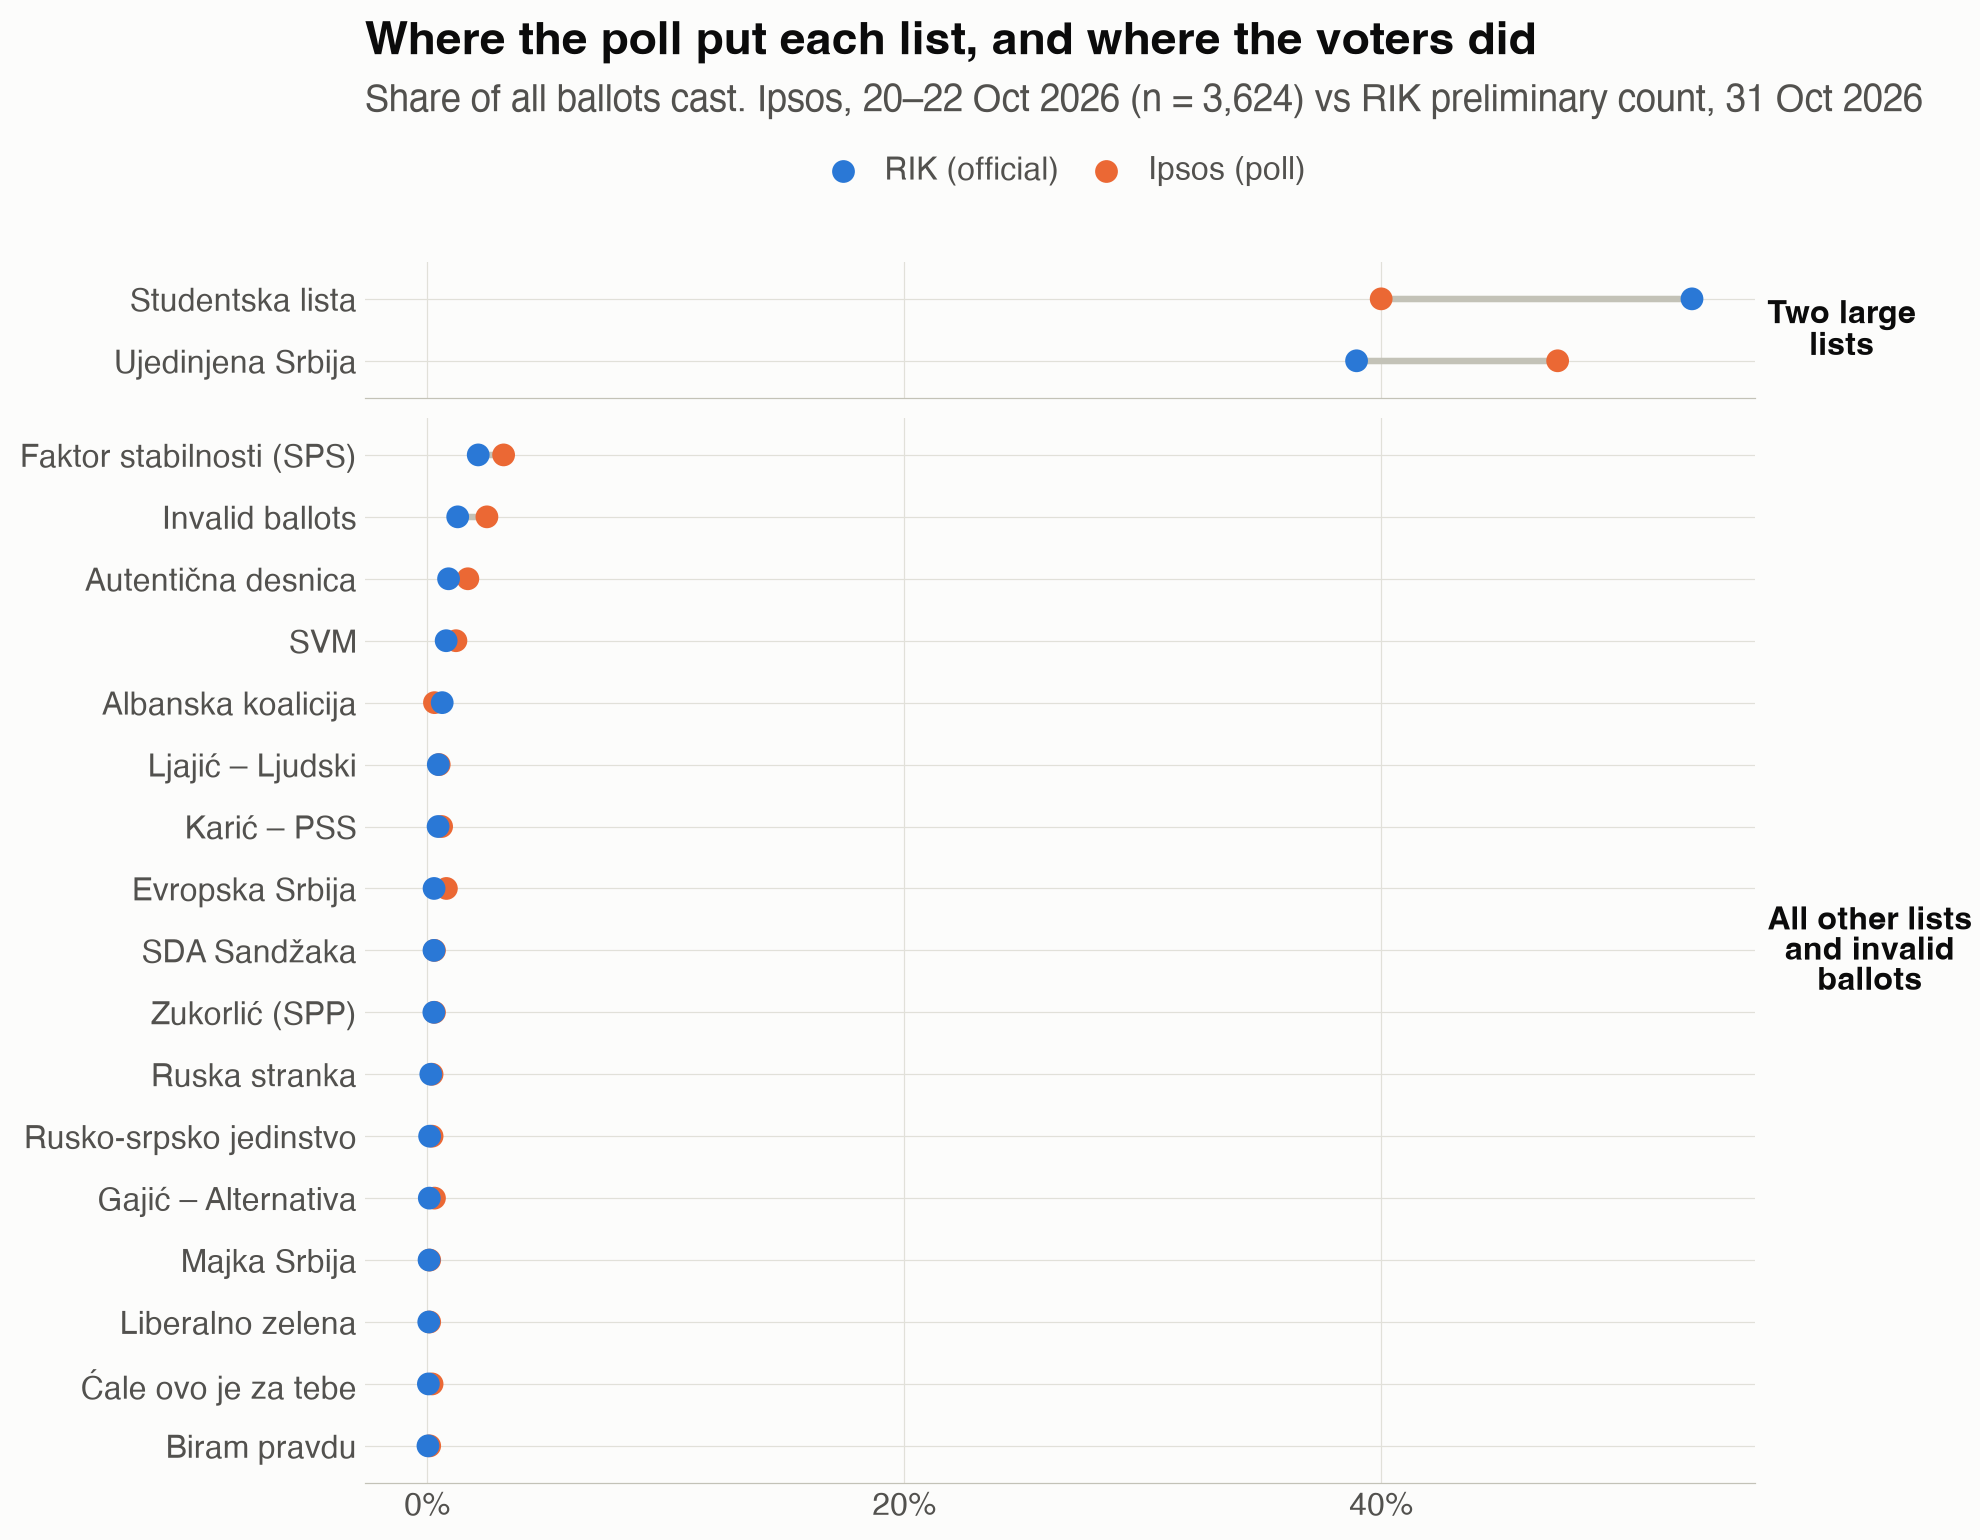

In [6]:
# ---- chunk: fig-dumbbell ----
cmp = ipsos[["short", "group", "ipsos_pct"]].merge(rik[["short", "rik_pct"]], on="short")
cmp["panel"] = np.where(cmp["short"].isin(["Studentska lista", "Ujedinjena Srbija"]), "Two large\nlists", "All other lists\nand invalid\nballots")
cmp["panel"] = pd.Categorical(cmp["panel"], categories=["Two large\nlists", "All other lists\nand invalid\nballots"])
cmp["short"] = pd.Categorical(cmp["short"], categories=cmp.sort_values("rik_pct")["short"])   # reorder(short, rik_pct)

cmp_long = cmp.melt(id_vars=["short", "group", "panel"], value_vars=["ipsos_pct", "rik_pct"], var_name="source", value_name="pct")
cmp_long["source"] = pd.Categorical(cmp_long["source"].map({"ipsos_pct": "Ipsos (poll)", "rik_pct": "RIK (official)"}),
                                    categories=["RIK (official)", "Ipsos (poll)"])

g = (ggplot() +
     geom_segment(cmp, aes(x="ipsos_pct", xend="rik_pct", y="short", yend="short"), color="#c3c2b7", size=1.2) +
     geom_point(cmp_long, aes(x="pct", y="short", color="source"), size=3.2) +
     facet_grid("panel", scales="free", space="free") +
     scale_color_manual(values=col) +
     scale_x_continuous(labels=pct_lab) +
     labs(x="", y="", title="Where the poll put each list, and where the voters did",
          subtitle="Share of all ballots cast. Ipsos, 20–22 Oct 2026 (n = 3,624) vs RIK preliminary count, 31 Oct 2026") +
     theme_report(figure_size=(9, 7)) +
     theme(strip_text_y=element_text(rotation=0, ha="left")))
fig(g, "Figure 1. Ipsos estimate (orange) versus official result (blue) for every electoral list and for invalid ballots. The panels use different horizontal scales.")

In [7]:
md(f"""
<div class="callout callout-result">
<b>What Figure 1 shows.</b> For each of the sixteen small lists and for invalid ballots, Ipsos was within about a point and a quarter of the result, and its estimates for the four minority lists that won seats (SVM, Albanska koalicija, Ljajić, SDA Sandžaka) were close. But the small misses all point the same way: Ipsos put nearly every small list, and invalid ballots, somewhat <i>above</i> their eventual share, so that collectively the small lists and invalid ballots were overestimated by about {cmp.loc[~cmp.short.isin(["Studentska lista","Ujedinjena Srbija"]), "ipsos_pct"].sum() - cmp.loc[~cmp.short.isin(["Studentska lista","Ujedinjena Srbija"]), "rik_pct"].sum():.1f} points. The bulk of the miss, though, is in the two large lists: Ipsos had <i>Ujedinjena Srbija</i> <b>{47.4 - cmp.loc[cmp.short == "Ujedinjena Srbija", "rik_pct"].iloc[0]:.1f} points too high</b> and <i>Studentska lista</i> <b>{cmp.loc[cmp.short == "Studentska lista", "rik_pct"].iloc[0] - 40:.1f} points too low</b>. One list deflated by thirteen points, with the difference spread over its rival and the small lists, is the signature we will be testing.
</div>
""")


<div class="callout callout-result">
<b>What Figure 1 shows.</b> For each of the sixteen small lists and for invalid ballots, Ipsos was within about a point and a quarter of the result, and its estimates for the four minority lists that won seats (SVM, Albanska koalicija, Ljajić, SDA Sandžaka) were close. But the small misses all point the same way: Ipsos put nearly every small list, and invalid ballots, somewhat <i>above</i> their eventual share, so that collectively the small lists and invalid ballots were overestimated by about 4.6 points. The bulk of the miss, though, is in the two large lists: Ipsos had <i>Ujedinjena Srbija</i> <b>8.4 points too high</b> and <i>Studentska lista</i> <b>13.0 points too low</b>. One list deflated by thirteen points, with the difference spread over its rival and the small lists, is the signature we will be testing.
</div>


# 4 Making the two sources comparable

## 4.1 Why this step matters

A probability calculation is only as good as the correspondence between the poll's categories and the population's categories. Two issues have to be settled before we can proceed.

**Issue 1: the denominator.** Ipsos's percentages include an assumed 2.5% invalid ballots and therefore refer to *all ballots cast*. RIK's percentages are also shares of all ballots in the boxes. The bases match. (Had they not, we would have had to rescale one of them, which would have been a small but necessary correction: e.g. 47.4 / 0.975 = 48.6% of *valid* votes.)

In [8]:
md(f"""
There is a subtlety here that matters for honesty about the model. The 2.5% is a number Ipsos *assumed* from past elections, not a share its respondents produced; nobody tells a pollster "I will spoil my ballot". Under the chance hypothesis it therefore has no sampling variability at all, and treating it as if it were a sampled count (as the all-ballots base does, because it sits inside the "Other" category) slightly overstates how surprising Ipsos's result is. The actual invalid share was {fmt_pct(100 * rik_meta["invalid"] / rik_meta["ballots"])}, so the assumption was {2.5 - 100 * rik_meta["invalid"] / rik_meta["ballots"]:.1f} points too high. We keep the all-ballots base as the main analysis because it is the base both sources publish, and in Section 8 we redo the key test on *valid votes only*, with the invalid share removed from both sides, to show how much that choice matters.

**Issue 2: how many categories to use.** A probability model with nineteen categories, most of them below 1%, is dominated by noise in the tiny lists and hard to read. The question of public interest is about the two large lists and, to a lesser extent, the minority lists that entered Parliament. We therefore define a compact **four-category scheme** as our main lens, and keep the full 19-category scheme as a secondary check.
""")


There is a subtlety here that matters for honesty about the model. The 2.5% is a number Ipsos *assumed* from past elections, not a share its respondents produced; nobody tells a pollster "I will spoil my ballot". Under the chance hypothesis it therefore has no sampling variability at all, and treating it as if it were a sampled count (as the all-ballots base does, because it sits inside the "Other" category) slightly overstates how surprising Ipsos's result is. The actual invalid share was 1.27%, so the assumption was 1.2 points too high. We keep the all-ballots base as the main analysis because it is the base both sources publish, and in Section 8 we redo the key test on *valid votes only*, with the invalid share removed from both sides, to show how much that choice matters.

**Issue 2: how many categories to use.** A probability model with nineteen categories, most of them below 1%, is dominated by noise in the tiny lists and hard to read. The question of public interest is about the two large lists and, to a lesser extent, the minority lists that entered Parliament. We therefore define a compact **four-category scheme** as our main lens, and keep the full 19-category scheme as a secondary check.


## 4.2 Scheme A: four categories

In [9]:
# ---- chunk: scheme-a ----
grp_levels = ["Studentska lista", "Ujedinjena Srbija", "Manjinske liste", "Other"]

scheme_a = (ipsos.groupby("group", as_index=False)["ipsos_pct"].sum()
            .merge(rik.groupby("group", as_index=False)[["votes", "kim", "abroad"]].sum(), on="group", how="outer"))
scheme_a["group"] = pd.Categorical(scheme_a["group"], categories=grp_levels)
scheme_a = scheme_a.sort_values("group").reset_index(drop=True)
scheme_a["rik_pct"] = 100 * scheme_a["votes"] / rik_meta["ballots"]
scheme_a["rik_p"]   = scheme_a["votes"] / rik_meta["ballots"]

p_rik_A   = pd.Series(scheme_a["rik_p"].values, index=grp_levels)
pct_ips_A = pd.Series(scheme_a["ipsos_pct"].values, index=grp_levels)

kable_report(pd.DataFrame({
    "Category": grp_levels,
    "Lists included": ["Studentska lista – Studenti pobeđuju", "Aleksandar Vučić – Ujedinjena Srbija",
                       "SVM, Albanska koalicija, Ljajić – Ljudski, SDA Sandžaka (the four lists that won seats)",
                       "The remaining 12 lists plus invalid ballots"],
    "RIK votes": scheme_a["votes"].map(fmt_n), "RIK %": scheme_a["rik_pct"].map(fmt_pct),
    "Ipsos %": scheme_a["ipsos_pct"].map(lambda x: fmt_pct(x, 1)),
    "Gap (Ipsos − RIK)": (scheme_a["ipsos_pct"] - scheme_a["rik_pct"]).map(lambda x: f"{x:+.1f}".replace("-", "−"))}),
    caption="Table 4. Scheme A: the four-category comparison that drives the main analysis.")

Category,Lists included,RIK votes,RIK %,Ipsos %,Gap (Ipsos − RIK)
Studentska lista,Studentska lista – Studenti pobeđuju,"2,349,777",53.03%,40.0%,−13.0
Ujedinjena Srbija,Aleksandar Vučić – Ujedinjena Srbija,"1,726,554",38.97%,47.4%,+8.4
Manjinske liste,"SVM, Albanska koalicija, Ljajić – Ljudski, SDA Sandžaka (the four lists that won seats)","95,481",2.16%,2.3%,+0.1
Other,The remaining 12 lists plus invalid ballots,"258,847",5.84%,10.3%,+4.5


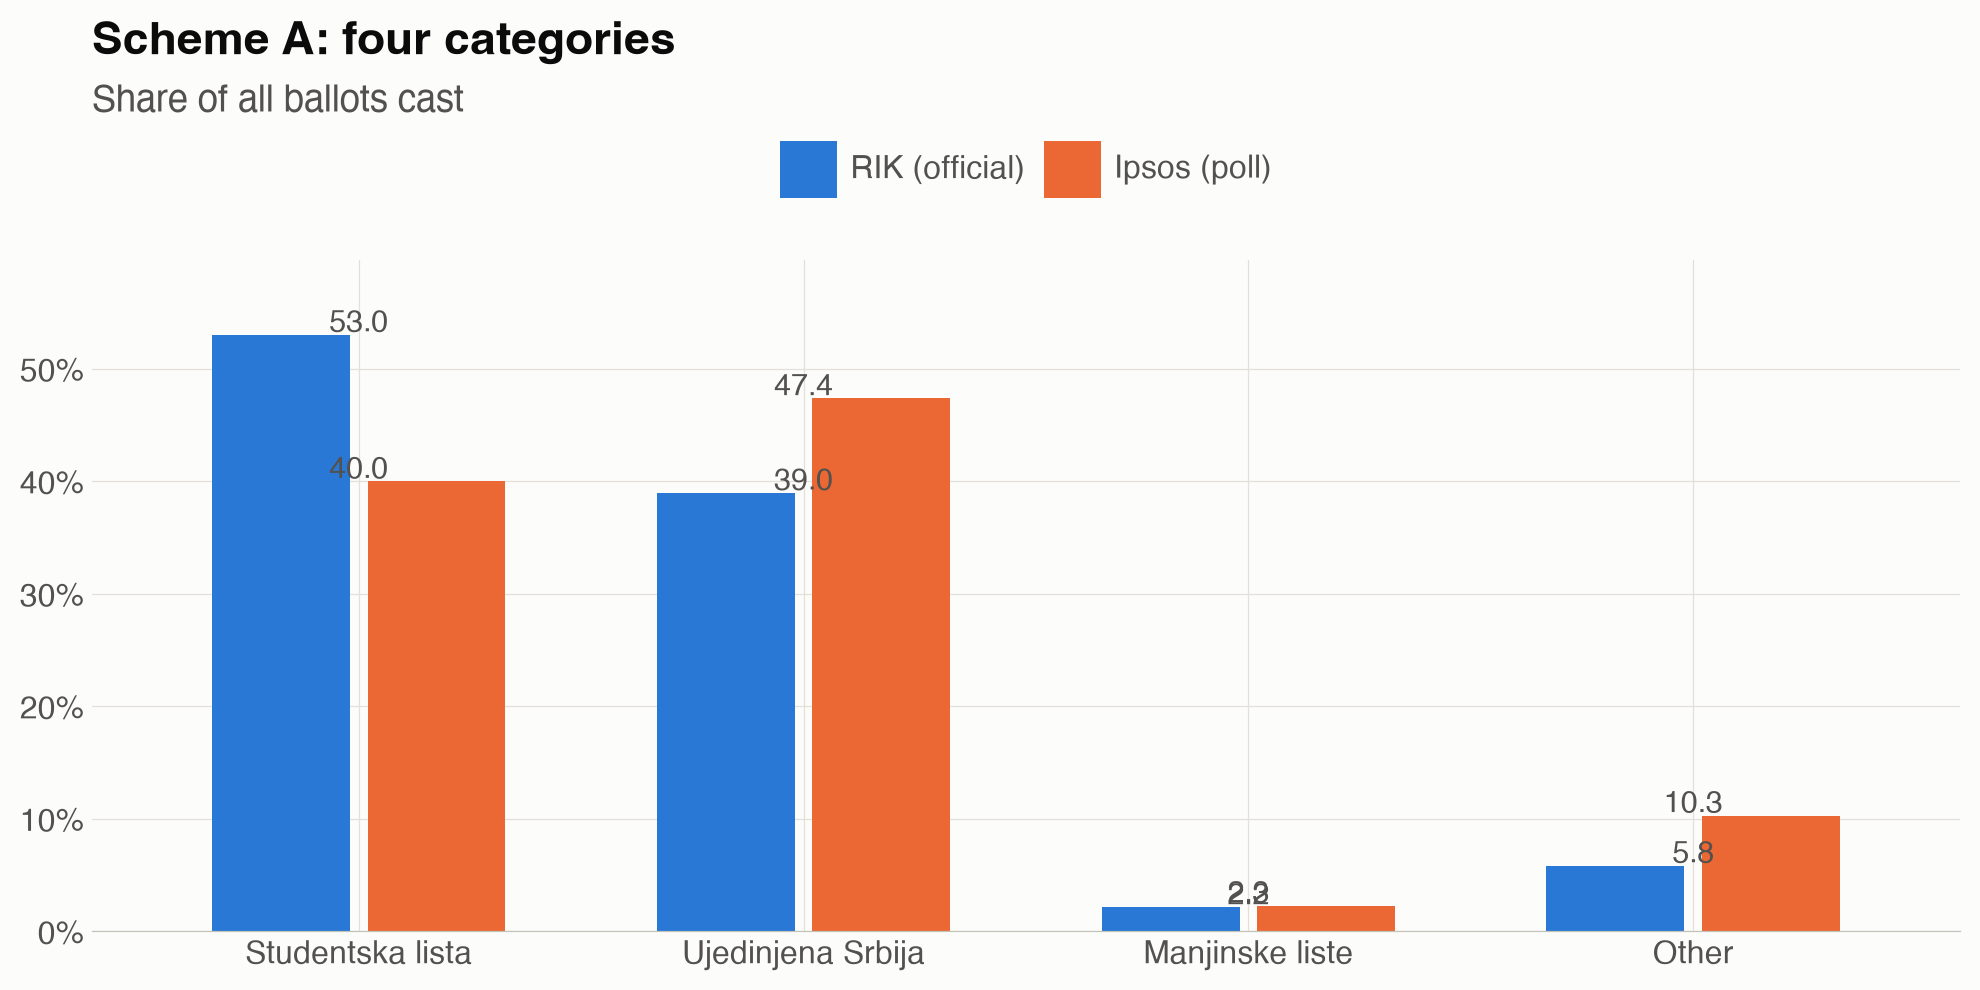

In [10]:
# ---- chunk: fig-scheme-a ----
sa_long = scheme_a.melt(id_vars="group", value_vars=["ipsos_pct", "rik_pct"], var_name="source", value_name="pct")
sa_long["source"] = pd.Categorical(sa_long["source"].map({"ipsos_pct": "Ipsos (poll)", "rik_pct": "RIK (official)"}),
                                   categories=["RIK (official)", "Ipsos (poll)"])
sa_long["lbl"] = sa_long["pct"].map(lambda x: f"{x:.1f}")
g = (ggplot(sa_long, aes(x="group", y="pct", fill="source")) +
     geom_col(position=position_dodge(width=0.7), width=0.62) +
     geom_text(aes(label="lbl"), position=position_dodge(width=0.7), nudge_y=1.2, size=10, color="#52514e") +
     scale_fill_manual(values=col) +
     scale_y_continuous(labels=pct_lab, expand=(0, 0, 0.1, 0)) +
     labs(x="", y="", title="Scheme A: four categories", subtitle="Share of all ballots cast") +
     theme_report(figure_size=(9, 4.5)))
fig(g, "Figure 2. The four-category comparison. Ipsos (orange) against RIK (blue).")

## 4.3 Scheme B: all nineteen categories

For completeness we also keep every list (and invalid ballots) as its own category. This scheme is used in Section 7 as a robustness check.

In [11]:
# ---- chunk: scheme-b ----
scheme_b = rik[["short", "group", "votes"]].merge(ipsos[["short", "ipsos_pct"]], on="short")
scheme_b["rik_p"] = scheme_b["votes"] / rik_meta["ballots"]
p_rik_B   = pd.Series(scheme_b["rik_p"].values, index=scheme_b["short"])
pct_ips_B = pd.Series(scheme_b["ipsos_pct"].values, index=scheme_b["short"])
assert abs(p_rik_B.sum() - 1) < 1e-12 and abs(pct_ips_B.sum() - 100) < 1e-9

In [12]:
md(f"""
<div class="callout callout-result">
<b>Result of this step.</b> In Scheme A, Ipsos had <i>Studentska lista</i> at 40.0% against a true {fmt_pct(scheme_a.rik_pct[0])}, and <i>Ujedinjena Srbija</i> at 47.4% against a true {fmt_pct(scheme_a.rik_pct[1])}. The minority bloc ({scheme_a.ipsos_pct[2]:.1f}% vs {fmt_pct(scheme_a.rik_pct[2])}) is essentially right. The residual category ({scheme_a.ipsos_pct[3]:.1f}% vs {fmt_pct(scheme_a.rik_pct[3])}) is overstated by {scheme_a.ipsos_pct[3] - scheme_a.rik_pct[3]:.1f} points; smaller than the two headline errors, but, as we will see, far from negligible in its own right. From here on, "the Ipsos result" means the four-number vector ({", ".join(f"{x:.1f}" for x in scheme_a.ipsos_pct)}) and "the population" means the vector ({", ".join(f"{x:.2f}" for x in scheme_a.rik_pct)}).
</div>
""")


<div class="callout callout-result">
<b>Result of this step.</b> In Scheme A, Ipsos had <i>Studentska lista</i> at 40.0% against a true 53.03%, and <i>Ujedinjena Srbija</i> at 47.4% against a true 38.97%. The minority bloc (2.3% vs 2.16%) is essentially right. The residual category (10.3% vs 5.84%) is overstated by 4.5 points; smaller than the two headline errors, but, as we will see, far from negligible in its own right. From here on, "the Ipsos result" means the four-number vector (40.0, 47.4, 2.3, 10.3) and "the population" means the vector (53.03, 38.97, 2.16, 5.84).
</div>


# 5 The multinomial distribution

## 5.1 Why we need a probability model

Polls are never exactly right, even when they are perfectly executed. If you ask 2,000 randomly chosen voters, you will not get exactly 53.0% for a list whose true support is 53.0%; you might get 51.8% or 54.3%. The question is never "did the poll miss?" but "**did it miss by more than chance can explain?**" To answer that, we need to know how much variation chance *does* produce in a sample of a given size. That is what a probability model provides.

<div class="concept">
<h4>Concept: the multinomial distribution</h4>

Imagine an urn containing millions of balls in four colours, in exactly the proportions of the RIK result: 53.0% blue (<i>Studentska lista</i>), 39.0% orange (<i>Ujedinjena Srbija</i>), 2.2% aqua (<i>manjinske liste</i>), 5.8% grey (everything else). You draw <i>n</i> balls at random and count how many of each colour you got.

The <b>multinomial distribution</b> gives the probability of every possible count vector (so many blue, so many orange, …) for given <i>n</i> and given proportions. It is the direct generalisation of the coin-flip (binomial) distribution to more than two outcomes. A random-sample poll of <i>n</i> decided voters is, mathematically, exactly this urn experiment, with "true vote share" playing the role of the colour proportions.

Two facts about it matter here:

<ul>
<li>The <b>expected</b> count for each category is simply <i>n</i> × (its proportion).</li>
<li>The <b>typical spread</b> (standard deviation) of a category's count is √(<i>n</i> · <i>p</i> · (1 − <i>p</i>)). For a share near 50% and <i>n</i> = 2,000, that is about 22 counts, i.e. about <b>1.1 percentage points</b>. Random polls of that size therefore land within roughly ±2 points of the truth about 95% of the time, which is where the familiar "margin of error" comes from.</li>
</ul>

<i>Further reading:</i> Wikipedia on the <a href="https://en.wikipedia.org/wiki/Multinomial_distribution">multinomial</a> and <a href="https://en.wikipedia.org/wiki/Binomial_distribution">binomial</a> distributions · the interactive <a href="https://seeing-theory.brown.edu/probability-distributions/index.html">Seeing Theory, ch. 3 "Probability Distributions"</a> · Blitzstein &amp; Hwang, <a href="http://probabilitybook.net"><i>Introduction to Probability</i></a> (free textbook; the multinomial is in ch. 7) · <a href="https://mathworld.wolfram.com/MultinomialDistribution.html">Wolfram MathWorld</a> for the formulas, including the covariance between categories. See also <a href="#references">References</a>.
</div>

## 5.2 Seeing it: what random polls from the real electorate look like

The most intuitive way to understand the model is to simulate it. Below we draw 100,000 imaginary polls, each a random sample of 2,000 decided voters from the actual RIK electorate (we will justify the precise sample size in the next section), and look at the distribution of the *Studentska lista* and *Ujedinjena Srbija* shares they produce.

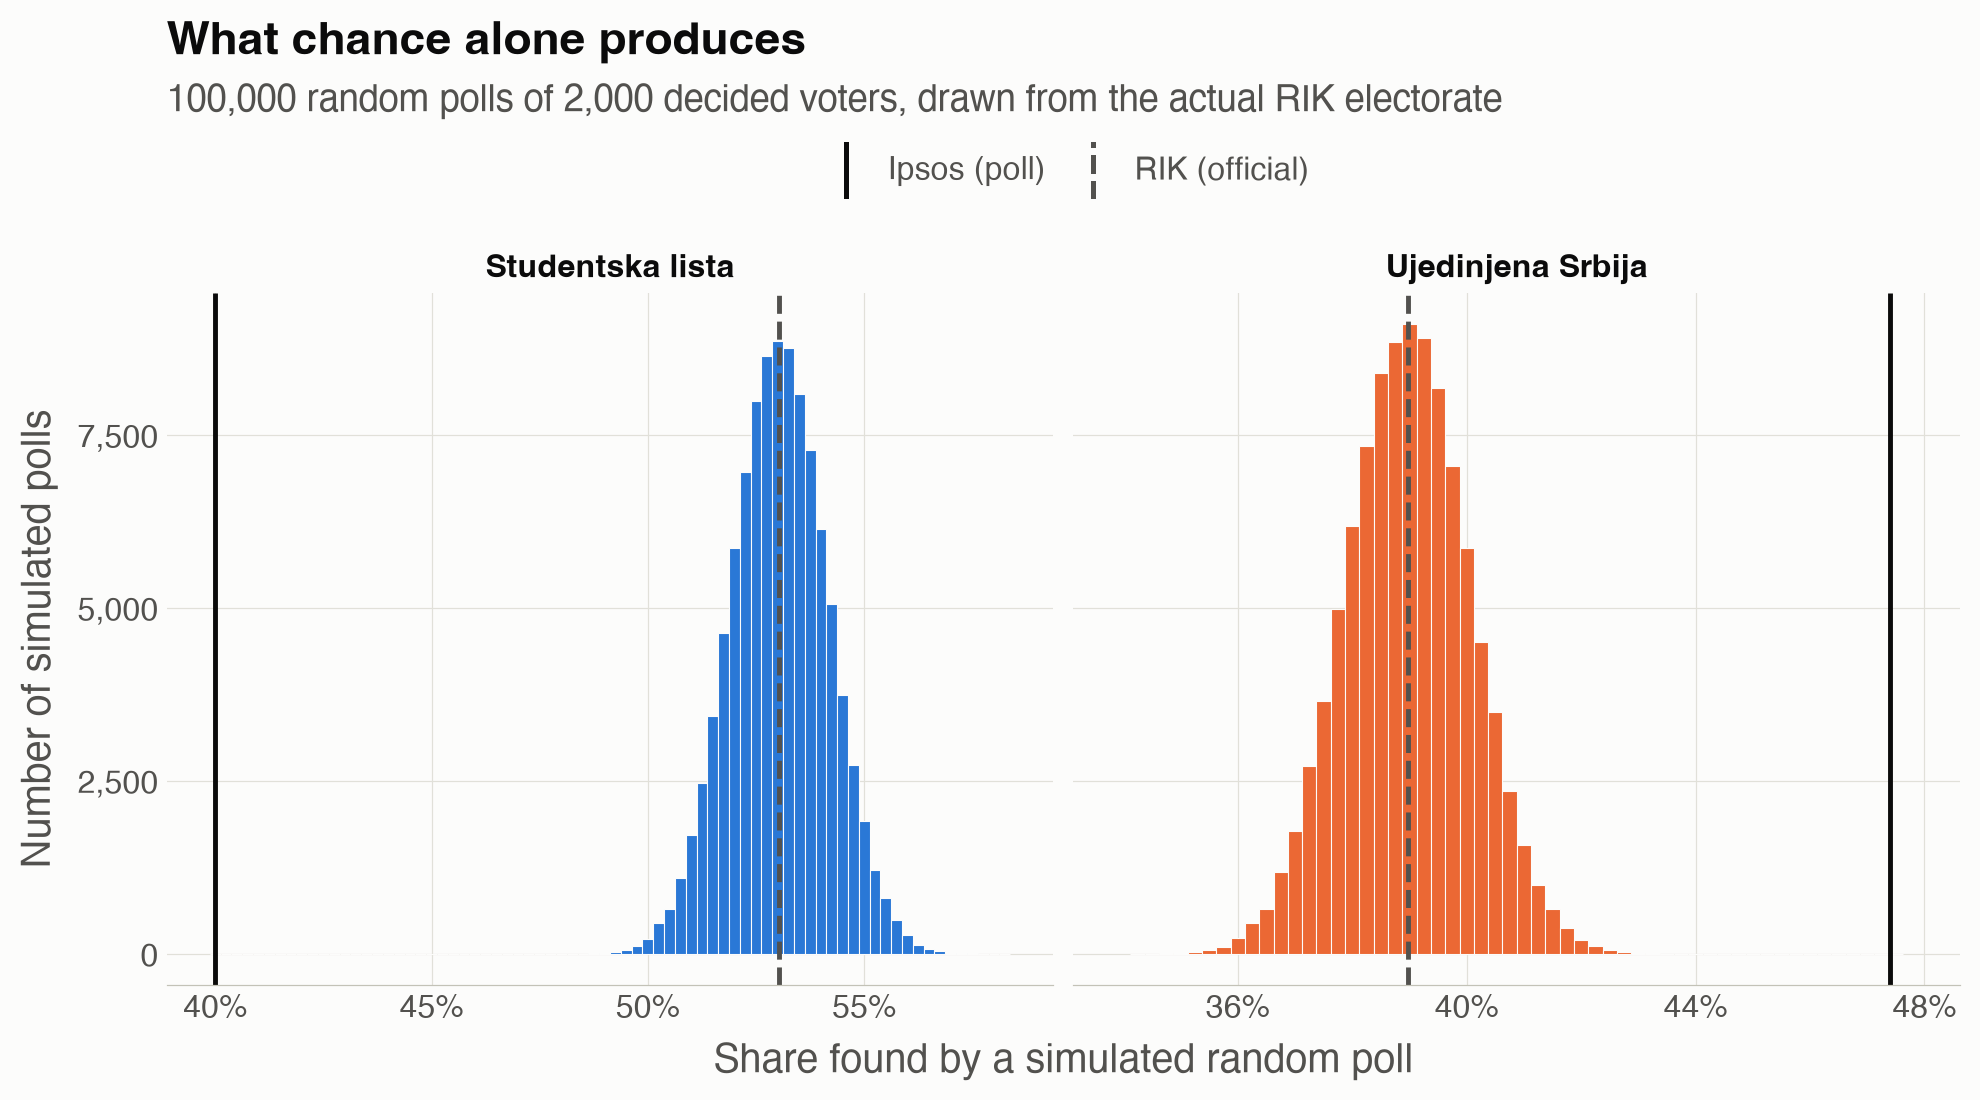

In [13]:
# ---- chunk: fig-sim-intro ----
rng_demo = np.random.default_rng(2026)
n_demo = 2000
sim_demo = rng_demo.multinomial(n_demo, p_rik_A.values, size=100_000).T      # categories × polls, as rmultinom
sim_df = pd.DataFrame({"Studentska lista":  100 * sim_demo[0] / n_demo,
                       "Ujedinjena Srbija": 100 * sim_demo[1] / n_demo}).melt(var_name="group", value_name="pct")

ref_lines = pd.DataFrame({"group": ["Studentska lista", "Ujedinjena Srbija"] * 2,
                          "what":  ["RIK (official)"] * 2 + ["Ipsos (poll)"] * 2,
                          "x":     list(100 * p_rik_A.values[:2]) + list(pct_ips_A.values[:2])})

g = (ggplot(sim_df, aes(x="pct")) +
     geom_histogram(aes(fill="group"), binwidth=0.25, color="#fcfcfb", size=0.2) +
     geom_vline(ref_lines, aes(xintercept="x", linetype="what", color="what"), size=0.9) +
     facet_wrap("group", scales="free_x") +
     scale_fill_manual(values=col, guide=None) +
     # the histograms carry the list colours, so the reference lines are kept neutral
     scale_color_manual(values={"RIK (official)": "#52514e", "Ipsos (poll)": "#0b0b0b"}) +
     scale_linetype_manual(values={"RIK (official)": "dashed", "Ipsos (poll)": "solid"}) +
     scale_x_continuous(labels=pct_lab, expand=(0, 1)) +
     scale_y_continuous(labels=comma) +
     labs(x="Share found by a simulated random poll", y="Number of simulated polls",
          title="What chance alone produces",
          subtitle="100,000 random polls of 2,000 decided voters, drawn from the actual RIK electorate") +
     theme_report(figure_size=(9, 5)))
fig(g, "Figure 3. Shares obtained by 100,000 simulated random polls of 2,000 decided voters from the actual electorate (RIK proportions). Histograms in each list's colour; the dashed line marks the true value, the solid black line what Ipsos published.")

In [14]:
# ---- chunk: sim-intro-range ----
rng = sim_df.groupby("group")["pct"].agg(lo="min", hi="max", sd="std").reset_index()

In [15]:
md(f"""
<div class="callout callout-result">
<b>What Figure 3 shows.</b> Across 100,000 random polls, the <i>Studentska lista</i> share never fell below <b>{rng.loc[rng.group == "Studentska lista", "lo"].iloc[0]:.2f}%</b> and the <i>Ujedinjena Srbija</i> share never rose above <b>{rng.loc[rng.group == "Ujedinjena Srbija", "hi"].iloc[0]:.2f}%</b>. Ipsos's 40.0% and 47.4% are not in the tails of these distributions; they lie far outside everything that chance produced in a hundred thousand tries. The standard deviation of a simulated poll's share is about {rng.sd.iloc[0]:.1f} points, so Ipsos's figures sit roughly {(100 * p_rik_A.iloc[0] - 40) / rng.loc[rng.group == "Studentska lista", "sd"].iloc[0]:.0f} and {(47.4 - 100 * p_rik_A.iloc[1]) / rng.loc[rng.group == "Ujedinjena Srbija", "sd"].iloc[0]:.0f} standard deviations away from the truth. Everything that follows puts exact numbers on this picture.
</div>
""")


<div class="callout callout-result">
<b>What Figure 3 shows.</b> Across 100,000 random polls, the <i>Studentska lista</i> share never fell below <b>48.00%</b> and the <i>Ujedinjena Srbija</i> share never rose above <b>44.15%</b>. Ipsos's 40.0% and 47.4% are not in the tails of these distributions; they lie far outside everything that chance produced in a hundred thousand tries. The standard deviation of a simulated poll's share is about 1.1 points, so Ipsos's figures sit roughly 12 and 8 standard deviations away from the truth. Everything that follows puts exact numbers on this picture.
</div>


# 6 How big was Ipsos's sample, really?

## 6.1 Why this is the crux

The probability of Ipsos's result depends enormously on the sample size *n*: the larger the sample, the smaller the chance of a given miss. Ipsos reports **3,624 respondents**, but its list percentages were computed only among the **decided** respondents (those who named a list), and the number of decided respondents is **not published**. Using 3,624 would overstate the precision of the poll and make our conclusion unfairly harsh.

Fortunately, Ipsos published 95% confidence intervals for every list, and a confidence interval is a function of the sample size. We can therefore **reverse-engineer the sample size that Ipsos itself was using** when it computed those intervals.

<div class="concept">
<h4>Concept: confidence intervals, standard error and effective sample size</h4>

For a share <i>p</i> estimated from <i>n</i> random respondents, the <b>standard error</b> is SE = √(<i>p</i>(1 − <i>p</i>)/<i>n</i>), and a 95% confidence interval is roughly <i>p</i> ± 1.96 × SE. Turned around: if a pollster reports an interval of half-width <i>h</i> for a share <i>p</i>, the sample size implied by that interval is

<p style="margin-left:2em"><i>n</i><sub>eff</sub> = <i>p</i>(1 − <i>p</i>) / (<i>h</i> / 1.96)².</p>

We call this the <b>effective sample size</b>. It can be smaller than the number of interviews for two legitimate reasons: (1) only part of the sample is in the base (here, the decided), and (2) weighting a sample to match population demographics inflates its variance; the inflation factor is called the <b>design effect</b>. A professional pollster's published intervals already incorporate both, so <i>n</i><sub>eff</sub> is the right <i>n</i> to use in our multinomial model. Using it is also the <b>charitable</b> choice: a smaller <i>n</i> means more room for chance, and so a higher probability for Ipsos's result.

<i>Further reading:</i> Wikipedia on the <a href="https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval">confidence interval for a proportion</a>, the <a href="https://en.wikipedia.org/wiki/Margin_of_error">margin of error</a> and the <a href="https://en.wikipedia.org/wiki/Design_effect">design effect</a> · the interactive <a href="https://seeing-theory.brown.edu/frequentist-inference/index.html">Seeing Theory, ch. 4 "Frequentist Inference"</a> for what a confidence interval really promises · Pew Research Center, <a href="https://www.pewresearch.org/short-reads/2016/09/08/understanding-the-margin-of-error-in-election-polls/"><i>Understanding the margin of error in election polls</i></a> · Zipf &amp; Valliant, <a href="https://cran.r-project.org/web/packages/PracTools/vignettes/Design-effects.html"><i>Design Effects and Effective Sample Size</i></a> (the clearest free treatment of <i>n</i><sub>eff</sub> = <i>n</i> / deff and of Kish's weighting formula).
</div>

## 6.2 Backing out the effective sample size from Ipsos's own intervals

In [16]:
# ---- chunk: neff ----
neff_tbl = ipsos[ipsos["ci_lo"].notna() & (ipsos["ipsos_pct"] >= 0.5)].copy()     # tiny shares are rounded too coarsely to be informative
neff_tbl["p"] = neff_tbl["ipsos_pct"] / 100
neff_tbl["half_width"] = (neff_tbl["ci_hi"] - neff_tbl["ci_lo"]) / 2 / 100
neff_tbl["n_eff"] = neff_tbl["p"] * (1 - neff_tbl["p"]) / (neff_tbl["half_width"] / 1.96) ** 2
neff_tbl = neff_tbl.sort_values("ipsos_pct", ascending=False).reset_index(drop=True)

_t = {k: v / 100 for k, v in ipsos_turnout.items()}
n_turnout_eff = _t["est"] * (1 - _t["est"]) / (((_t["hi"] - _t["lo"]) / 2) / 1.96) ** 2
deff_full = ipsos_n / n_turnout_eff

n_primary = int(round(neff_tbl["n_eff"].median(), -1))

kable_report(pd.DataFrame({"Electoral list": neff_tbl["short"], "Ipsos %": neff_tbl["ipsos_pct"].map(lambda x: fmt_pct(x, 1)),
                           "95% interval": [f"{lo:.1f} – {hi:.1f}" for lo, hi in zip(neff_tbl["ci_lo"], neff_tbl["ci_hi"])],
                           "Half-width (pts)": (neff_tbl["half_width"] * 100).map(lambda x: f"{x:.1f}"),
                           "Implied n<sub>eff</sub>": neff_tbl["n_eff"].map(fmt_n)}),
             caption="Table 5. Effective sample size implied by each of Ipsos's published confidence intervals (lists at 0.5% or more).")

Electoral list,Ipsos %,95% interval,Half-width (pts),Implied neff
Ujedinjena Srbija,47.4%,45.3 – 49.5,2.1,"2,172"
Studentska lista,40.0%,37.9 – 42.1,2.1,"2,091"
Faktor stabilnosti (SPS),3.2%,2.5 – 3.9,0.7,"2,429"
Autentična desnica,1.7%,1.1 – 2.3,0.6,"1,783"
SVM,1.2%,0.7 – 1.7,0.5,"1,822"
Evropska Srbija,0.8%,0.4 – 1.2,0.4,"1,905"
Karić – PSS,0.6%,0.3 – 0.9,0.3,"2,546"
Ljajić – Ljudski,0.5%,0.2 – 0.8,0.3,"2,124"


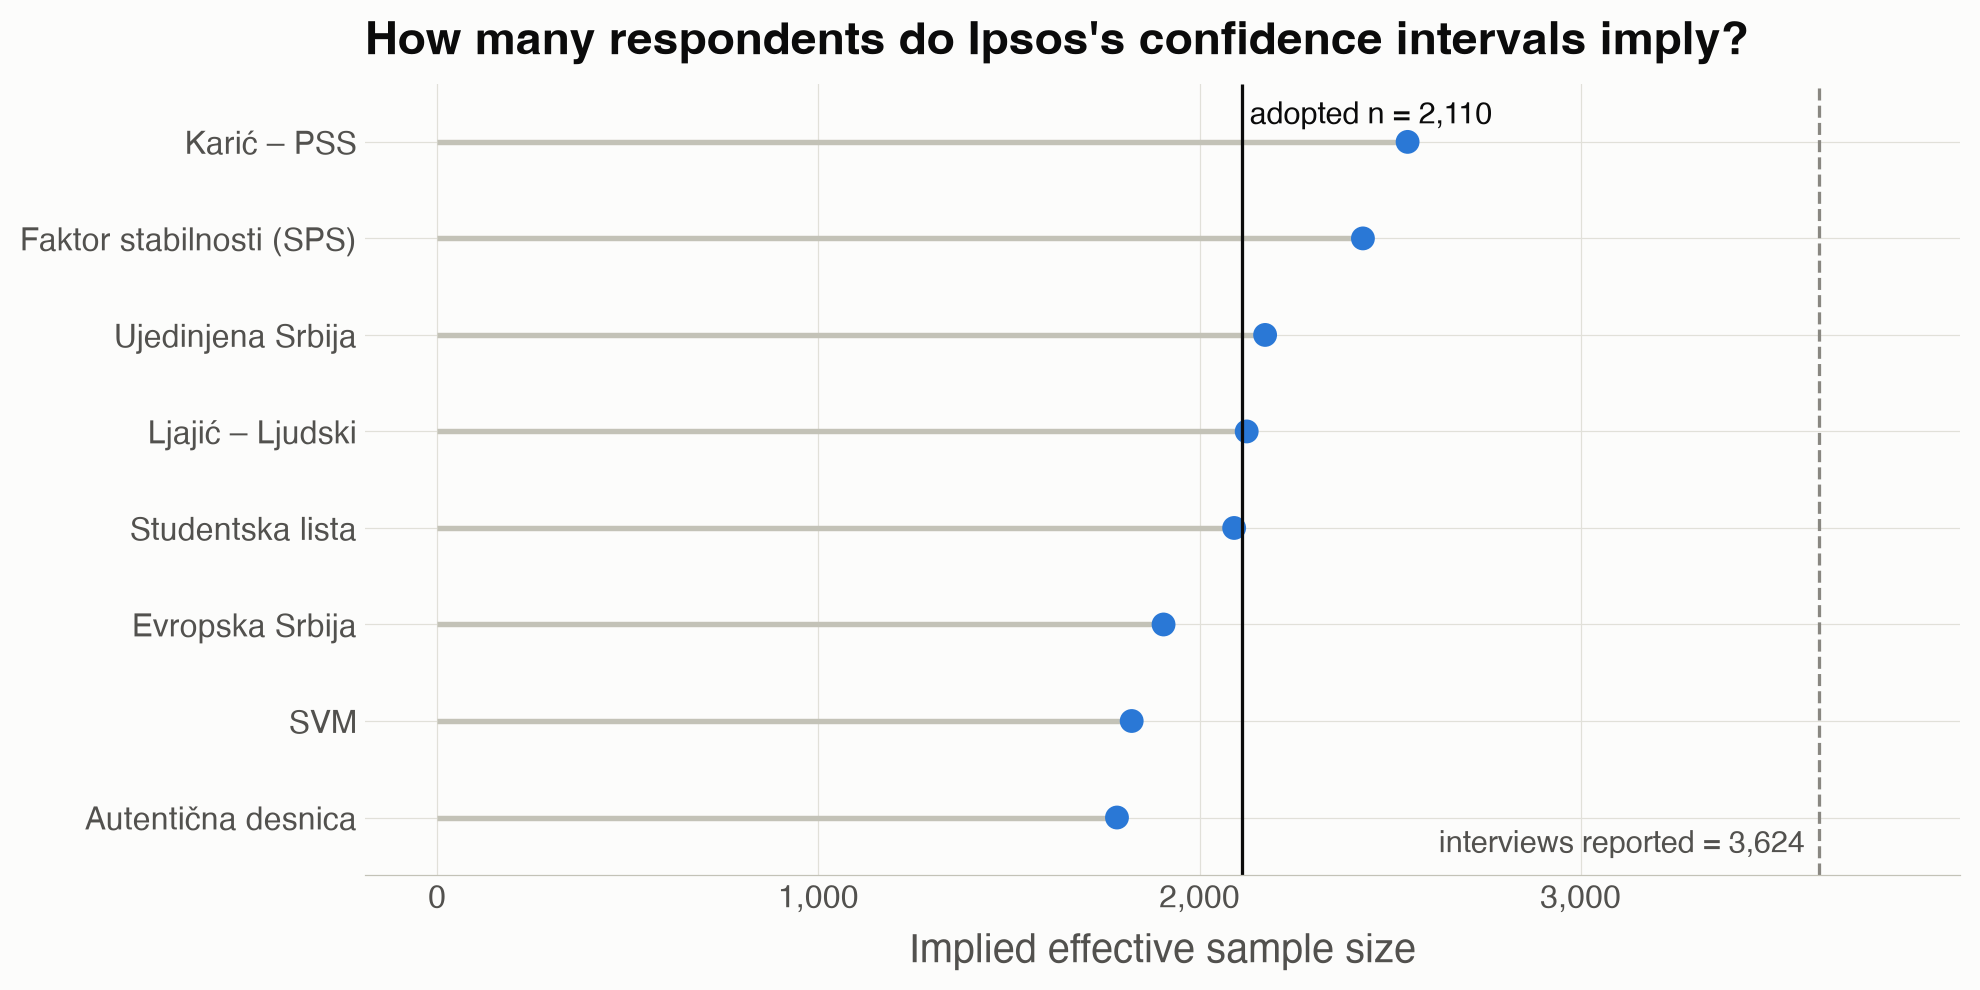

In [17]:
# ---- chunk: fig-neff ----
nt = neff_tbl.copy()
nt["short"] = pd.Categorical(nt["short"], categories=nt.sort_values("n_eff")["short"])   # reorder(short, n_eff)
g = (ggplot(nt, aes(x="short", y="n_eff")) +
     geom_segment(aes(xend="short", y=0, yend="n_eff"), color="#c3c2b7", size=1) +
     geom_point(size=3.4, color="#2a78d6") +
     geom_hline(yintercept=n_primary, color="#0b0b0b", size=0.6) +
     geom_hline(yintercept=ipsos_n, color="#898781", linetype="dashed", size=0.6) +
     annotate("text", x=len(nt) + 0.45, y=n_primary * 1.01, label=f"adopted n = {fmt_n(n_primary)}", ha="left", va="top", size=10, color="#0b0b0b") +
     annotate("text", x=0.55, y=ipsos_n * 0.99, label=f"interviews reported = {fmt_n(ipsos_n)}", ha="right", va="bottom", size=10, color="#52514e") +
     coord_flip() +
     scale_y_continuous(labels=comma, limits=(0, ipsos_n * 1.05)) +
     labs(x="", y="Implied effective sample size", title="How many respondents do Ipsos's confidence intervals imply?") +
     theme_report(figure_size=(9, 4.5)))
fig(g, "Figure 4. Effective sample size implied by each published interval. The solid line is the median, which we adopt as the primary n; the dashed line is the number of interviews Ipsos reports.")

In [18]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> Ipsos's intervals imply an effective sample size of about <b>{fmt_n(neff_tbl.n_eff.min())} to {fmt_n(neff_tbl.n_eff.max())}</b>, with a median of <b>{fmt_n(n_primary)}</b>. The two large lists, whose intervals are least affected by rounding, give {fmt_n(neff_tbl.loc[neff_tbl.short == "Ujedinjena Srbija", "n_eff"].iloc[0])} and {fmt_n(neff_tbl.loc[neff_tbl.short == "Studentska lista", "n_eff"].iloc[0])}; the smaller lists scatter more widely only because their interval bounds are published to one decimal place, which is coarse relative to their width. This is far below the 3,624 interviews, and it is internally consistent: the turnout interval, which Ipsos says was computed on the <i>whole</i> sample, implies <i>n</i><sub>eff</sub> ≈ {fmt_n(n_turnout_eff)}, i.e. a design effect of about {deff_full:.2f} on the full sample. Applying that design effect to a decided base of 60–80% of respondents gives {fmt_n(0.6 * ipsos_n / deff_full)}–{fmt_n(0.8 * ipsos_n / deff_full)}; the adopted {fmt_n(n_primary)} corresponds to a decided base of about {100 * n_primary * deff_full / ipsos_n:.0f}%, a plausible figure three days before an election.

We therefore adopt <b>n = {fmt_n(n_primary)}</b> as the primary sample size. It is the figure Ipsos's own published precision supports, and it is the most generous choice for Ipsos. In Section 8 we repeat everything for a range of sample sizes, from a deliberately low 1,500 up to the full 3,624, to show that the conclusion does not depend on this choice.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> Ipsos's intervals imply an effective sample size of about <b>1,783 to 2,546</b>, with a median of <b>2,110</b>. The two large lists, whose intervals are least affected by rounding, give 2,172 and 2,091; the smaller lists scatter more widely only because their interval bounds are published to one decimal place, which is coarse relative to their width. This is far below the 3,624 interviews, and it is internally consistent: the turnout interval, which Ipsos says was computed on the <i>whole</i> sample, implies <i>n</i><sub>eff</sub> ≈ 2,708, i.e. a design effect of about 1.34 on the full sample. Applying that design effect to a decided base of 60–80% of respondents gives 1,625–2,166; the adopted 2,110 corresponds to a decided base of about 78%, a plausible figure three days before an election.

We therefore adopt <b>n = 2,110</b> as the primary sample size. It is the figure Ipsos's own published precision supports, and it is the most generous choice for Ipsos. In Section 8 we repeat everything for a range of sample sizes, from a deliberately low 1,500 up to the full 3,624, to show that the conclusion does not depend on this choice.
</div>


# 7 The probability of Ipsos's result

## 7.1 Setting up the hypothesis

We now have everything needed to state the test precisely.

In [19]:
md(f"""
- **Population:** the RIK four-category proportions, **p** = ({", ".join(f"{x:.4f}" for x in p_rik_A)}).
- **Sample size:** *n* = {fmt_n(n_primary)}.
- **Observed result:** Ipsos's percentages ({", ".join(f"{x:.1f}" for x in pct_ips_A)}), converted to integer counts out of *n*. These counts are a *construction*: Ipsos did not interview exactly {fmt_n(n_primary)} decided people. The multinomial with *n*<sub>eff</sub> is the standard way of representing a weighted sample whose precision is that of {fmt_n(n_primary)} simple random respondents; it matches the spread of Ipsos's own intervals, which is what matters for the test.
- **Hypothesis H₀:** the observed counts are a random draw from Multinomial(*n*, **p**).
""")


- **Population:** the RIK four-category proportions, **p** = (0.5303, 0.3897, 0.0216, 0.0584).
- **Sample size:** *n* = 2,110.
- **Observed result:** Ipsos's percentages (40.0, 47.4, 2.3, 10.3), converted to integer counts out of *n*. These counts are a *construction*: Ipsos did not interview exactly 2,110 decided people. The multinomial with *n*<sub>eff</sub> is the standard way of representing a weighted sample whose precision is that of 2,110 simple random respondents; it matches the spread of Ipsos's own intervals, which is what matters for the test.
- **Hypothesis H₀:** the observed counts are a random draw from Multinomial(*n*, **p**).


In [20]:
# ---- chunk: ipsos-counts ----
k_ips_A = pd.Series(pct_to_counts(pct_ips_A.values, n_primary, remainder_to=3), index=grp_levels)   # any rounding remainder goes to "Other"
expected_A = n_primary * p_rik_A
sd_A = np.sqrt(n_primary * p_rik_A * (1 - p_rik_A))

kable_report(pd.DataFrame({"Category": grp_levels,
                           "Ipsos count (out of n)": k_ips_A.map(fmt_n).values,
                           "Expected under H₀": expected_A.map(lambda x: f"{x:,.1f}").values,
                           "Difference": (k_ips_A - expected_A).map(lambda x: f"{x:+.0f}").values,
                           "In standard deviations": ((k_ips_A - expected_A) / sd_A).map(lambda x: f"{x:+.1f}").values}),
             caption=f"Table 6. Ipsos's result as counts out of n = {fmt_n(n_primary)}, against what the RIK electorate would produce on average.")

Category,Ipsos count (out of n),Expected under H₀,Difference,In standard deviations
Studentska lista,844,"1,119.0",-275,-12.0
Ujedinjena Srbija,"1,000",822.2,+178,+7.9
Manjinske liste,49,45.5,+4,+0.5
Other,217,123.3,+94,+8.7


In [21]:
md(f"""
Already in this table the key quantity appears: the *Studentska lista* count is about **{abs(k_ips_A.iloc[0] - expected_A.iloc[0]) / sd_A.iloc[0]:.0f} standard deviations** below expectation and the *Ujedinjena Srbija* count about **{(k_ips_A.iloc[1] - expected_A.iloc[1]) / sd_A.iloc[1]:.0f} standard deviations** above it; even the residual "Other" category is about {(k_ips_A.iloc[3] - expected_A.iloc[3]) / sd_A.iloc[3]:.0f} standard deviations too high. ("Sigma" is shorthand for one standard deviation.) For comparison, a one-sided "2-sigma" event happens about 1 time in 40, a "5-sigma" event (the particle-physics discovery standard) about 1 time in 3.5 million.
""")


Already in this table the key quantity appears: the *Studentska lista* count is about **12 standard deviations** below expectation and the *Ujedinjena Srbija* count about **8 standard deviations** above it; even the residual "Other" category is about 9 standard deviations too high. ("Sigma" is shorthand for one standard deviation.) For comparison, a one-sided "2-sigma" event happens about 1 time in 40, a "5-sigma" event (the particle-physics discovery standard) about 1 time in 3.5 million.


## 7.2 Why "the probability of exactly this result" is the wrong question

<div class="concept">
<h4>Concept: point probability versus tail probability</h4>

With four categories and 2,000-odd respondents there are over a billion possible count vectors, so the probability of <b>any one exact vector</b> is tiny, even for the single most likely one. A poll that hit the truth to the decimal would still have a point probability of only a few in a hundred thousand. The point probability therefore cannot distinguish a well-executed poll from a badly flawed one.

The meaningful question is: <b>how probable is a result <i>at least as far from the truth</i> as the one observed?</b> This is a <b>tail probability</b>, usually called a <i>p-value</i>. There is more than one reasonable way to define "at least as far", and a careful analysis uses several and checks that they agree. We will use five.

One technical point: the probabilities we are about to compute are so small that ordinary computer arithmetic cannot represent them (anything below about 10<sup>−308</sup> becomes exactly zero). We therefore work with <b>logarithms</b> of probabilities throughout and report results as powers of ten: "10<sup>−30</sup>" means "one chance in a million million million million million".

<i>Further reading:</i> Wikipedia on the <a href="https://en.wikipedia.org/wiki/P-value">p-value</a> · Wasserstein &amp; Lazar, <a href="https://doi.org/10.1080/00031305.2016.1154108"><i>The ASA Statement on p-Values: Context, Process, and Purpose</i></a> (<i>The American Statistician</i>, 2016; free access), the professional consensus on what a p-value does and does not mean · Wikipedia on <a href="https://en.wikipedia.org/wiki/Arithmetic_underflow">arithmetic underflow</a>, the reason for working in logarithms.
</div>

## 7.3 Method 1: the point probability, for reference only

In [22]:
# ---- chunk: m1-point ----
log10_point_ips = log10_dmultinom(k_ips_A.values, p_rik_A.values)
# (approximately) the most likely single outcome: the rounded expected counts
k_mode = pct_to_counts(100 * p_rik_A.values, n_primary, remainder_to=3)
log10_point_mode = log10_dmultinom(k_mode, p_rik_A.values)

In [23]:
md(f"""
The probability of Ipsos's exact count vector under H₀ is **{fmt_pow(log10_point_ips)}**. The most likely count vector (the rounded expected values, to within a count or two) has probability about {fmt_pow(log10_point_mode, 1)}, i.e. roughly one in {fmt_n(round(10 ** (-log10_point_mode), -3))}. Ipsos's result is therefore about **{fmt_pow(log10_point_mode - log10_point_ips)} times less likely than the most likely result**. That ratio is informative; the raw point probability on its own is not, for the reason explained above.
""")


The probability of Ipsos's exact count vector under H₀ is **10<sup>−41</sup>**. The most likely count vector (the rounded expected values, to within a count or two) has probability about 10<sup>−4.4</sup>, i.e. roughly one in 25,000. Ipsos's result is therefore about **10<sup>37</sup> times less likely than the most likely result**. That ratio is informative; the raw point probability on its own is not, for the reason explained above.


## 7.4 Method 2: one list at a time (binomial tails)

In [24]:
md(f"""
<div class="concept">
<h4>Concept: the binomial tail and the z-score</h4>

If we look at a single category, say <i>Studentska lista</i>, each respondent either names it or does not, so the count follows the simpler <b>binomial</b> distribution with <i>n</i> trials and success probability <i>p</i> = {p_rik_A.iloc[0]:.4f}. The tail probability "a count this low or lower" is computed exactly with <code>pbinom</code>. The <b>z-score</b> is the same information in standard-deviation units: (observed − expected) / standard deviation. For large <i>n</i> the binomial is well approximated by the bell curve, and a z-score of 3 corresponds to a one-sided tail of about 1 in 740, of 5 to about 1 in 3.5 million, of 10 to about 1 in 10<sup>23</sup>.

<i>Further reading:</i> Wikipedia on the <a href="https://en.wikipedia.org/wiki/Binomial_distribution">binomial distribution</a> (section "Normal approximation"), the <a href="https://en.wikipedia.org/wiki/Standard_score">z-score</a> and the <a href="https://en.wikipedia.org/wiki/68%E2%80%9395%E2%80%9399.7_rule">68–95–99.7 rule</a> that gives "sigma" levels their everyday meaning.
</div>
""")


<div class="concept">
<h4>Concept: the binomial tail and the z-score</h4>

If we look at a single category, say <i>Studentska lista</i>, each respondent either names it or does not, so the count follows the simpler <b>binomial</b> distribution with <i>n</i> trials and success probability <i>p</i> = 0.5303. The tail probability "a count this low or lower" is computed exactly with <code>pbinom</code>. The <b>z-score</b> is the same information in standard-deviation units: (observed − expected) / standard deviation. For large <i>n</i> the binomial is well approximated by the bell curve, and a z-score of 3 corresponds to a one-sided tail of about 1 in 740, of 5 to about 1 in 3.5 million, of 10 to about 1 in 10<sup>23</sup>.

<i>Further reading:</i> Wikipedia on the <a href="https://en.wikipedia.org/wiki/Binomial_distribution">binomial distribution</a> (section "Normal approximation"), the <a href="https://en.wikipedia.org/wiki/Standard_score">z-score</a> and the <a href="https://en.wikipedia.org/wiki/68%E2%80%9395%E2%80%9399.7_rule">68–95–99.7 rule</a> that gives "sigma" levels their everyday meaning.
</div>


In [25]:
# ---- chunk: m2-binomial ----
def binom_tail(k, n, p, direction="low"):
    if direction == "low":
        return stats.binom.logcdf(k, n, p) / np.log(10)
    return stats.binom.logsf(k - 1, n, p) / np.log(10)

m2 = pd.DataFrame({"Category": ["Studentska lista", "Ujedinjena Srbija"], "direction": ["low", "high"],
                   "k": k_ips_A.values[:2], "p": p_rik_A.values[:2]})
m2["expected"] = n_primary * m2["p"]
m2["sd"] = np.sqrt(n_primary * m2["p"] * (1 - m2["p"]))
m2["z"] = (m2["k"] - m2["expected"]) / m2["sd"]
m2["log10_p"] = [binom_tail(k, n_primary, p, d) for k, p, d in zip(m2["k"], m2["p"], m2["direction"])]
m2["question"] = np.where(m2["direction"] == "low", "Share this low or lower?", "Share this high or higher?")
kable_report(pd.DataFrame({"Category": m2["Category"], "Ipsos count": m2["k"].map(fmt_n), "Expected": m2["expected"].map(lambda x: f"{x:,.1f}"),
                           "z-score": m2["z"].map(lambda x: f"{x:+.1f}".replace("-", "−")),
                           "Question": m2["question"], "Probability": m2["log10_p"].map(fmt_log10p)}),
             caption="Table 7. Binomial tail probabilities for the two large lists, taken one at a time.")

Category,Ipsos count,Expected,z-score,Question,Probability
Studentska lista,844,"1,119.0",−12.0,Share this low or lower?,2 × 10−33 (about 1 in a 4 followed by 32 zeros)
Ujedinjena Srbija,"1,000",822.2,+7.9,Share this high or higher?,2 × 10−15 (about 1 in a 4 followed by 14 zeros)


In [26]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> Taken alone, the <i>Studentska lista</i> figure has a probability of <b>{fmt_log10p(m2.log10_p[0])}</b> under random sampling, and the <i>Ujedinjena Srbija</i> figure <b>{fmt_log10p(m2.log10_p[1])}</b>. Either one, on its own, is far beyond anything that sampling error produces.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> Taken alone, the <i>Studentska lista</i> figure has a probability of <b>2 × 10<sup>−33</sup> (about 1 in a 4 followed by 32 zeros)</b> under random sampling, and the <i>Ujedinjena Srbija</i> figure <b>2 × 10<sup>−15</sup> (about 1 in a 4 followed by 14 zeros)</b>. Either one, on its own, is far beyond anything that sampling error produces.
</div>


## 7.5 Method 3: both lists at once (the multinomial cumulative distribution)

The two lists are not independent: a respondent who names one cannot name the other, so a low *Studentska* count and a high *Ujedinjena Srbija* count go together more often than if they were unrelated. The proper joint question is: *what is the probability that a random poll shows Studentska lista at or below 40.0% **and** Ujedinjena Srbija at or above 47.4%, whatever the other two categories do?* This is a rectangular region of the multinomial distribution, exactly what the `pmultinom` package computes. (Technical aside: it uses a classical trick due to [Levin (1981)](https://doi.org/10.1214/aos/1176345593), which turns an intractable sum into a fast exact calculation.)

In [27]:
# ---- chunk: m3-pmultinom ----
# pmultinom: P(lower < N <= upper); lower is exclusive, upper inclusive
# (Python: the same rectangle, P(N1 <= k1 and N2 >= k2), computed exactly by the conditional-binomial form of Levin's representation)
p_norm = p_rik_A.values / p_rik_A.values.sum()
joint_exact = pmultinom_rect(k1_max=int(k_ips_A.iloc[0]), k2_min=int(k_ips_A.iloc[1]), n=n_primary, p=p_norm)

# an independent check by brute-force simulation
rng_A = np.random.default_rng(2026)
n_sim = 2_000_000
sim_A = rng_A.multinomial(n_primary, p_rik_A.values, size=n_sim).T          # categories × polls
joint_mc = np.mean((sim_A[0] <= k_ips_A.iloc[0]) & (sim_A[1] >= k_ips_A.iloc[1]))
# correlation of the two counts under the multinomial
rho = -np.sqrt(p_rik_A.iloc[0] * p_rik_A.iloc[1] / ((1 - p_rik_A.iloc[0]) * (1 - p_rik_A.iloc[1])))
# given Studentska's count, where would Ujedinjena's count be expected to land?
us_cond_p   = p_rik_A.iloc[1] / (1 - p_rik_A.iloc[0])
us_cond_exp = (n_primary - k_ips_A.iloc[0]) * us_cond_p
us_cond_sd  = np.sqrt((n_primary - k_ips_A.iloc[0]) * us_cond_p * (1 - us_cond_p))

In [28]:
# ---- chunk: m3-table ----
kable_report(pd.DataFrame({
    "Approach": ["exact algorithm (Levin's representation; pmultinom in R)", f"Monte Carlo, {fmt_n(n_sim)} simulated polls"],
    "P(Studentska ≤ 40.0% and Ujedinjena ≥ 47.4%)": [
        fmt_log10p(np.log10(joint_exact)),
        f"0 of {fmt_n(n_sim)} (so below {fmt_log10p(np.log10(1 / n_sim))})" if joint_mc == 0 else f"{joint_mc:.2e}"]}),
    caption="Table 8. The joint tail probability computed two ways.")

Approach,P(Studentska ≤ 40.0% and Ujedinjena ≥ 47.4%)
exact algorithm (Levin's representation; pmultinom in R),2 × 10−33 (about 1 in a 4 followed by 32 zeros)
"Monte Carlo, 2,000,000 simulated polls","0 of 2,000,000 (so below 5 × 10−7 (about 1 in a 2 followed by 6 zeros))"


In [29]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> The exact algorithm puts the joint probability at <b>{fmt_log10p(np.log10(joint_exact))}</b>, and the brute-force check agrees in the only way it can: not one of {fmt_n(n_sim)} simulated random polls from the real electorate came anywhere near Ipsos's combination. The joint probability is necessarily no larger than the rarer of its two parts ({fmt_log10p(m2.log10_p.min())} from Method 2), and it is close to it: because the two counts are strongly negatively correlated (ρ = {f"{rho:.2f}".replace("-", "−")}; a correlation of −1 would mean one count always rises exactly when the other falls, 0 that they are unrelated), once a poll has <i>Studentska lista</i> that low, <i>Ujedinjena Srbija</i> being that high is no longer very surprising. In fact, given a <i>Studentska</i> count of {fmt_n(k_ips_A.iloc[0])}, a random poll would put <i>Ujedinjena Srbija</i> at about {fmt_n(us_cond_exp)} ± {us_cond_sd:.0f}; Ipsos's {fmt_n(k_ips_A.iloc[1])} is {(us_cond_exp - k_ips_A.iloc[1]) / us_cond_sd:.1f} standard deviations <i>below</i> that. In other words, the votes Ipsos took away from <i>Studentska lista</i> did not all go to its rival; a sizeable part went to the small lists and invalid ballots. The correlation explains why the two headline errors travel together; it does nothing to make either of them plausible.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> The exact algorithm puts the joint probability at <b>2 × 10<sup>−33</sup> (about 1 in a 4 followed by 32 zeros)</b>, and the brute-force check agrees in the only way it can: not one of 2,000,000 simulated random polls from the real electorate came anywhere near Ipsos's combination. The joint probability is necessarily no larger than the rarer of its two parts (2 × 10<sup>−33</sup> (about 1 in a 4 followed by 32 zeros) from Method 2), and it is close to it: because the two counts are strongly negatively correlated (ρ = −0.85; a correlation of −1 would mean one count always rises exactly when the other falls, 0 that they are unrelated), once a poll has <i>Studentska lista</i> that low, <i>Ujedinjena Srbija</i> being that high is no longer very surprising. In fact, given a <i>Studentska</i> count of 844, a random poll would put <i>Ujedinjena Srbija</i> at about 1,050 ± 13; Ipsos's 1,000 is 3.8 standard deviations <i>below</i> that. In other words, the votes Ipsos took away from <i>Studentska lista</i> did not all go to its rival; a sizeable part went to the small lists and invalid ballots. The correlation explains why the two headline errors travel together; it does nothing to make either of them plausible.
</div>


## 7.6 Method 4: the exact multinomial test

<div class="concept">
<h4>Concept: "at least as unusual" measured by likelihood</h4>

The most general definition of "at least as far from the truth" does not single out particular lists: it calls a result <i>at least as extreme</i> as Ipsos's if its <b>probability under H₀ is no larger</b> than that of Ipsos's result. The p-value is then the total probability of all such results. This is the <i>exact multinomial goodness-of-fit test</i> ("goodness of fit": how well observed counts match what a hypothesised population would produce).

How many possible results are there? A poll of <i>n</i> respondents split across four categories can come out in about <i>n</i>³/6 different ways: for <i>n</i> ≈ 2,000 that is roughly 1.6 billion count vectors. That sounds like a lot, but it is well within reach of a laptop: we can <b>list every one of them</b>, compute its probability, and add up the probabilities of those at least as improbable as Ipsos's. The result is exact, with no approximation and no randomness.

The textbook route is instead to <i>estimate</i> the same quantity by simulation, a <b>Monte Carlo</b> method: draw millions of polls from H₀ and count how many are at least as improbable as Ipsos's. Plain simulation has a floor: with two million draws it cannot see probabilities below one in two million. A standard refinement, <b>importance sampling</b>, is meant to remove the floor. Instead of drawing polls from the true electorate (where results like Ipsos's essentially never occur), it draws them from a <i>made-up</i> electorate centred on Ipsos's numbers, where they occur all the time, and corrects each draw by the ratio "how likely was this poll under the real electorate / how likely was it under the made-up one". We run both, and compare them with the exact answer: the comparison is instructive, because one of them quietly fails.

<i>Further reading:</i> Wikipedia on <a href="https://en.wikipedia.org/wiki/Goodness_of_fit">goodness of fit</a>, <a href="https://en.wikipedia.org/wiki/Exact_test">exact tests</a>, the <a href="https://en.wikipedia.org/wiki/Monte_Carlo_method">Monte Carlo method</a> and <a href="https://en.wikipedia.org/wiki/Importance_sampling">importance sampling</a> · Allen Downey, <a href="http://allendowney.blogspot.com/2011/05/there-is-only-one-test.html"><i>There is only one test!</i></a>, a short, plain-language case that every hypothesis test is "simulate the null, count how often you beat the observation" · Jake VanderPlas, <a href="https://speakerdeck.com/jakevdp/statistics-for-hackers"><i>Statistics for Hackers</i></a> (PyCon 2016 talk; <a href="https://www.youtube.com/watch?v=Iq9DzN6mvYA">video</a>), the same idea with worked examples.
</div>

In [30]:
# ---- chunk: m4-exact-enum ----
# The exact test by exhaustive enumeration: visit every count vector (n1, n2, n3, n4) with
# n1 + n2 + n3 + n4 = n, and add up P(vector | H0) over those no more probable than Ipsos's.
# One loop over n1; for each n1 the (n2, n3) grid is handled as a matrix, n4 being what is left.
def exact_tail_enum(k_obs, p, n):
    k_obs = np.asarray(k_obs, dtype=float); p = np.asarray(p, dtype=float)
    thr   = gammaln(n + 1) - gammaln(k_obs + 1).sum() + (k_obs * np.log(p)).sum()   # log P(Ipsos's vector)
    x     = np.arange(n + 1)
    a     = [x * np.log(p[i]) - gammaln(x + 1) for i in range(4)]                   # per-category pieces of log P
    const = gammaln(n + 1)
    E     = n * p
    tot = corner = 0.0
    for n1 in range(n + 1):
        m   = n - n1
        idx = np.arange(m + 1)
        lp  = const + a[0][n1] + a[1][idx][:, None] + a[2][idx][None, :]
        n4  = m - idx[:, None] - idx[None, :]
        ok  = n4 >= 0                                        # n4 must be a count
        lp  = np.where(ok, lp + a[3][np.clip(n4, 0, n)], -np.inf)
        sel = ok & (lp <= thr)                               # at least as improbable as Ipsos's
        tot += np.exp(lp[sel]).sum()
        # the part of that mass in the "Ipsos-like" corner: Studentska below and Ujedinjena above expectation
        if n1 < E[0]:
            corner += np.exp(lp[sel & (idx[:, None] >= E[1])]).sum()
    return {"p": tot, "corner_share": corner / tot, "n_outcomes": comb(n + 3, 3, exact=True)}

enum = exact_tail_enum(k_ips_A.values, p_rik_A.values, n_primary)
p_exact       = enum["p"]
log10_p_exact = np.log10(p_exact)

In [31]:
# ---- chunk: m4-exact-mc ----
log10_sim = log10_dmultinom_mat(sim_A, p_rik_A.values)
n_as_extreme = int(np.sum(log10_sim <= log10_point_ips))

# importance sampling: draw from an electorate centred on Ipsos's counts, re-weight to H0.
# The weights are heavy-tailed, so instead of trusting a single standard error we run
# several independent replicates and report the spread of their exponents.
rng_is = np.random.default_rng(2026)
n_rep, n_per = 10, 1_000_000; n_is = n_rep * n_per
q_prop = k_ips_A.values / n_primary
p_is_rep = np.empty(n_rep)
for i in range(n_rep):
    sim_is = rng_is.multinomial(n_primary, q_prop, size=n_per).T
    l10_h0 = log10_dmultinom_mat(sim_is, p_rik_A.values)   # log10 P(poll | real electorate)
    l10_q  = log10_dmultinom_mat(sim_is, q_prop)           # log10 P(poll | made-up electorate)
    p_is_rep[i] = np.mean(10 ** (l10_h0 - l10_q) * (l10_h0 <= log10_point_ips))
p_is       = p_is_rep.mean()
log10_p_is = np.log10(p_is)
is_spread  = (np.log10(p_is_rep).min(), np.log10(p_is_rep).max())   # exponents of the individual replicates

In [32]:
md(f"""
<div class="callout callout-result">
<b>The exact answer.</b> Enumerating all {fmt_n(enum["n_outcomes"])} possible outcomes of a four-category poll of {fmt_n(n_primary)} and adding up the probabilities of those at least as improbable as Ipsos's gives <b>{fmt_log10p(log10_p_exact)}</b>. This is the headline figure of this document: the most general definition of "at least as far from the truth", computed exactly, with no approximation and no simulation error.
</div>

The two simulation estimates of the same quantity are instructive. Of **{fmt_n(n_sim)}** simulated random polls, **{n_as_extreme}** were at least as improbable as Ipsos's result. The plain Monte Carlo p-value is therefore **{f"below 1 / {fmt_n(n_sim)} = {fmt_log10p(np.log10(1 / n_sim))}" if n_as_extreme == 0 else f"{n_as_extreme / n_sim:.2e}"}**, the resolution limit of this simulation, and consistent with the exact value. The histogram below shows where Ipsos's result sits relative to the two million simulated ones.

Importance sampling, re-weighting {fmt_n(n_is)} polls drawn from an electorate shaped like Ipsos's numbers, gives **{fmt_log10p(log10_p_is)}** (the {n_rep} independent runs of {fmt_n(n_per)} draws gave exponents between {is_spread[0]:.1f} and {is_spread[1]:.1f}). That is about {10 ** (log10_p_exact - log10_p_is):.0f} times *smaller* than the exact answer, and the runs agree with each other far better than they agree with the truth. The reason is worth knowing. The set of results "at least as improbable as Ipsos's" is not a patch around Ipsos's numbers: it is a shell all the way around the true result, and it includes, for instance, polls that overstate *Studentska lista* by as much as Ipsos understated it. Only {100 * enum["corner_share"]:.0f}% of the exact tail probability lies in the Ipsos-like corner (*Studentska* below and *Ujedinjena* above expectation), and even within that corner the made-up electorate concentrates its draws near one point of a long ridge. Importance sampling is unbiased in theory, but in practice it almost never visits most of the shell, so it undercounts, and more draws do not cure it (we checked: a hundred times more draws moved the estimate by less than a third). We report it here as a caution, not as evidence.
""")


<div class="callout callout-result">
<b>The exact answer.</b> Enumerating all 1,570,111,136 possible outcomes of a four-category poll of 2,110 and adding up the probabilities of those at least as improbable as Ipsos's gives <b>2 × 10<sup>−36</sup> (about 1 in a 5 followed by 35 zeros)</b>. This is the headline figure of this document: the most general definition of "at least as far from the truth", computed exactly, with no approximation and no simulation error.
</div>

The two simulation estimates of the same quantity are instructive. Of **2,000,000** simulated random polls, **0** were at least as improbable as Ipsos's result. The plain Monte Carlo p-value is therefore **below 1 / 2,000,000 = 5 × 10<sup>−7</sup> (about 1 in a 2 followed by 6 zeros)**, the resolution limit of this simulation, and consistent with the exact value. The histogram below shows where Ipsos's result sits relative to the two million simulated ones.

Importance sampling, re-weighting 10,000,000 polls drawn from an electorate shaped like Ipsos's numbers, gives **2 × 10<sup>−37</sup> (about 1 in a 7 followed by 36 zeros)** (the 10 independent runs of 1,000,000 draws gave exponents between -37.0 and -36.6). That is about 14 times *smaller* than the exact answer, and the runs agree with each other far better than they agree with the truth. The reason is worth knowing. The set of results "at least as improbable as Ipsos's" is not a patch around Ipsos's numbers: it is a shell all the way around the true result, and it includes, for instance, polls that overstate *Studentska lista* by as much as Ipsos understated it. Only 42% of the exact tail probability lies in the Ipsos-like corner (*Studentska* below and *Ujedinjena* above expectation), and even within that corner the made-up electorate concentrates its draws near one point of a long ridge. Importance sampling is unbiased in theory, but in practice it almost never visits most of the shell, so it undercounts, and more draws do not cure it (we checked: a hundred times more draws moved the estimate by less than a third). We report it here as a caution, not as evidence.


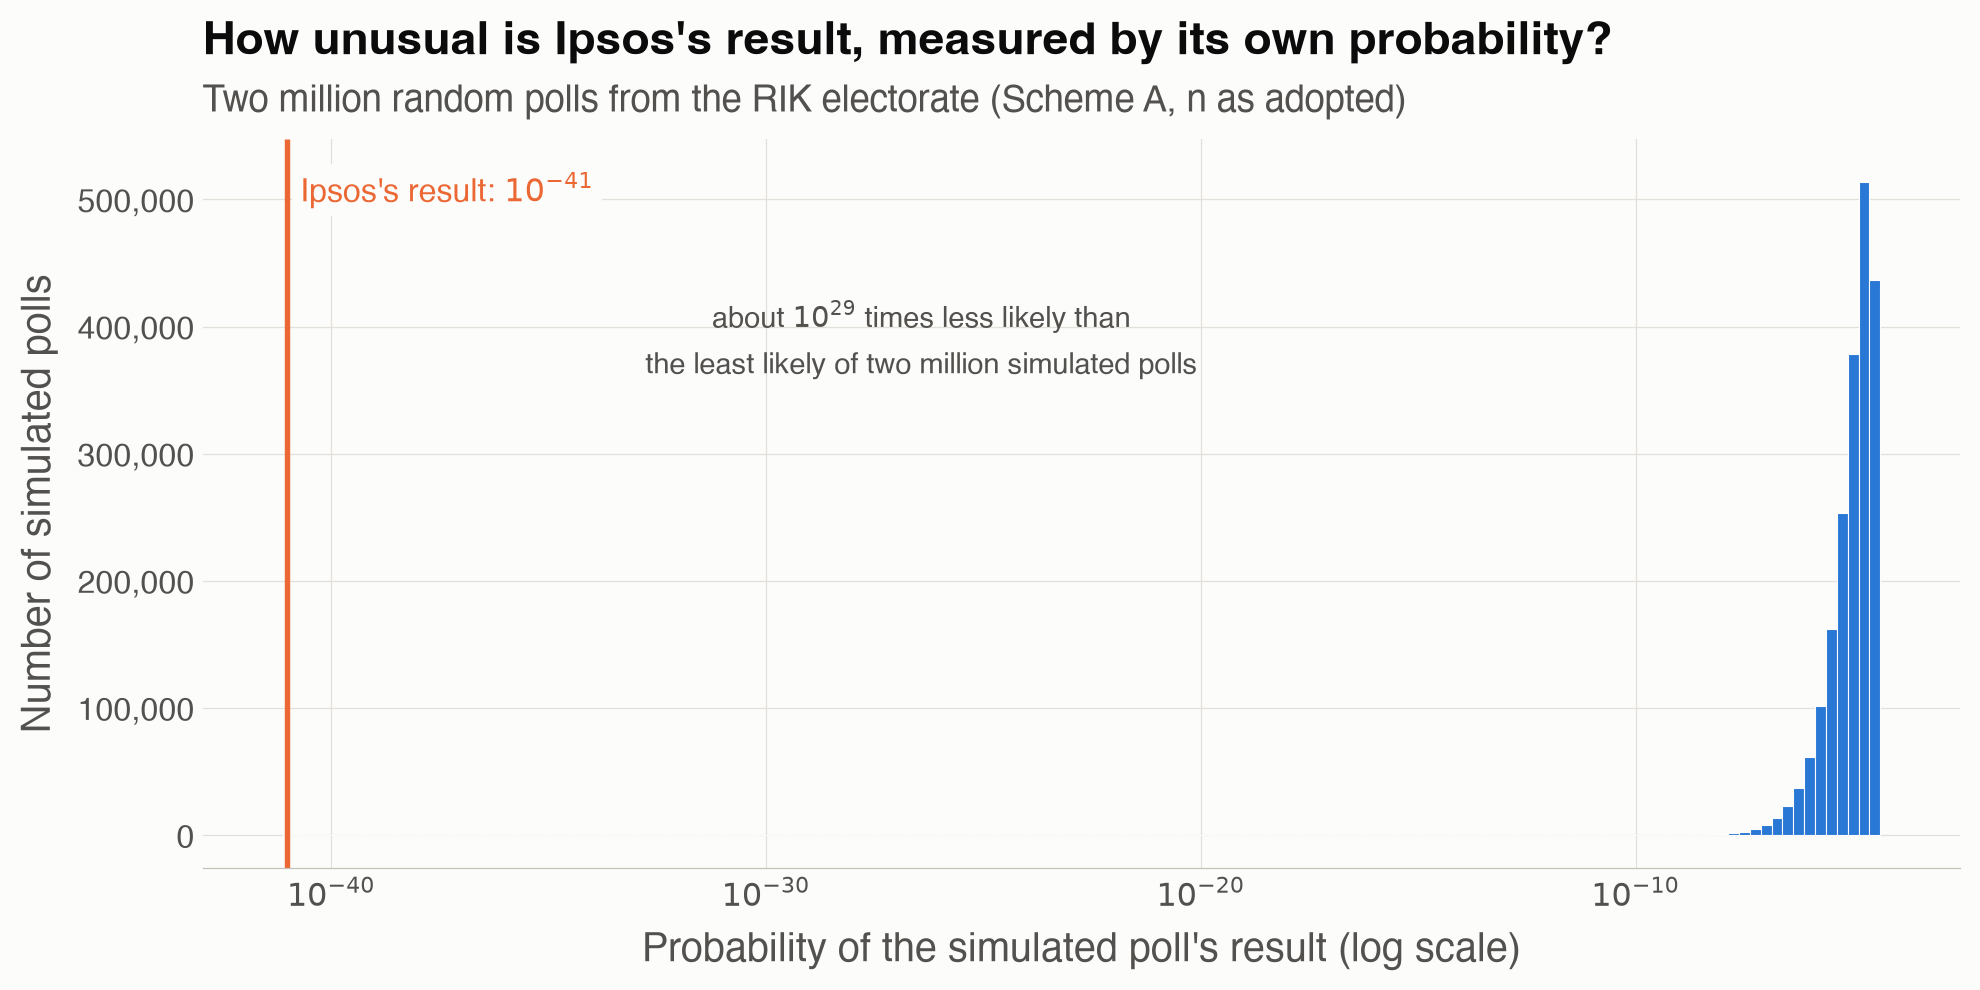

In [33]:
# ---- chunk: fig-m4 ----
hist_df = pd.DataFrame({"l10": log10_sim})
ymax = np.histogram(log10_sim, bins=np.arange(np.floor(log10_sim.min()), np.ceil(log10_sim.max()) + 0.25, 0.25))[0].max()
xmid = (log10_point_ips + log10_sim.min()) / 2
g = (ggplot(hist_df, aes(x="l10")) +
     geom_histogram(binwidth=0.25, fill="#2a78d6", color="#fcfcfb", size=0.2) +
     geom_vline(xintercept=log10_point_ips, color="#eb6834", size=1) +
     annotate("label", x=log10_point_ips + 0.3, y=ymax * 0.96, label=f"Ipsos's result: $10^{{{log10_point_ips:.0f}}}$",
              ha="left", va="top", color="#eb6834", fill="#fcfcfb", label_size=0, size=10.5) +
     annotate("text", x=xmid, y=ymax * 0.75, label=f"about $10^{{{log10_sim.min() - log10_point_ips:.0f}}}$ times less likely than",
              color="#52514e", size=9.5) +
     annotate("text", x=xmid, y=ymax * 0.68, label="the least likely of two million simulated polls", color="#52514e", size=9.5) +
     scale_x_continuous(labels=pow10) +
     scale_y_continuous(labels=comma) +
     labs(x="Probability of the simulated poll's result (log scale)", y="Number of simulated polls",
          title="How unusual is Ipsos's result, measured by its own probability?",
          subtitle="Two million random polls from the RIK electorate (Scheme A, n as adopted)") +
     theme_report(figure_size=(9, 4.5)))
fig(g, "Figure 5. Log-probability (base 10) of two million simulated random polls under H₀. Ipsos's result lies far to the left of every one of them.")

## 7.7 Method 5: the likelihood-ratio (G) test, which can reach the extreme tail

<div class="concept">
<h4>Concept: the G statistic and the chi-square distribution</h4>

The classical textbook route to the far tail is an approximation. The <b>G statistic</b> (likelihood-ratio statistic) summarises the discrepancy between observed and expected counts in one number, G = 2 Σ O<sub>i</sub> ln(O<sub>i</sub> / E<sub>i</sub>). Under H₀, and for samples this large, G approximately follows a known distribution, the <b>chi-square distribution</b> with (categories − 1) <b>degrees of freedom</b> (roughly: the number of independent ways the counts can deviate from expectation; with four categories that must sum to <i>n</i>, three), whose tail we can compute analytically to any depth. Its close cousin is Pearson's chi-square, Σ (O − E)² / E; we report both.

Two honest caveats. First, the chi-square distribution is an <b>asymptotic approximation</b>: excellent near the centre, rougher the deeper into the tail one goes, which is why the G and Pearson versions below disagree by a few powers of ten even though they measure the same thing. Second, when they disagree in the far tail, G is the one to trust: its tail behaviour is governed exactly by the information-theoretic distance between the two vectors, whereas Pearson's statistic is known to overstate extremeness far out. We therefore treat Method 5 as a cross-check on the exact computation of Method 4, not as the headline, and read all of these figures as orders of magnitude.

<i>Further reading:</i> McDonald, <i>Handbook of Biological Statistics</i>: <a href="https://www.biostathandbook.com/gtestgof.html">G-test of goodness-of-fit</a>, <a href="https://www.biostathandbook.com/chigof.html">chi-square test of goodness-of-fit</a> and <a href="https://www.biostathandbook.com/small.html">small numbers in chi-square and G-tests</a> (the "expected count below 5" rule used for Scheme B), all written for non-statisticians · Wikipedia on the <a href="https://en.wikipedia.org/wiki/G-test">G-test</a>, the <a href="https://en.wikipedia.org/wiki/Likelihood-ratio_test">likelihood-ratio test</a>, <a href="https://en.wikipedia.org/wiki/Pearson%27s_chi-squared_test">Pearson's chi-squared test</a> and the <a href="https://en.wikipedia.org/wiki/Chi-squared_distribution">chi-squared distribution</a>.
</div>

In [34]:
# ---- chunk: m5-gtest ----
def g_test(obs, p):
    obs = np.asarray(obs, dtype=float); p = np.asarray(p, dtype=float)
    n = obs.sum(); E = n * p
    G  = 2 * np.sum(np.where(obs > 0, obs * np.log(np.where(obs > 0, obs, 1) / E), 0))
    X2 = np.sum((obs - E) ** 2 / E)
    df = len(obs) - 1
    return {"G": G, "X2": X2, "df": df,
            "log10_p_G":  stats.chi2.logsf(G,  df) / np.log(10),
            "log10_p_X2": stats.chi2.logsf(X2, df) / np.log(10)}
gA = g_test(k_ips_A.values, p_rik_A.values)

# Scheme B: all 19 categories, merging those whose expected count is below 5 (the usual rule of thumb)
k_ips_B = pd.Series(pct_to_counts(pct_ips_B.values, n_primary, remainder_to=list(pct_ips_B.index).index("Invalid ballots")), index=pct_ips_B.index)
small = n_primary * p_rik_B < 5
k_ips_B2 = pd.concat([k_ips_B[~small], pd.Series({"Small lists (merged)": k_ips_B[small].sum()})])
p_rik_B2 = pd.concat([p_rik_B[~small], pd.Series({"Small lists (merged)": p_rik_B[small].sum()})])
gB = g_test(k_ips_B2.values, p_rik_B2.values)

kable_report(pd.DataFrame({
    "Scheme": ["A: four categories", f"B: all lists ({len(k_ips_B2)} categories after merging {int(small.sum())} tiny ones)"],
    "G statistic": [f"{gA['G']:.0f}", f"{gB['G']:.0f}"],
    "Degrees of freedom": [gA["df"], gB["df"]],
    "p-value (G)": [fmt_log10p(gA["log10_p_G"]), fmt_log10p(gB["log10_p_G"])],
    "p-value (Pearson χ², less reliable this far out)": [fmt_log10p(gA["log10_p_X2"]), fmt_log10p(gB["log10_p_X2"])]}),
    caption="Table 9. Likelihood-ratio and Pearson chi-square tests of Ipsos's result against the RIK electorate (asymptotic approximations; orders of magnitude).")

Scheme,G statistic,Degrees of freedom,p-value (G),"p-value (Pearson χ², less reliable this far out)"
A: four categories,168,3,3 × 10−36 (about 1 in a 3 followed by 35 zeros),3 × 10−38 (about 1 in a 3 followed by 37 zeros)
B: all lists (13 categories after merging 7 tiny ones),188,12,1 × 10−33 (about 1 in a 9 followed by 32 zeros),3 × 10−37 (about 1 in a 3 followed by 36 zeros)


In [35]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> In the four-category scheme the chi-square approximation puts the probability of a discrepancy at least as large as Ipsos's at <b>{fmt_log10p(gA["log10_p_G"])}</b>, within a factor of {10 ** abs(gA["log10_p_G"] - log10_p_exact):.0f} of the exact value from Method 4 ({fmt_log10p(log10_p_exact)}): remarkably close for an approximation this deep in the tail, and a reminder that the G statistic's tail is governed by the right quantity. Treating lists separately (Scheme B, {len(k_ips_B2)} categories after merging the {int(small.sum())} smallest) gives {fmt_log10p(gB["log10_p_G"])}: the discrepancy is slightly larger in total (G = {gB["G"]:.0f} against {gA["G"]:.0f}), but it is spread over more than three times as many categories, and the chi-square distribution charges for each extra category. All of these agree to within a few orders of magnitude, which, at this depth, is agreement.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> In the four-category scheme the chi-square approximation puts the probability of a discrepancy at least as large as Ipsos's at <b>3 × 10<sup>−36</sup> (about 1 in a 3 followed by 35 zeros)</b>, within a factor of 2 of the exact value from Method 4 (2 × 10<sup>−36</sup> (about 1 in a 5 followed by 35 zeros)): remarkably close for an approximation this deep in the tail, and a reminder that the G statistic's tail is governed by the right quantity. Treating lists separately (Scheme B, 13 categories after merging the 7 smallest) gives 1 × 10<sup>−33</sup> (about 1 in a 9 followed by 32 zeros): the discrepancy is slightly larger in total (G = 188 against 168), but it is spread over more than three times as many categories, and the chi-square distribution charges for each extra category. All of these agree to within a few orders of magnitude, which, at this depth, is agreement.
</div>


## 7.8 All methods side by side

In [36]:
# ---- chunk: methods-summary ----
summary_tbl = pd.DataFrame({
    "Method": ["Method 1 – Point probability of Ipsos's exact vector (for reference; not a tail)",
               "Method 2a – Binomial tail: Studentska lista this low or lower (exact)",
               "Method 2b – Binomial tail: Ujedinjena Srbija this high or higher (exact)",
               "Method 3 – Joint tail: both at once (exact; plain Monte Carlo)",
               "Method 4a – Exact multinomial test, exhaustive enumeration (exact; the headline)",
               "Method 4b – Exact multinomial test, plain Monte Carlo",
               "Method 4c – Exact multinomial test, importance sampling (biased low here; see text)",
               "Method 5a – Likelihood-ratio G test, Scheme A (chi-square approximation)",
               "Method 5b – Likelihood-ratio G test, Scheme B, all lists (chi-square approximation)"],
    "Probability under random sampling": [
        fmt_log10p(log10_point_ips), fmt_log10p(m2.log10_p[0]), fmt_log10p(m2.log10_p[1]),
        f"exact: {fmt_log10p(np.log10(joint_exact))}; Monte Carlo: 0 of {fmt_n(n_sim)}",
        f"<b>{fmt_log10p(log10_p_exact)}</b>",
        f"below {fmt_log10p(np.log10(1 / n_sim))} (0 of {fmt_n(n_sim)})" if n_as_extreme == 0 else f"{n_as_extreme / n_sim:.2e}",
        f"{fmt_log10p(log10_p_is)} ({n_rep} runs: exponents {is_spread[0]:.1f} to {is_spread[1]:.1f})",
        fmt_log10p(gA["log10_p_G"]), fmt_log10p(gB["log10_p_G"])]})
kable_report(summary_tbl, caption=f"Table 10. Summary of all methods, Scheme A unless stated, n = {fmt_n(n_primary)}.", align=["l", "l"])
# the range of tail probabilities across the methods that can reach the tail (the importance-sampling
# estimate is excluded: Method 4 shows it to be biased low)
tail_range = (min(m2.log10_p[0], np.log10(joint_exact), log10_p_exact, gA["log10_p_G"], gB["log10_p_G"]),
              max(m2.log10_p[0], np.log10(joint_exact), log10_p_exact, gA["log10_p_G"], gB["log10_p_G"]))

Method,Probability under random sampling
Method 1 – Point probability of Ipsos's exact vector (for reference; not a tail),1 × 10−41 (about 1 in a 1 followed by 41 zeros)
Method 2a – Binomial tail: Studentska lista this low or lower (exact),2 × 10−33 (about 1 in a 4 followed by 32 zeros)
Method 2b – Binomial tail: Ujedinjena Srbija this high or higher (exact),2 × 10−15 (about 1 in a 4 followed by 14 zeros)
Method 3 – Joint tail: both at once (exact; plain Monte Carlo),"exact: 2 × 10−33 (about 1 in a 4 followed by 32 zeros); Monte Carlo: 0 of 2,000,000"
"Method 4a – Exact multinomial test, exhaustive enumeration (exact; the headline)",2 × 10−36 (about 1 in a 5 followed by 35 zeros)
"Method 4b – Exact multinomial test, plain Monte Carlo","below 5 × 10−7 (about 1 in a 2 followed by 6 zeros) (0 of 2,000,000)"
"Method 4c – Exact multinomial test, importance sampling (biased low here; see text)",2 × 10−37 (about 1 in a 7 followed by 36 zeros) (10 runs: exponents -37.0 to -36.6)
"Method 5a – Likelihood-ratio G test, Scheme A (chi-square approximation)",3 × 10−36 (about 1 in a 3 followed by 35 zeros)
"Method 5b – Likelihood-ratio G test, Scheme B, all lists (chi-square approximation)",1 × 10−33 (about 1 in a 9 followed by 32 zeros)


In [37]:
md(f"""
<div class="callout callout-result">
<b>Reading the summary.</b> Every method that can reach the far tail puts the probability between <b>{fmt_pow(tail_range[1])} and {fmt_pow(tail_range[0])}</b>, depending on how "at least as far from the truth" is defined (one list, both lists, or the whole vector) and on which approximation is used. The two that cannot reach it are consistent with that range: the <i>Ujedinjena Srbija</i> tail on its own ({fmt_pow(m2.log10_p[1])}) is a deliberately weaker, one-list statement, and plain simulation stops at the floor of what two million draws can resolve, which is itself a finding: among two million ideal random polls, not one looks like Ipsos's. Our headline figure is the exact multinomial test by exhaustive enumeration, <b>{fmt_log10p(log10_p_exact)}</b>, because it is the most general definition computed without any approximation; the chi-square figure, {fmt_pow(gA["log10_p_G"])}, is the textbook approximation to the same quantity and lands close to it. The importance-sampling estimate is left out of the range because Method 4 shows it to be biased low. In substance: the hypothesis that Ipsos's published numbers arose from a random sample of the people who voted on 25 October, with chance as the only source of error, is not tenable. Sampling error alone cannot account for the gap.
</div>
""")


<div class="callout callout-result">
<b>Reading the summary.</b> Every method that can reach the far tail puts the probability between <b>10<sup>−33</sup> and 10<sup>−36</sup></b>, depending on how "at least as far from the truth" is defined (one list, both lists, or the whole vector) and on which approximation is used. The two that cannot reach it are consistent with that range: the <i>Ujedinjena Srbija</i> tail on its own (10<sup>−15</sup>) is a deliberately weaker, one-list statement, and plain simulation stops at the floor of what two million draws can resolve, which is itself a finding: among two million ideal random polls, not one looks like Ipsos's. Our headline figure is the exact multinomial test by exhaustive enumeration, <b>2 × 10<sup>−36</sup> (about 1 in a 5 followed by 35 zeros)</b>, because it is the most general definition computed without any approximation; the chi-square figure, 10<sup>−35</sup>, is the textbook approximation to the same quantity and lands close to it. The importance-sampling estimate is left out of the range because Method 4 shows it to be biased low. In substance: the hypothesis that Ipsos's published numbers arose from a random sample of the people who voted on 25 October, with chance as the only source of error, is not tenable. Sampling error alone cannot account for the gap.
</div>


## 7.9 The same conclusion from Ipsos's own stated precision

There is an even simpler way to see this, which needs no model of ours at all, only Ipsos's own published confidence intervals.

In [38]:
# ---- chunk: own-precision ----
own = pd.DataFrame({"Category": ["Studentska lista", "Ujedinjena Srbija"],
                    "ipsos": [40.0, 47.4], "lo": [37.9, 45.3], "hi": [42.1, 49.5],
                    "actual": 100 * p_rik_A.values[:2]})
own["se_own"] = (own["hi"] - own["lo"]) / 2 / 1.96
own["outside_by"] = np.where(own["actual"] > own["hi"], own["actual"] - own["hi"], own["lo"] - own["actual"])
own["z_own"] = (own["actual"] - own["ipsos"]) / own["se_own"]
own["log10_p_own"] = stats.norm.logcdf(-np.abs(own["z_own"])) / np.log(10)
kable_report(pd.DataFrame({"Category": own["Category"], "Ipsos 95% interval": [f"{lo:.1f} – {hi:.1f}" for lo, hi in zip(own["lo"], own["hi"])],
                           "Actual result": own["actual"].map(fmt_pct), "Outside the interval by (pts)": own["outside_by"].map(lambda x: f"{x:.1f}"),
                           "Ipsos's own SE (pts)": own["se_own"].map(lambda x: f"{x:.2f}"), "Distance in SEs": own["z_own"].abs().map(lambda x: f"{x:.1f}"),
                           "One-sided probability": own["log10_p_own"].map(fmt_log10p)}),
             caption="Table 11. The actual result measured against Ipsos's own published margins of error.")

Category,Ipsos 95% interval,Actual result,Outside the interval by (pts),Ipsos's own SE (pts),Distance in SEs,One-sided probability
Studentska lista,37.9 – 42.1,53.03%,10.9,1.07,12.2,2 × 10−34 (about 1 in a 4 followed by 33 zeros)
Ujedinjena Srbija,45.3 – 49.5,38.97%,6.3,1.07,7.9,2 × 10−15 (about 1 in a 6 followed by 14 zeros)


In [39]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> Ipsos's interval for <i>Studentska lista</i>, 37.9–42.1%, says in effect: "an interval built this way would cover the true value in 95 out of 100 polls like ours". The truth was {fmt_pct(own.actual[0])}: <b>{own.outside_by[0]:.1f} points above the top of the interval</b>, which is {abs(own.z_own[0]):.0f} of Ipsos's own standard errors away from its estimate. For <i>Ujedinjena Srbija</i> the truth was {own.outside_by[1]:.1f} points below the bottom of the interval, {abs(own.z_own[1]):.0f} standard errors away. By the precision Ipsos itself claimed, the chance of being this wrong on <i>Studentska lista</i> alone is about {fmt_log10p(own.log10_p_own[0])}. A 95% interval is supposed to miss one time in twenty, and typically by a fraction of a point, not by eleven.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> Ipsos's interval for <i>Studentska lista</i>, 37.9–42.1%, says in effect: "an interval built this way would cover the true value in 95 out of 100 polls like ours". The truth was 53.03%: <b>10.9 points above the top of the interval</b>, which is 12 of Ipsos's own standard errors away from its estimate. For <i>Ujedinjena Srbija</i> the truth was 6.3 points below the bottom of the interval, 8 standard errors away. By the precision Ipsos itself claimed, the chance of being this wrong on <i>Studentska lista</i> alone is about 2 × 10<sup>−34</sup> (about 1 in a 4 followed by 33 zeros). A 95% interval is supposed to miss one time in twenty, and typically by a fraction of a point, not by eleven.
</div>


## 7.10 The sampling cloud

In [40]:
md(f"""
One picture summarises the whole section (Figure 6). Each grey dot is a random poll of {fmt_n(n_primary)} decided voters from the real electorate; together they show everything that chance can produce. Ipsos's result is marked, together with the box of its own published 95% intervals.
""")


One picture summarises the whole section (Figure 6). Each grey dot is a random poll of 2,110 decided voters from the real electorate; together they show everything that chance can produce. Ipsos's result is marked, together with the box of its own published 95% intervals.


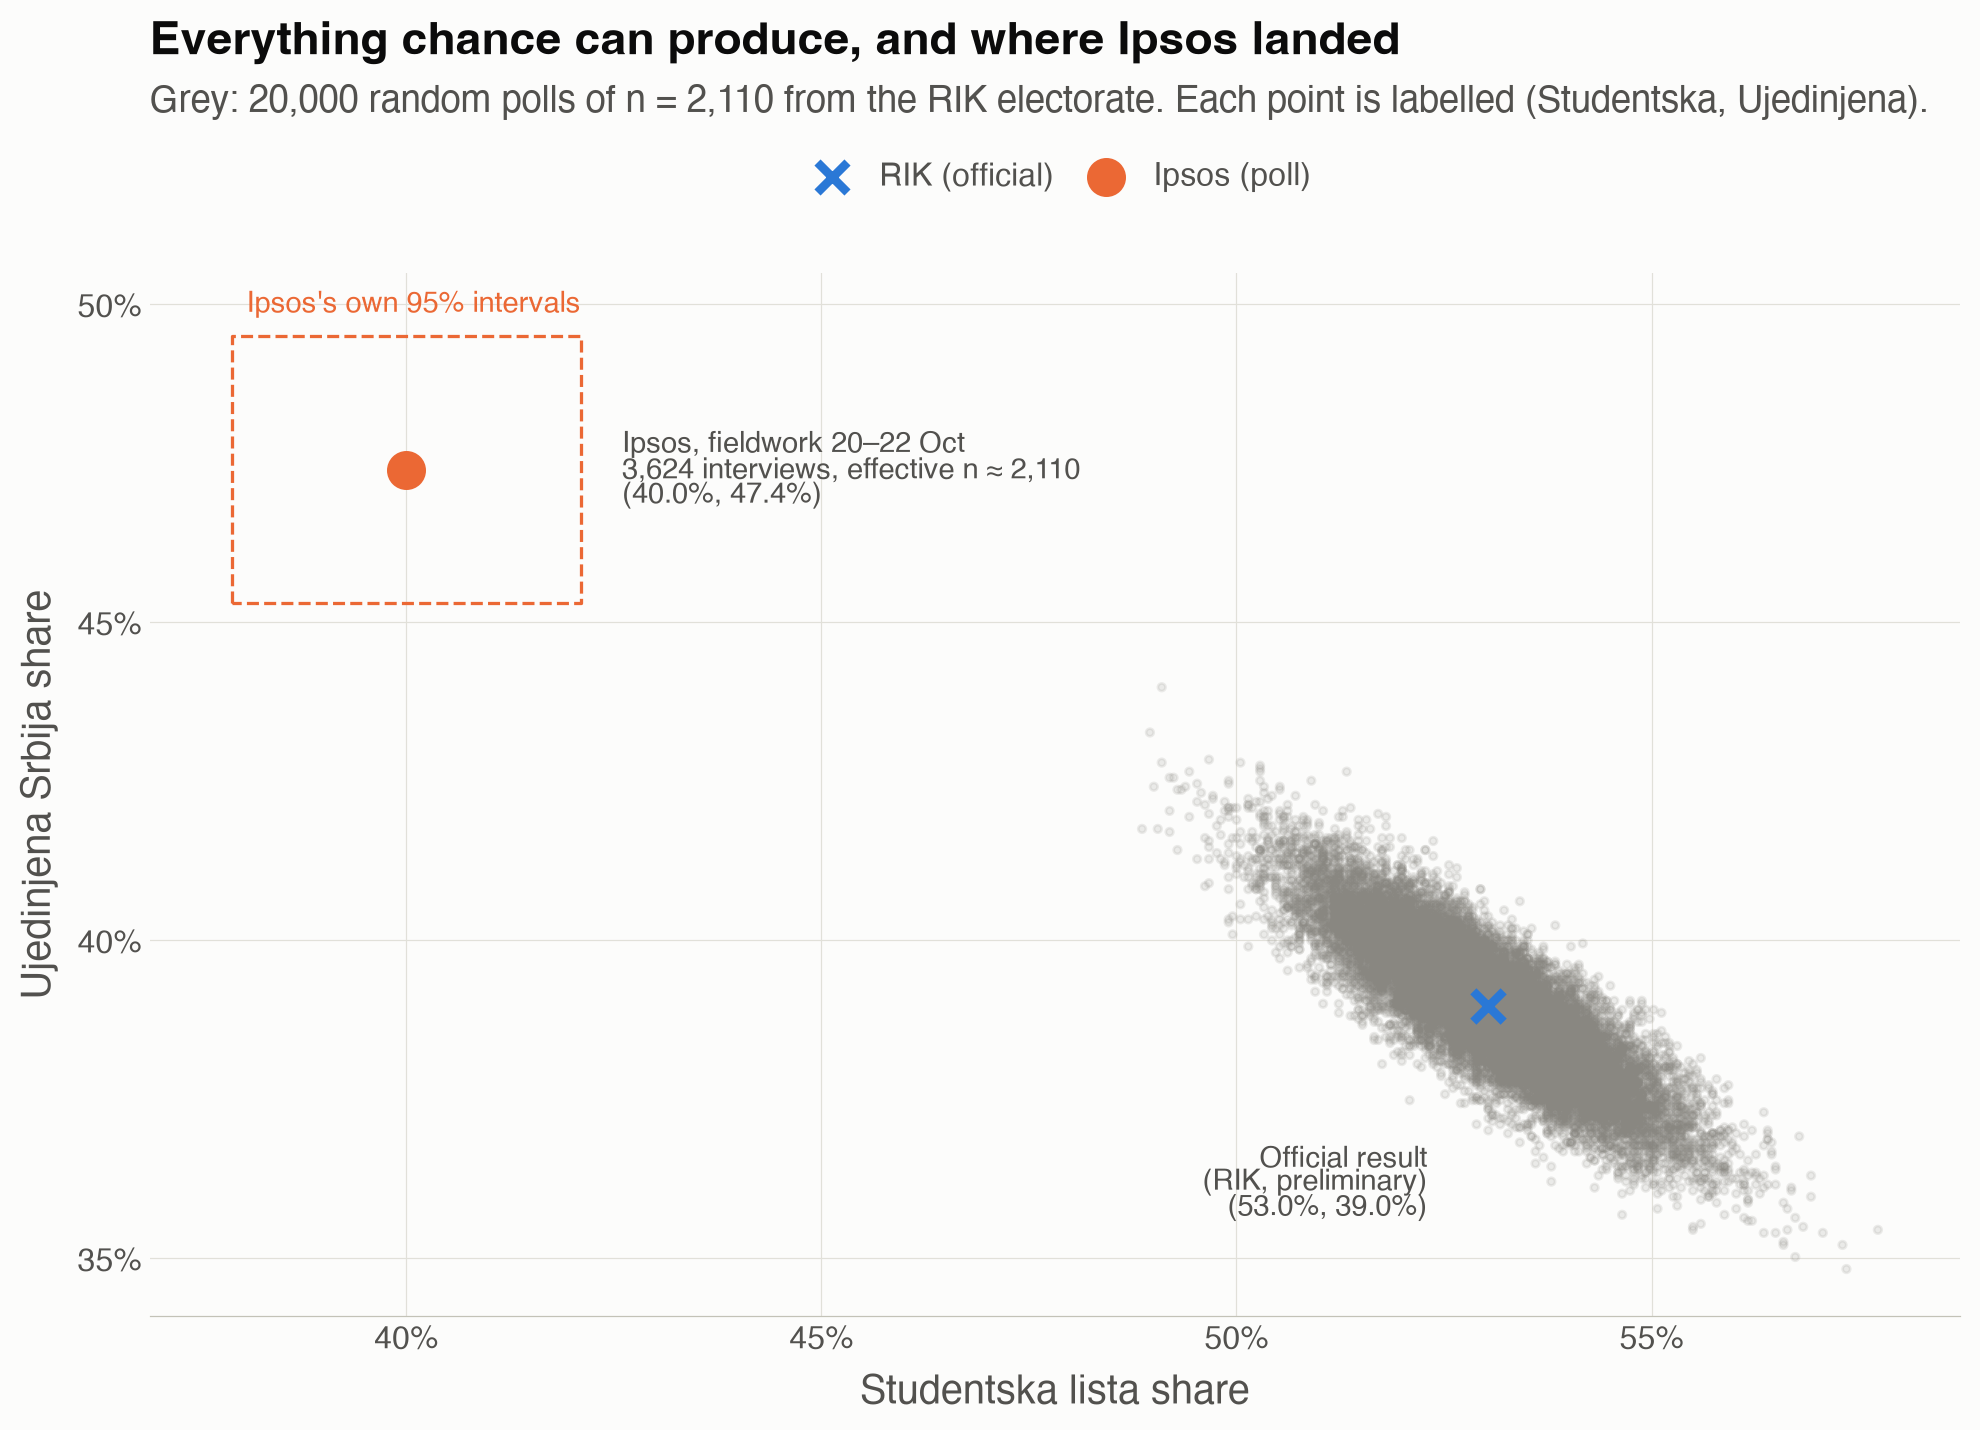

In [41]:
# ---- chunk: fig-cloud ----
cloud = pd.DataFrame({"sl": 100 * sim_A[0, :20000] / n_primary, "us": 100 * sim_A[1, :20000] / n_primary})
points = pd.DataFrame({
    "who": ["RIK (official)", "Ipsos (poll)"],
    "sl":  [100 * p_rik_A.iloc[0], 40.0],
    "us":  [100 * p_rik_A.iloc[1], 47.4],
    "note": ["Official result\n(RIK, preliminary)",
             f"Ipsos, fieldwork 20–22 Oct\n{fmt_n(ipsos_n)} interviews, effective n ≈ {fmt_n(n_primary)}"],
    # label positions: RIK below-left of the cloud, Ipsos to the right of its box
    "hjust": ["right", "left"], "lx": [52.3, 42.6], "ly": [36.2, 47.4]})
points["lbl"] = [f"{n}\n({s:.1f}%, {u:.1f}%)" for n, s, u in zip(points["note"], points["sl"], points["us"])]
points["who"] = pd.Categorical(points["who"], categories=["RIK (official)", "Ipsos (poll)"])

g = (ggplot() +
     geom_point(cloud, aes(x="sl", y="us"), color="#898781", alpha=0.15, size=0.9) +
     annotate("rect", xmin=37.9, xmax=42.1, ymin=45.3, ymax=49.5, fill="none", color="#eb6834", linetype="dashed", size=0.6) +
     annotate("text", x=42.1, y=49.75, label="Ipsos's own 95% intervals", ha="right", va="bottom", size=9.5, color="#eb6834") +
     geom_point(points, aes(x="sl", y="us", color="who", shape="who"), size=4, stroke=1.6) +
     geom_text(points, aes(x="lx", y="ly", label="lbl", ha="hjust"), size=9.5, color="#52514e", lineheight=0.95) +
     scale_color_manual(values=col) +
     scale_shape_manual(values={"RIK (official)": "x", "Ipsos (poll)": "o"}) +
     scale_x_continuous(labels=pct_lab) + scale_y_continuous(labels=pct_lab) +
     labs(x="Studentska lista share", y="Ujedinjena Srbija share",
          title="Everything chance can produce, and where Ipsos landed",
          subtitle=f"Grey: 20,000 random polls of n = {fmt_n(n_primary)} from the RIK electorate. Each point is labelled (Studentska, Ujedinjena).") +
     theme_report(figure_size=(9, 6.5)))
fig(g, "Figure 6. Where ideal random polls land (grey cloud, 20,000 simulations from the RIK electorate), Ipsos's published result (orange), Ipsos's own 95% box (orange dashed rectangle), and the official result (blue cross).")

<div class="callout callout-result">
<b>What the cloud shows.</b> The grey cloud, every result chance can plausibly produce, is a compact blob around the official result, about two points across. Ipsos's point is in a different part of the plane altogether, and its own 95% box does not come close to touching the cloud.
</div>

# 8 Sensitivity: does the conclusion depend on our choices?

## 8.1 Why check

Two choices in the analysis were ours rather than given: the effective sample size (Section 6) and the exact definition of the population (RIK's totals include Kosovo i Metohija and the diaspora, which Ipsos did not sample). A robust conclusion should survive any reasonable alternative for both. Here we vary them and watch the answer.

## 8.2 Varying the sample size

In [42]:
md(f"""
We rerun the G test and the binomial tails for a deliberately low *n* = 1,500 (more generous to Ipsos than its own intervals justify), our adopted *n*, a "raw decided" *n* = {fmt_n(round(0.8 * ipsos_n, -2))} (what the decided base would be if 80% of respondents named a list and there were no design effect at all; the 80% is an assumption, since Ipsos does not publish the figure), and the full 3,624 interviews.
""")


We rerun the G test and the binomial tails for a deliberately low *n* = 1,500 (more generous to Ipsos than its own intervals justify), our adopted *n*, a "raw decided" *n* = 2,900 (what the decided base would be if 80% of respondents named a list and there were no design effect at all; the 80% is an assumption, since Ipsos does not publish the figure), and the full 3,624 interviews.


In [43]:
# ---- chunk: sens-n ----
n_grid = [1500, n_primary, int(round(0.8 * ipsos_n, -2)), ipsos_n]
rows = []
for n in n_grid:
    k = pct_to_counts(pct_ips_A.values, n, 3)
    g_ = g_test(k, p_rik_A.values)
    rows.append({"n": n, "G test (Scheme A)": g_["log10_p_G"],
                 "Studentska this low":  binom_tail(k[0], n, p_rik_A.iloc[0], "low"),
                 "Ujedinjena this high": binom_tail(k[1], n, p_rik_A.iloc[1], "high")})
sens_n = pd.DataFrame(rows)
kable_report(pd.DataFrame({"Assumed n": sens_n["n"].map(fmt_n),
                           **{c: sens_n[c].map(fmt_log10p) for c in sens_n.columns[1:]}}),
             caption="Table 12. Probability of Ipsos's result for different assumed sample sizes.")

Assumed n,G test (Scheme A),Studentska this low,Ujedinjena this high
"1,500",7 × 10−26 (about 1 in a 1 followed by 25 zeros),3 × 10−24 (about 1 in a 3 followed by 23 zeros),2 × 10−11 (about 1 in a 5 followed by 10 zeros)
"2,110",3 × 10−36 (about 1 in a 3 followed by 35 zeros),2 × 10−33 (about 1 in a 4 followed by 32 zeros),2 × 10−15 (about 1 in a 4 followed by 14 zeros)
"2,900",9 × 10−50 (about 1 in a 1 followed by 49 zeros),4 × 10−45 (about 1 in a 3 followed by 44 zeros),2 × 10−20 (about 1 in a 6 followed by 19 zeros)
"3,624",3 × 10−62 (about 1 in a 4 followed by 61 zeros),8 × 10−56 (about 1 in a 1 followed by 55 zeros),4 × 10−25 (about 1 in a 3 followed by 24 zeros)


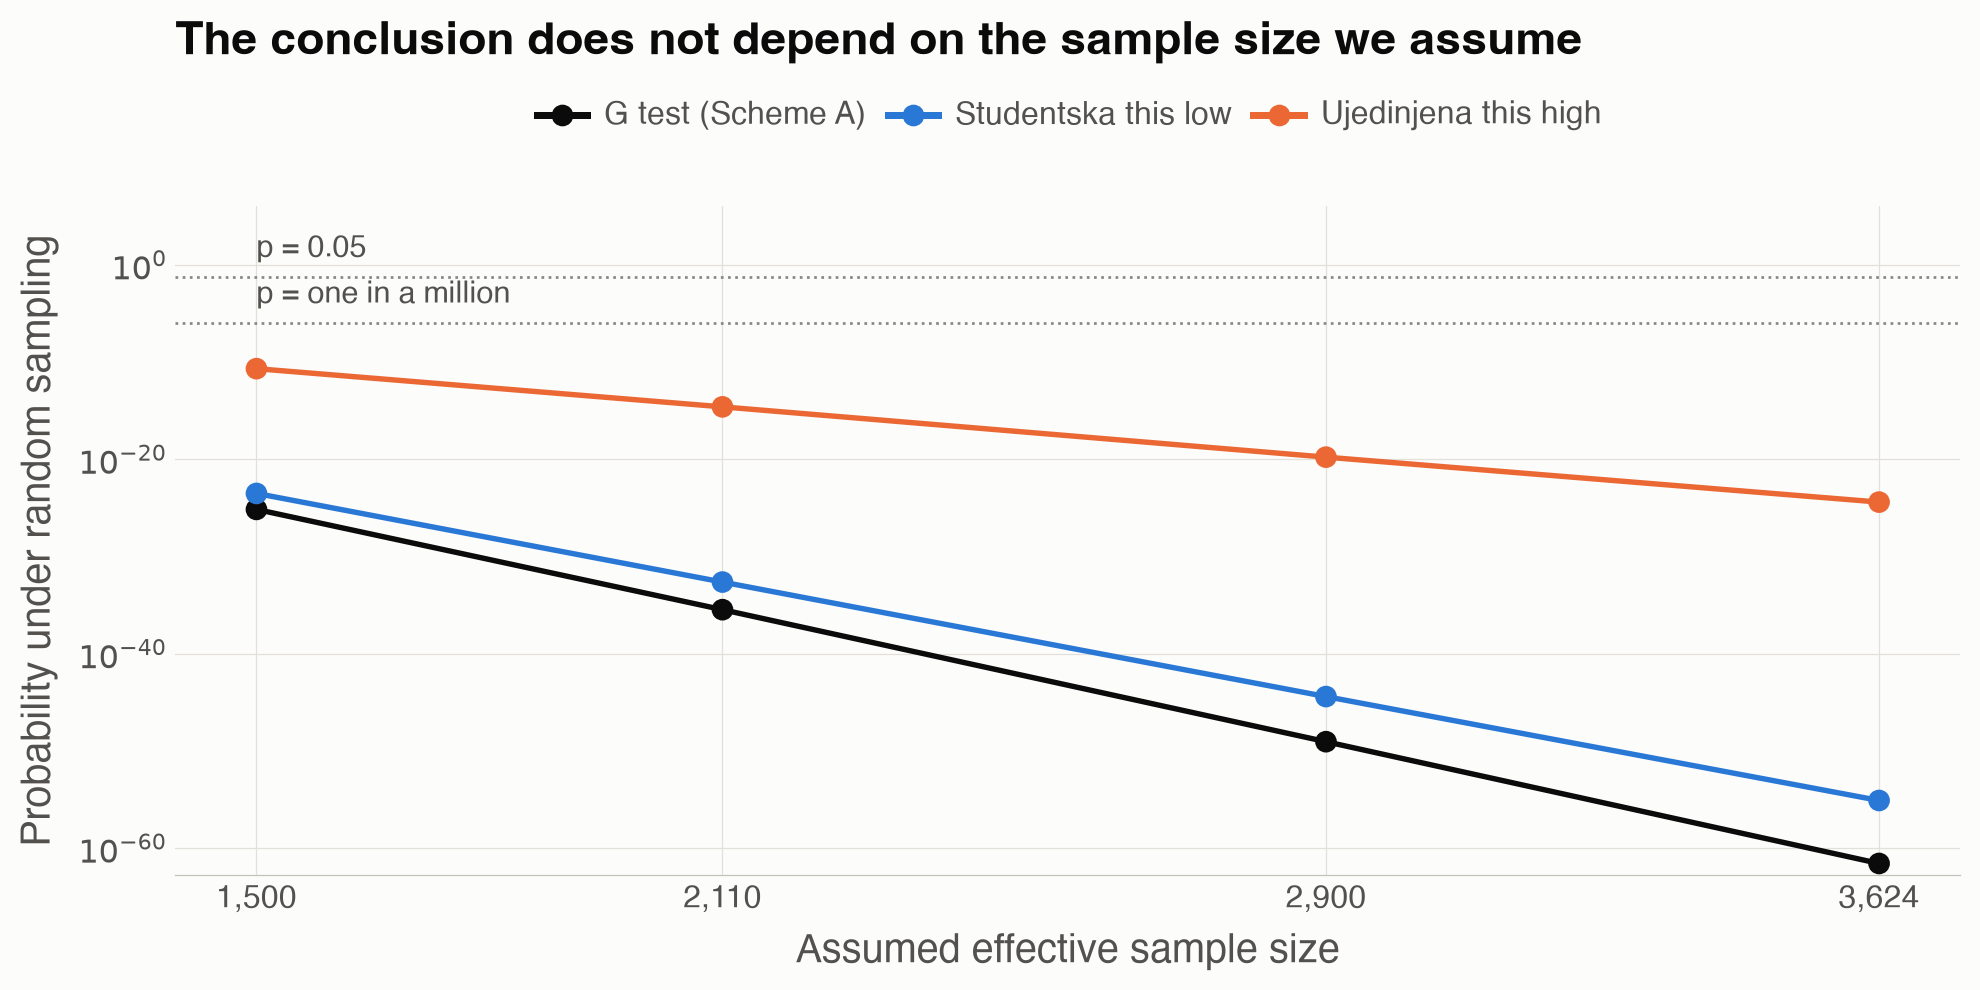

In [44]:
# ---- chunk: fig-sens-n ----
sl = sens_n.melt(id_vars="n", var_name="method", value_name="log10_p")
sl["method"] = pd.Categorical(sl["method"], categories=["G test (Scheme A)", "Studentska this low", "Ujedinjena this high"])
g = (ggplot(sl, aes(x="n", y="log10_p", color="method")) +
     geom_hline(yintercept=np.log10(0.05), linetype="dotted", color="#898781") +
     geom_hline(yintercept=-6, linetype="dotted", color="#898781") +
     annotate("text", x=1500, y=np.log10(0.05) + 1.2, label="p = 0.05", ha="left", va="bottom", size=10, color="#52514e") +
     annotate("text", x=1500, y=-6 + 1.2, label="p = one in a million", ha="left", va="bottom", size=10, color="#52514e") +
     geom_line(size=1) + geom_point(size=3) +
     scale_color_manual(values={"G test (Scheme A)": "#0b0b0b", "Studentska this low": "#2a78d6", "Ujedinjena this high": "#eb6834"}) +
     scale_x_continuous(breaks=n_grid, labels=comma) +
     scale_y_continuous(labels=pow10, expand=(0.02, 0, 0.1, 0)) +
     labs(x="Assumed effective sample size", y="Probability under random sampling",
          title="The conclusion does not depend on the sample size we assume") +
     theme_report(figure_size=(9, 4.5)))
fig(g, "Figure 7. Log-probability of Ipsos's result as a function of the assumed effective sample size. Every line is far below the conventional 5% and 1-in-a-million thresholds at every n.")

## 8.3 Varying the population: excluding Kosovo i Metohija and the diaspora

In [45]:
md(f"""
Ipsos surveyed only citizens present in Serbia without Kosovo i Metohija. Voters abroad broke overwhelmingly for *Studentska lista* ({fmt_pct(100 * abroad_votes[2] / abroad_votes.sum(), 1)} of their valid votes), voters in Kosovo i Metohija overwhelmingly for *Ujedinjena Srbija* ({fmt_pct(100 * kim_votes[0] / kim_votes.sum(), 1)}). The fair comparison removes both from the population.
""")


Ipsos surveyed only citizens present in Serbia without Kosovo i Metohija. Voters abroad broke overwhelmingly for *Studentska lista* (72.8% of their valid votes), voters in Kosovo i Metohija overwhelmingly for *Ujedinjena Srbija* (73.8%). The fair comparison removes both from the population.


In [46]:
# ---- chunk: sens-pop ----
scheme_a_adj = scheme_a.copy()
scheme_a_adj["votes_adj"] = scheme_a_adj["votes"] - scheme_a_adj["kim"] - scheme_a_adj["abroad"]
scheme_a_adj["rik_p_adj"] = scheme_a_adj["votes_adj"] / scheme_a_adj["votes_adj"].sum()
scheme_a_adj["rik_pct_adj"] = 100 * scheme_a_adj["rik_p_adj"]
p_rik_A_adj = pd.Series(scheme_a_adj["rik_p_adj"].values, index=grp_levels)
g_adj = g_test(k_ips_A.values, p_rik_A_adj.values)
bin_adj = [binom_tail(k_ips_A.iloc[0], n_primary, p_rik_A_adj.iloc[0], "low"),
           binom_tail(k_ips_A.iloc[1], n_primary, p_rik_A_adj.iloc[1], "high")]

kable_report(pd.DataFrame({"Category": grp_levels, "RIK % (all voters)": scheme_a_adj["rik_pct"].map(fmt_pct),
                           "RIK % (Serbia proper, without Kosovo i Metohija and abroad)": scheme_a_adj["rik_pct_adj"].map(fmt_pct),
                           "Ipsos %": scheme_a_adj["ipsos_pct"].map(lambda x: fmt_pct(x, 1))}),
             caption=f"Table 13. The population redefined to match Ipsos's sampling frame (removes {fmt_n((scheme_a['kim'] + scheme_a['abroad']).sum())} ballots).")

Category,RIK % (all voters),"RIK % (Serbia proper, without Kosovo i Metohija and abroad)",Ipsos %
Studentska lista,53.03%,52.94%,40.0%
Ujedinjena Srbija,38.97%,38.96%,47.4%
Manjinske liste,2.16%,2.21%,2.3%
Other,5.84%,5.89%,10.3%


In [47]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> Matching Ipsos's sampling frame moves the <i>Studentska lista</i> share from {fmt_pct(scheme_a.rik_pct[0])} to {fmt_pct(scheme_a_adj.rik_pct_adj[0])} and <i>Ujedinjena Srbija</i> from {fmt_pct(scheme_a.rik_pct[1])} to {fmt_pct(scheme_a_adj.rik_pct_adj[1])}: changes in the second decimal, because the two excluded populations are small and pull in opposite directions. The G-test probability rises slightly, from {fmt_log10p(gA["log10_p_G"])} to {fmt_log10p(g_adj["log10_p_G"])}. The population definition is not the explanation.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> Matching Ipsos's sampling frame moves the <i>Studentska lista</i> share from 53.03% to 52.94% and <i>Ujedinjena Srbija</i> from 38.97% to 38.96%: changes in the second decimal, because the two excluded populations are small and pull in opposite directions. The G-test probability rises slightly, from 3 × 10<sup>−36</sup> (about 1 in a 3 followed by 35 zeros) to 1 × 10<sup>−35</sup> (about 1 in a 9 followed by 34 zeros). The population definition is not the explanation.
</div>


## 8.4 Varying the base: valid votes only

As explained in Section 4 (Issue 1), Ipsos's 2.5% invalid share is an assumption rather than a measurement, so it should not really be allowed to count as "sampling evidence". Here we remove invalid ballots from both sides: Ipsos's list shares are rescaled to the 97.5% that its respondents actually produced, and RIK's shares are taken over valid votes. This is the fairest version of the test for Ipsos.

In [48]:
# ---- chunk: sens-valid ----
# Scheme A on the valid-vote base: drop the invalid row from both sources
ips_valid = (ipsos[ipsos["short"] != "Invalid ballots"].groupby("group")["ipsos_pct"].sum() / 0.975).reindex(grp_levels)
rik_valid = rik[rik["short"] != "Invalid ballots"].groupby("group")["votes"].sum().reindex(grp_levels)
p_rik_A_valid   = rik_valid / rik_valid.sum()
pct_ips_A_valid = ips_valid
k_ips_A_valid   = pct_to_counts(pct_ips_A_valid.values, n_primary, 3)
g_valid   = g_test(k_ips_A_valid, p_rik_A_valid.values)
bin_valid = binom_tail(k_ips_A_valid[0], n_primary, p_rik_A_valid.iloc[0], "low")

# Scheme B on the valid-vote base
sb_valid = scheme_b[scheme_b["short"] != "Invalid ballots"].copy()
sb_valid["p"] = sb_valid["votes"] / sb_valid["votes"].sum()
sb_valid["pct"] = sb_valid["ipsos_pct"] / 0.975
k_B_valid = pd.Series(pct_to_counts(sb_valid["pct"].values, n_primary, int(np.argmax(sb_valid["pct"].values))), index=sb_valid["short"])
p_B_valid = pd.Series(sb_valid["p"].values, index=sb_valid["short"])
small_v = n_primary * p_B_valid < 5
k_B_valid2 = pd.concat([k_B_valid[~small_v], pd.Series({"Small lists (merged)": k_B_valid[small_v].sum()})])
p_B_valid2 = pd.concat([p_B_valid[~small_v], pd.Series({"Small lists (merged)": p_B_valid[small_v].sum()})])
gB_valid = g_test(k_B_valid2.values, p_B_valid2.values)

kable_report(pd.DataFrame({
    "Test": ["Studentska lista this low or lower (binomial)", "G test, Scheme A", "G test, Scheme B"],
    "All ballots (main analysis)": [fmt_log10p(x) for x in (m2.log10_p[0], gA["log10_p_G"], gB["log10_p_G"])],
    "Valid votes only": [fmt_log10p(x) for x in (bin_valid, g_valid["log10_p_G"], gB_valid["log10_p_G"])]}),
    caption="Table 14. The key tests with invalid ballots removed from both sources.")
# the overall range of tail probabilities across methods AND bases, used in the conclusions
tail_range_all = (min(tail_range[0], g_valid["log10_p_G"], gB_valid["log10_p_G"]), max(tail_range[1], g_valid["log10_p_G"], gB_valid["log10_p_G"]))

Test,All ballots (main analysis),Valid votes only
Studentska lista this low or lower (binomial),2 × 10−33 (about 1 in a 4 followed by 32 zeros),1 × 10−31 (about 1 in a 8 followed by 30 zeros)
"G test, Scheme A",3 × 10−36 (about 1 in a 3 followed by 35 zeros),8 × 10−33 (about 1 in a 1 followed by 32 zeros)
"G test, Scheme B",1 × 10−33 (about 1 in a 9 followed by 32 zeros),1 × 10−30 (about 1 in a 7 followed by 29 zeros)


In [49]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> On the valid-vote base <i>Studentska lista</i>'s true share is {fmt_pct(100 * p_rik_A_valid.iloc[0])} and Ipsos's rescaled estimate {pct_ips_A_valid.iloc[0]:.1f}%; the gap narrows by a fraction of a point and the "Other" category loses the 1.2-point invalid-ballot overestimate. The probabilities move accordingly: the Scheme A test from {fmt_pow(gA["log10_p_G"])} to {fmt_pow(g_valid["log10_p_G"])}, Scheme B from {fmt_pow(gB["log10_p_G"])} to {fmt_pow(gB_valid["log10_p_G"])}. Three or four powers of ten is a real difference, and it is the reason this document reports its headline as an order of magnitude rather than a precise figure. It does not come close to changing the conclusion.

Across every combination of sample size, population definition and base, the probability of Ipsos's result under random sampling never rises above about {fmt_pow(max(sens_n["G test (Scheme A)"].max(), g_valid["log10_p_G"], gB_valid["log10_p_G"]))}. The conclusion of Section 7 is not an artefact of our choices.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> On the valid-vote base <i>Studentska lista</i>'s true share is 53.72% and Ipsos's rescaled estimate 41.0%; the gap narrows by a fraction of a point and the "Other" category loses the 1.2-point invalid-ballot overestimate. The probabilities move accordingly: the Scheme A test from 10<sup>−35</sup> to 10<sup>−32</sup>, Scheme B from 10<sup>−33</sup> to 10<sup>−30</sup>. Three or four powers of ten is a real difference, and it is the reason this document reports its headline as an order of magnitude rather than a precise figure. It does not come close to changing the conclusion.

Across every combination of sample size, population definition and base, the probability of Ipsos's result under random sampling never rises above about 10<sup>−25</sup>. The conclusion of Section 7 is not an artefact of our choices.
</div>


# 9 What would it take to rescue the poll?

## 9.1 Why ask

In [50]:
md(f"""
A probability of {fmt_pow(log10_p_exact)} is not a number anyone can feel. A more useful way to express the same finding is to ask: **how large would each innocent explanation have to be to make Ipsos's result ordinary?** This section quantifies the three explanations that concern the electorate rather than the pollster's instrument: a genuine late swing of opinion, differential turnout, and the behaviour of undecided voters.
""")


A probability of 10<sup>−36</sup> is not a number anyone can feel. A more useful way to express the same finding is to ask: **how large would each innocent explanation have to be to make Ipsos's result ordinary?** This section quantifies the three explanations that concern the electorate rather than the pollster's instrument: a genuine late swing of opinion, differential turnout, and the behaviour of undecided voters.


## 9.2 Scenario 1: a late swing between 22 and 25 October

Suppose the electorate on 22 October was closer to Ipsos's picture than the final result shows, and that voters then moved in the final three days. How many would have had to move for Ipsos's result to have been merely unlucky, i.e. to have had a 5% probability, the conventional border of "could be chance"?

Ipsos's picture differs from the result in all four categories (too few *Studentska* voters, too many *Ujedinjena Srbija* voters, and too many voters for the small lists and invalid ballots), so the cleanest way to pose the question is this: suppose the electorate on 22 October was somewhere **on the straight line between Ipsos's picture and the actual result**, and then drifted towards the actual result by election day. How far along that line towards Ipsos's picture would the electorate have had to be for Ipsos's poll to have had a 5% probability? We express the answer as the number of voters who would then have had to switch **to *Studentska lista*** in the final three days. Moving along this particular line is also the direction that needs the *fewest* movers (any swing that left the small-list excess in place could never rescue the poll), so the figure below is a lower bound, i.e. the most generous answer for Ipsos.

In [51]:
# ---- chunk: swing ----
p_ips_A = pct_ips_A / 100
# population a fraction t of the way from the actual result towards Ipsos's picture
def swing_log10p(t, k=None, p_from=None, p_to=None):
    k = k_ips_A.values if k is None else k
    p_from = p_rik_A.values if p_from is None else np.asarray(p_from)
    p_to = p_ips_A.values if p_to is None else np.asarray(p_to)
    p2 = (1 - t) * p_from + t * p_to
    return g_test(k, p2)["log10_p_G"]
t_05 = brentq(lambda t: swing_log10p(t) - np.log10(0.05), 0, 1)
t_50 = brentq(lambda t: swing_log10p(t) - np.log10(0.50), 0, 1)
to_sl   = lambda t: t * (p_rik_A.iloc[0] - p_ips_A.iloc[0]) * rik_meta["ballots"]     # voters who must move TO Studentska
from_us = lambda t: t * (p_ips_A.iloc[1] - p_rik_A.iloc[1]) * rik_meta["ballots"]     # ... of whom from Ujedinjena Srbija
voters_05, voters_50 = to_sl(t_05), to_sl(t_50)

swing_df = pd.DataFrame({"t": np.arange(0, 1.0001, 0.01)})
swing_df["voters"] = to_sl(swing_df["t"])
swing_df["log10_p"] = [swing_log10p(t) for t in swing_df["t"]]

# how much does the answer depend on the assumed sample size?
voters_05_by_n = np.array([to_sl(brentq(lambda t, k=pct_to_counts(pct_ips_A.values, n, 3): swing_log10p(t, k=k) - np.log10(0.05), 0, 1))
                           for n in n_grid])

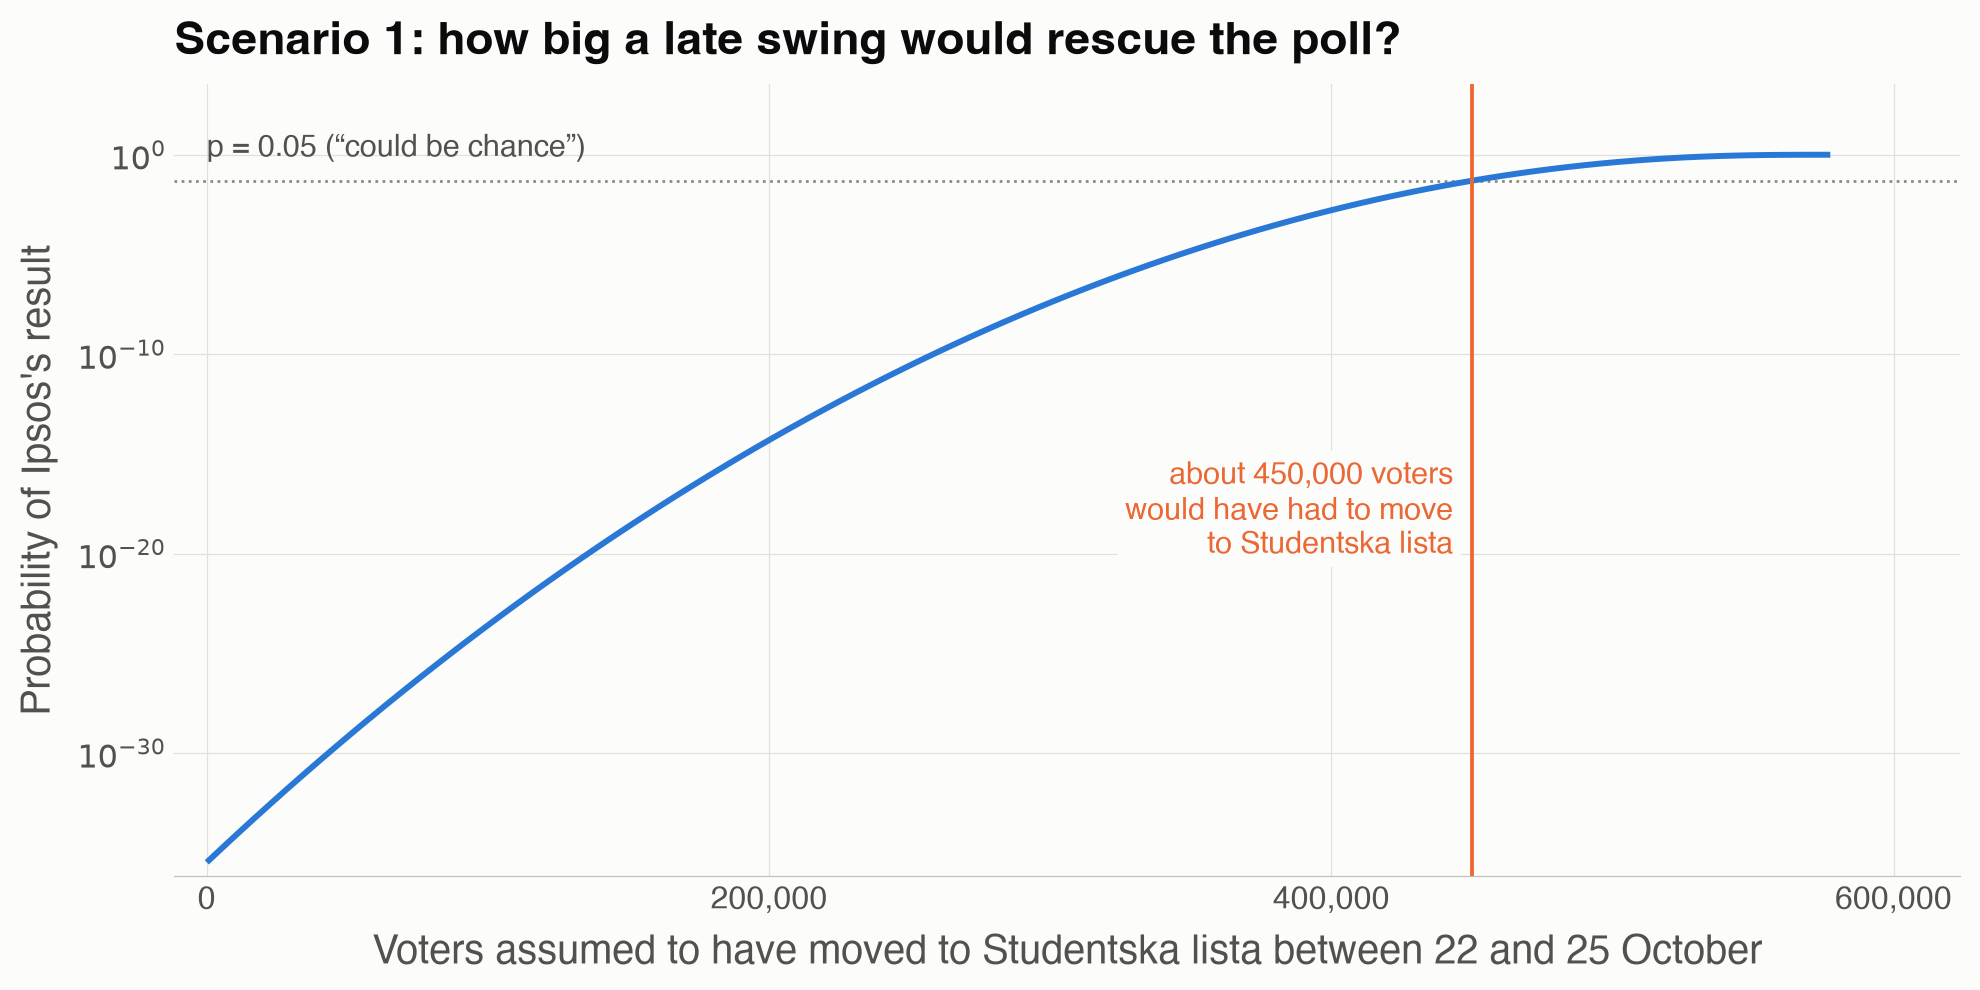

In [52]:
# ---- chunk: fig-swing ----
g = (ggplot(swing_df, aes(x="voters", y="log10_p")) +
     geom_hline(yintercept=np.log10(0.05), linetype="dotted", color="#898781") +
     annotate("text", x=0, y=np.log10(0.05) + 0.8, label="p = 0.05 (“could be chance”)", ha="left", va="bottom", size=10, color="#52514e") +
     geom_line(color="#2a78d6", size=1.1) +
     geom_vline(xintercept=voters_05, color="#eb6834", size=0.7) +
     annotate("label", x=voters_05 * 0.985, y=swing_df["log10_p"].min() * 0.5,
              label=f"about {fmt_n(round(voters_05, -3))} voters\nwould have had to move\nto Studentska lista",
              ha="right", size=10, color="#eb6834", fill="#fcfcfb", label_size=0) +
     scale_x_continuous(labels=comma, expand=(0.02, 0, 0.08, 0)) +
     scale_y_continuous(labels=pow10, expand=(0.02, 0, 0.1, 0)) +
     labs(x="Voters assumed to have moved to Studentska lista between 22 and 25 October",
          y="Probability of Ipsos's result", title="Scenario 1: how big a late swing would rescue the poll?") +
     theme_report(figure_size=(9, 4.5)))
fig(g, "Figure 8. How the probability of Ipsos's result rises as we assume ever more voters moved to Studentska lista after the poll (the electorate drifting from Ipsos's picture towards the actual result).")

In [53]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> For Ipsos's result to have been merely a 1-in-20 unlucky draw, the electorate on 22 October would have had to be <b>{100 * t_05:.0f}% of the way</b> from the actual result to Ipsos's picture, which means that about <b>{fmt_n(round(voters_05, -3))} voters</b> ({fmt_pct(100 * voters_05 / rik_meta["ballots"], 1)} of all ballots cast) would have had to move to <i>Studentska lista</i> in the three days after the fieldwork, roughly {fmt_n(round(from_us(t_05), -3))} of them from <i>Ujedinjena Srbija</i> and the rest voters who would otherwise have backed a small list or cast an invalid ballot. (The figure depends a little on the assumed sample size: between {fmt_n(round(voters_05_by_n.min(), -3))} and {fmt_n(round(voters_05_by_n.max(), -3))} across the range of <i>n</i> used in Section 8.) For Ipsos's poll to have been a typical, median poll, about {fmt_n(round(voters_50, -3))} voters would have had to move. That is a swing of some {100 * voters_05 / rik_meta["ballots"]:.0f} points within 72 hours, in an election where no event of that magnitude was reported between 22 and 25 October; it would mean <i>Ujedinjena Srbija</i> losing about one in {1 / (from_us(t_05) / (p_rik_A.iloc[1] * rik_meta["ballots"] + from_us(t_05))):.0f} of its 22-October supporters by polling day. Late swings of one to three points are common in the polling literature; a swing of this size within three days is, to our knowledge, undocumented in comparable elections. (For what polling error normally looks like across 351 elections in 45 countries, see <a href="https://doi.org/10.1038/s41562-018-0315-6">Jennings &amp; Wlezien, 2018</a>; for a forensic account of an unusually bad polling year and why non-response rather than late swing or turnout models was the likely cause, see the <a href="https://aapor.org/wp-content/uploads/2022/11/AAPOR-Task-Force-on-2020-Pre-Election-Polling_Report-FNL.pdf">AAPOR Task Force report on 2020 U.S. pre-election polls</a>.)
</div>
""")


<div class="callout callout-result">
<b>Result.</b> For Ipsos's result to have been merely a 1-in-20 unlucky draw, the electorate on 22 October would have had to be <b>78% of the way</b> from the actual result to Ipsos's picture, which means that about <b>450,000 voters</b> (10.2% of all ballots cast) would have had to move to <i>Studentska lista</i> in the three days after the fieldwork, roughly 291,000 of them from <i>Ujedinjena Srbija</i> and the rest voters who would otherwise have backed a small list or cast an invalid ballot. (The figure depends a little on the assumed sample size: between 428,000 and 480,000 across the range of <i>n</i> used in Section 8.) For Ipsos's poll to have been a typical, median poll, about 507,000 voters would have had to move. That is a swing of some 10 points within 72 hours, in an election where no event of that magnitude was reported between 22 and 25 October; it would mean <i>Ujedinjena Srbija</i> losing about one in 7 of its 22-October supporters by polling day. Late swings of one to three points are common in the polling literature; a swing of this size within three days is, to our knowledge, undocumented in comparable elections. (For what polling error normally looks like across 351 elections in 45 countries, see <a href="https://doi.org/10.1038/s41562-018-0315-6">Jennings &amp; Wlezien, 2018</a>; for a forensic account of an unusually bad polling year and why non-response rather than late swing or turnout models was the likely cause, see the <a href="https://aapor.org/wp-content/uploads/2022/11/AAPOR-Task-Force-on-2020-Pre-Election-Polling_Report-FNL.pdf">AAPOR Task Force report on 2020 U.S. pre-election polls</a>.)
</div>


## 9.3 Scenario 2: differential turnout (the net surplus)

In [54]:
md(f"""
Ipsos predicted a turnout of {ipsos_turnout["est"]}%; actual turnout was {fmt_pct(rik_meta["turnout_pct"])}. The difference is about **{fmt_n(round((rik_meta["turnout_pct"] - ipsos_turnout["est"]) / 100 * rik_meta["turned_out"] / (rik_meta["turnout_pct"] / 100), -3))} voters** who turned out but whom Ipsos's model expected to stay home. (The two percentages have slightly different bases, Ipsos's being adults in Serbia proper and RIK's registered voters including Kosovo i Metohija and abroad, so this is an approximation; the scenario is deliberately extreme in any case.) Could these "unexpected" voters account for the gap? We take the extreme case for this *net* surplus: **every single one of them voted for *Studentska lista***. Removing them from the count gives the electorate Ipsos thought it was measuring.
""")


Ipsos predicted a turnout of 64.7%; actual turnout was 68.98%. The difference is about **275,000 voters** who turned out but whom Ipsos's model expected to stay home. (The two percentages have slightly different bases, Ipsos's being adults in Serbia proper and RIK's registered voters including Kosovo i Metohija and abroad, so this is an approximation; the scenario is deliberately extreme in any case.) Could these "unexpected" voters account for the gap? We take the extreme case for this *net* surplus: **every single one of them voted for *Studentska lista***. Removing them from the count gives the electorate Ipsos thought it was measuring.


In [55]:
# ---- chunk: turnout ----
registered_processed = rik_meta["turned_out"] / (rik_meta["turnout_pct"] / 100)        # registered voters at the processed stations
extra_voters = (rik_meta["turnout_pct"] - ipsos_turnout["est"]) / 100 * registered_processed
votes_t = scheme_a["votes"].values.astype(float).copy()
votes_t[0] = votes_t[0] - extra_voters                       # all extra voters assumed to be Studentska voters
p_turnout = votes_t / votes_t.sum()
g_turn = g_test(k_ips_A.values, p_turnout)

kable_report(pd.DataFrame({"Category": grp_levels, "RIK % (actual)": [fmt_pct(100 * x) for x in p_rik_A],
                           "% if all extra turnout were Studentska voters": [fmt_pct(100 * x) for x in p_turnout],
                           "Ipsos %": [fmt_pct(x, 1) for x in pct_ips_A]}),
             caption=f"Table 15. Scenario 2: the electorate Ipsos expected, under the extreme assumption that all {fmt_n(round(extra_voters, -3))} voters it did not expect voted Studentska lista.")

Category,RIK % (actual),% if all extra turnout were Studentska voters,Ipsos %
Studentska lista,53.03%,49.93%,40.0%
Ujedinjena Srbija,38.97%,41.55%,47.4%
Manjinske liste,2.16%,2.30%,2.3%
Other,5.84%,6.23%,10.3%


In [56]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> Even in this deliberately extreme scenario, in which the entire turnout surprise consists of <i>Studentska</i> voters, the electorate Ipsos was trying to measure would have had <i>Studentska lista</i> at {fmt_pct(100 * p_turnout[0])} and <i>Ujedinjena Srbija</i> at {fmt_pct(100 * p_turnout[1])}, still a clear Studentska lead and still far from Ipsos's 40.0 / 47.4. The probability of Ipsos's result under this adjusted population is {fmt_log10p(g_turn["log10_p_G"])}. The turnout <i>surplus</i> is not the explanation.

One caveat belongs here. Turnout can also shift a poll without changing the total: if many people who told Ipsos they would vote for <i>Ujedinjena Srbija</i> stayed at home, while an equal number who had said they would <i>not</i> vote turned out for <i>Studentska lista</i>, aggregate turnout is unchanged but the electorate Ipsos modelled is not the one that voted. Such <i>gross</i> flows are a failure of the pollster's likely-voter model rather than of sampling, and they are not observable from the outside; to produce Ipsos's picture they would have to involve several hundred thousand voters swapping places. We treat this, together with the handling of undecided respondents, under Scenario 4 and under non-sampling error in the conclusions.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> Even in this deliberately extreme scenario, in which the entire turnout surprise consists of <i>Studentska</i> voters, the electorate Ipsos was trying to measure would have had <i>Studentska lista</i> at 49.93% and <i>Ujedinjena Srbija</i> at 41.55%, still a clear Studentska lead and still far from Ipsos's 40.0 / 47.4. The probability of Ipsos's result under this adjusted population is 3 × 10<sup>−23</sup> (about 1 in a 3 followed by 22 zeros). The turnout <i>surplus</i> is not the explanation.

One caveat belongs here. Turnout can also shift a poll without changing the total: if many people who told Ipsos they would vote for <i>Ujedinjena Srbija</i> stayed at home, while an equal number who had said they would <i>not</i> vote turned out for <i>Studentska lista</i>, aggregate turnout is unchanged but the electorate Ipsos modelled is not the one that voted. Such <i>gross</i> flows are a failure of the pollster's likely-voter model rather than of sampling, and they are not observable from the outside; to produce Ipsos's picture they would have to involve several hundred thousand voters swapping places. We treat this, together with the handling of undecided respondents, under Scenario 4 and under non-sampling error in the conclusions.
</div>


## 9.4 Scenario 3: both together

Combining the two, an extreme turnout assumption *and* a late swing, how large would the swing still have to be?

In [57]:
# ---- chunk: combined ----
t_05_comb = brentq(lambda t: swing_log10p(t, p_from=p_turnout) - np.log10(0.05), 0, 1)
voters_05_comb = t_05_comb * (p_turnout[0] - p_ips_A.iloc[0]) * votes_t.sum()

In [58]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> With the extreme turnout assumption already in place, a further <b>{fmt_n(round(voters_05_comb, -3))} voters</b> ({fmt_pct(100 * voters_05_comb / votes_t.sum(), 1)} of the remaining ballots) would still have had to move to <i>Studentska lista</i> in three days to bring Ipsos's result up to a 5% probability. The two electorate-side explanations do not add up to an explanation.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> With the extreme turnout assumption already in place, a further <b>298,000 voters</b> (7.2% of the remaining ballots) would still have had to move to <i>Studentska lista</i> in three days to bring Ipsos's result up to a 5% probability. The two electorate-side explanations do not add up to an explanation.
</div>


## 9.5 Scenario 4: undecided voters

In [59]:
md(f"""
Ipsos's percentages describe only the respondents who named a list. Section 6 suggested that this "decided" base was perhaps {100 * n_primary * deff_full / ipsos_n:.0f}% of the sample, leaving roughly a fifth undecided. Suppose Ipsos's decided respondents were a perfect picture of the decided electorate, and that the entire gap arose because the undecided voters, once they made up their minds, voted very differently. How lopsided would their choice have had to be?

If a share *u* of eventual voters was undecided at the time of the poll, the final result is (1 − *u*) × (Ipsos's decided picture) + *u* × (how the undecided voted). Knowing the final result and Ipsos's picture, we can solve for the third term.
""")


Ipsos's percentages describe only the respondents who named a list. Section 6 suggested that this "decided" base was perhaps 78% of the sample, leaving roughly a fifth undecided. Suppose Ipsos's decided respondents were a perfect picture of the decided electorate, and that the entire gap arose because the undecided voters, once they made up their minds, voted very differently. How lopsided would their choice have had to be?

If a share *u* of eventual voters was undecided at the time of the poll, the final result is (1 − *u*) × (Ipsos's decided picture) + *u* × (how the undecided voted). Knowing the final result and Ipsos's picture, we can solve for the third term.


In [60]:
# ---- chunk: undecided ----
rows = []
for u in [0.20, 0.25, 0.30, 0.40, 0.50]:
    q = (p_rik_A.values - (1 - u) * p_ips_A.values) / u          # how the undecided must have voted
    rows.append({"u": u, "Studentska lista": 100 * q[0], "Ujedinjena Srbija": 100 * q[1], "Manjinske liste": 100 * q[2], "Other": 100 * q[3]})
undec = pd.DataFrame(rows)
kable_report(pd.DataFrame({"Undecided share": undec["u"].map(lambda u: fmt_pct(100 * u, 0)),
                           **{c: undec[c].map(lambda x: f"{x:.0f}%".replace("-", "−")) for c in undec.columns[1:]}}),
             caption="Table 16. Scenario 4: how the undecided voters would have had to split for Ipsos's decided picture to have been exactly right. Negative values are impossible.")

Undecided share,Studentska lista,Ujedinjena Srbija,Manjinske liste,Other
20%,105%,5%,2%,−12%
25%,92%,14%,2%,−8%
30%,83%,19%,2%,−5%
40%,73%,26%,2%,−1%
50%,66%,31%,2%,1%


In [61]:
md(f"""
<div class="callout callout-result">
<b>Result.</b> If a fifth of the eventual voters were undecided when Ipsos polled, no split works at all: they would have had to vote <i>more than 100%</i> for <i>Studentska lista</i>. With a quarter undecided they would have had to vote <b>{undec["Studentska lista"][1]:.0f}% for <i>Studentska lista</i></b> and {undec["Ujedinjena Srbija"][1]:.0f}% for <i>Ujedinjena Srbija</i>; with a third undecided, {undec["Studentska lista"][2]:.0f}% and {undec["Ujedinjena Srbija"][2]:.0f}%. And in every row up to about 40% undecided the small lists come out <i>negative</i>: because Ipsos put the small lists and invalid ballots too high as well, no split of the undecided voters can reconcile the whole vector; they would have had to take votes <i>away</i> from the small lists, which is impossible. Undecided voters do break unevenly in real elections, and a late-deciding bloc favouring a protest movement is entirely plausible; a bloc of this size voting almost unanimously is not what the literature describes. This scenario is also, like the previous two, the most generous reading possible: it assumes Ipsos's decided respondents were a perfect sample, with zero sampling error of their own.
</div>
""")


<div class="callout callout-result">
<b>Result.</b> If a fifth of the eventual voters were undecided when Ipsos polled, no split works at all: they would have had to vote <i>more than 100%</i> for <i>Studentska lista</i>. With a quarter undecided they would have had to vote <b>92% for <i>Studentska lista</i></b> and 14% for <i>Ujedinjena Srbija</i>; with a third undecided, 83% and 19%. And in every row up to about 40% undecided the small lists come out <i>negative</i>: because Ipsos put the small lists and invalid ballots too high as well, no split of the undecided voters can reconcile the whole vector; they would have had to take votes <i>away</i> from the small lists, which is impossible. Undecided voters do break unevenly in real elections, and a late-deciding bloc favouring a protest movement is entirely plausible; a bloc of this size voting almost unanimously is not what the literature describes. This scenario is also, like the previous two, the most generous reading possible: it assumes Ipsos's decided respondents were a perfect sample, with zero sampling error of their own.
</div>


# 10 Summary and conclusions

## 10.1 What we did

In [62]:
md(f"""
1. **Collected both records.** Ipsos's final estimate of 22 October 2026 (n = 3,624; *Ujedinjena Srbija* 47.4%, *Studentska lista* 40.0%, with 95% intervals of about ±2.1 points, commissioned by the *Ujedinjena Srbija* list) and RIK's count as of 31 October 2026 (8,339 of 8,392 polling stations; *Studentska lista* {fmt_pct(scheme_a.rik_pct[0])}, *Ujedinjena Srbija* {fmt_pct(scheme_a.rik_pct[1])}; turnout {fmt_pct(rik_meta["turnout_pct"])}).
2. **Made them comparable.** Both use "all ballots cast" as the base, so no rescaling was needed. We grouped the lists into *Studentska lista*, *Ujedinjena Srbija*, the four *manjinske liste* that entered Parliament, and everything else. Ipsos's error is concentrated in the two large lists, {scheme_a.rik_pct[0] - 40:.1f} points too low for *Studentska lista* and {47.4 - scheme_a.rik_pct[1]:.1f} points too high for *Ujedinjena Srbija*, with the remaining {(scheme_a.ipsos_pct[2:4] - scheme_a.rik_pct[2:4]).sum():.1f} points spread as small overestimates across the minor lists, the minority lists and invalid ballots.
3. **Established the effective sample size** from Ipsos's own confidence intervals: about {fmt_n(n_primary)} decided respondents, the most generous figure the published precision supports.
4. **Computed the probability** of Ipsos's result under the hypothesis that it was a random sample of the actual electorate, in five different ways, including an exact computation that enumerates every possible outcome of the poll, two simulation estimates, and the textbook chi-square approximation.
5. **Stress-tested** the result against every alternative sample size, population definition and base (all ballots versus valid votes).
6. **Quantified** what a late swing, a turnout surprise or a lopsided break of undecided voters would have had to look like to explain the gap.
""")


1. **Collected both records.** Ipsos's final estimate of 22 October 2026 (n = 3,624; *Ujedinjena Srbija* 47.4%, *Studentska lista* 40.0%, with 95% intervals of about ±2.1 points, commissioned by the *Ujedinjena Srbija* list) and RIK's count as of 31 October 2026 (8,339 of 8,392 polling stations; *Studentska lista* 53.03%, *Ujedinjena Srbija* 38.97%; turnout 68.98%).
2. **Made them comparable.** Both use "all ballots cast" as the base, so no rescaling was needed. We grouped the lists into *Studentska lista*, *Ujedinjena Srbija*, the four *manjinske liste* that entered Parliament, and everything else. Ipsos's error is concentrated in the two large lists, 13.0 points too low for *Studentska lista* and 8.4 points too high for *Ujedinjena Srbija*, with the remaining 4.6 points spread as small overestimates across the minor lists, the minority lists and invalid ballots.
3. **Established the effective sample size** from Ipsos's own confidence intervals: about 2,110 decided respondents, the most generous figure the published precision supports.
4. **Computed the probability** of Ipsos's result under the hypothesis that it was a random sample of the actual electorate, in five different ways, including an exact computation that enumerates every possible outcome of the poll, two simulation estimates, and the textbook chi-square approximation.
5. **Stress-tested** the result against every alternative sample size, population definition and base (all ballots versus valid votes).
6. **Quantified** what a late swing, a turnout surprise or a lopsided break of undecided voters would have had to look like to explain the gap.


## 10.2 What we found

In [63]:
md(f"""
<div class="callout callout-result">
<div class="hero">≈ {fmt_log10p(log10_p_exact).split(" (")[0]}</div>
<div class="hero-sub">the probability that a random sample of the people who voted on 25 October 2026 would produce a result at least as far from the truth as Ipsos's published numbers (exact multinomial test, all {fmt_n(enum["n_outcomes"])} possible outcomes enumerated, four categories, n = {fmt_n(n_primary)}; every other method and every variant we tried lands between {fmt_pow(tail_range_all[1])} and {fmt_pow(tail_range_all[0])})</div>

<ul>
<li>Taken one list at a time, the chance of a random sample putting <i>Studentska lista</i> at or below 40.0% when its true share was {fmt_pct(scheme_a.rik_pct[0], 1)} is {fmt_log10p(m2.log10_p[0])}; the chance of putting <i>Ujedinjena Srbija</i> at or above 47.4% when its true share was {fmt_pct(scheme_a.rik_pct[1], 1)} is {fmt_log10p(m2.log10_p[1])}.</li>
<li>Asking for both at once (<i>Studentska lista</i> at or below 40.0% <i>and</i> <i>Ujedinjena Srbija</i> at or above 47.4%) gives {fmt_log10p(np.log10(joint_exact))} exactly. The textbook chi-square approximation gives {fmt_log10p(gA["log10_p_G"])} with four categories and {fmt_log10p(gB["log10_p_G"])} with all lists kept separate.</li>
<li>Among <b>two million</b> simulated ideal random polls from the real electorate, <b>none</b> came close to Ipsos's combination, under any of the definitions of "close" we tried.</li>
<li>The conclusion is unchanged for any sample size from 1,500 to 3,624, whether or not Kosovo i Metohija and the diaspora are removed from the population to match Ipsos's sampling frame, and whether the comparison is made on all ballots or on valid votes only: the probability never rises above about {fmt_pow(max(sens_n["G test (Scheme A)"].max(), g_valid["log10_p_G"], gB_valid["log10_p_G"]))}.</li>
<li>By Ipsos's <b>own</b> published margins of error, the true <i>Studentska lista</i> share lay {own.outside_by[0]:.1f} points outside the top of its 95% interval, {abs(own.z_own[0]):.0f} of its own standard errors from its estimate.</li>
<li>To make Ipsos's result an ordinary 1-in-20 unlucky draw, about <b>{fmt_n(round(voters_05, -3))} voters</b> would have had to move to <i>Studentska lista</i> in the three days between fieldwork and election day; even if every one of the {fmt_n(round(extra_voters, -3))} unexpected extra voters had voted <i>Studentska</i>, a further {fmt_n(round(voters_05_comb, -3))} would still have had to move. If a quarter of voters were undecided at the time of the poll, they would have had to vote {undec["Studentska lista"][1]:.0f}% for <i>Studentska lista</i>, and even then the small-list excess remains unexplained.</li>
</ul>
</div>
""")


<div class="callout callout-result">
<div class="hero">≈ 2 × 10<sup>−36</sup></div>
<div class="hero-sub">the probability that a random sample of the people who voted on 25 October 2026 would produce a result at least as far from the truth as Ipsos's published numbers (exact multinomial test, all 1,570,111,136 possible outcomes enumerated, four categories, n = 2,110; every other method and every variant we tried lands between 10<sup>−30</sup> and 10<sup>−36</sup>)</div>

<ul>
<li>Taken one list at a time, the chance of a random sample putting <i>Studentska lista</i> at or below 40.0% when its true share was 53.0% is 2 × 10<sup>−33</sup> (about 1 in a 4 followed by 32 zeros); the chance of putting <i>Ujedinjena Srbija</i> at or above 47.4% when its true share was 39.0% is 2 × 10<sup>−15</sup> (about 1 in a 4 followed by 14 zeros).</li>
<li>Asking for both at once (<i>Studentska lista</i> at or below 40.0% <i>and</i> <i>Ujedinjena Srbija</i> at or above 47.4%) gives 2 × 10<sup>−33</sup> (about 1 in a 4 followed by 32 zeros) exactly. The textbook chi-square approximation gives 3 × 10<sup>−36</sup> (about 1 in a 3 followed by 35 zeros) with four categories and 1 × 10<sup>−33</sup> (about 1 in a 9 followed by 32 zeros) with all lists kept separate.</li>
<li>Among <b>two million</b> simulated ideal random polls from the real electorate, <b>none</b> came close to Ipsos's combination, under any of the definitions of "close" we tried.</li>
<li>The conclusion is unchanged for any sample size from 1,500 to 3,624, whether or not Kosovo i Metohija and the diaspora are removed from the population to match Ipsos's sampling frame, and whether the comparison is made on all ballots or on valid votes only: the probability never rises above about 10<sup>−25</sup>.</li>
<li>By Ipsos's <b>own</b> published margins of error, the true <i>Studentska lista</i> share lay 10.9 points outside the top of its 95% interval, 12 of its own standard errors from its estimate.</li>
<li>To make Ipsos's result an ordinary 1-in-20 unlucky draw, about <b>450,000 voters</b> would have had to move to <i>Studentska lista</i> in the three days between fieldwork and election day; even if every one of the 275,000 unexpected extra voters had voted <i>Studentska</i>, a further 298,000 would still have had to move. If a quarter of voters were undecided at the time of the poll, they would have had to vote 92% for <i>Studentska lista</i>, and even then the small-list excess remains unexplained.</li>
</ul>
</div>


In [64]:
# ---- chunk: words ----
# the headline exponent in words (short scale, as used in English; long scale, as used in Serbian)
def pow_words(l10):
    # the number 1/p written as  lead × 10^e, then named: e.g. 3 × 10^36 = "three undecillion"
    e = math.floor(-l10); lead = round(10 ** (-l10 - e))
    if lead == 10: lead, e = 1, e + 1
    grp, mult = e // 3, lead * 10 ** (e % 3)                        # mult in 1..900
    short_names = {10: "nonillion", 11: "decillion", 12: "undecillion", 13: "duodecillion"}
    # Serbian forms: singular (1), paucal (2–4), plural (5+)
    long_names = {10: ("kvintilion", "kvintiliona", "kvintiliona"), 11: ("kvintilijarda", "kvintilijarde", "kvintilijardi"),
                  12: ("sekstilion", "sekstiliona", "sekstiliona"), 13: ("sekstilijarda", "sekstilijarde", "sekstilijardi")}
    if grp not in short_names: return f"one in a {lead} followed by {e} zeros"
    en_small = ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
    en_tens  = ["ten", "twenty", "thirty", "forty", "fifty", "sixty", "seventy", "eighty", "ninety"]
    en_mult  = en_small[mult - 1] if mult < 10 else (en_tens[mult // 10 - 1] if mult < 100 else f"{en_small[mult // 100 - 1]} hundred")
    sr_small = ["", "dva", "tri", "četiri", "pet", "šest", "sedam", "osam", "devet"]
    sr_tens  = ["deset", "dvadeset", "trideset", "četrdeset", "pedeset", "šezdeset", "sedamdeset", "osamdeset", "devedeset"]
    sr_hund  = ["sto", "dvesta", "trista", "četiristo", "petsto", "šeststo", "sedamsto", "osamsto", "devetsto"]
    sr_mult  = sr_small[mult - 1] if mult < 10 else (sr_tens[mult // 10 - 1] if mult < 100 else sr_hund[mult // 100 - 1])
    sr_form  = 0 if mult == 1 else (1 if (mult % 10 in (2, 3, 4) and mult % 100 not in (12, 13, 14)) else 2)
    sr_name  = long_names[grp][sr_form]
    return (f"**one in {en_mult} {short_names[grp]}** (a {lead} followed by {e} zeros; in the long-scale naming used in Serbian "
            f"and most of continental Europe, *{(sr_mult + ' ' + sr_name).strip()}*)")

## 10.3 What it means, and what it does not

In [65]:
md(f"""
**Sampling error alone cannot account for the gap.** The hypothesis that Ipsos's published numbers are what a random sample of actual voters would produce, with chance as the only source of discrepancy, is rejected by every method: the exact probability is about {fmt_log10p(log10_p_exact).split(" (")[0]}, that is, roughly {pow_words(log10_p_exact)}. Depending on the definition of "at least as far from the truth", on the test used and on the treatment of invalid ballots, the figure moves between {fmt_pow(tail_range_all[1])} and {fmt_pow(tail_range_all[0])}; at this depth a few powers of ten change nothing. For a sense of scale: picking one specific star at random from all the roughly 10<sup>24</sup> stars in the observable universe is a 1-in-10<sup>24</sup> event, and that is about {fmt_pow(-24 - log10_p_exact)} times *more* likely than Ipsos's result under random sampling. No reasonable choice of sample size, population definition, base or test statistic changes that conclusion. Ipsos's own stated precision leads to the same conclusion without any modelling on our part.

**What the numbers do not establish on their own is the *cause*.** Several candidate explanations remain, and statistics alone cannot pick between them, nor rule out a combination; the evidence in this document bears on each as follows:

- *A genuine late swing.* Possible in principle, and flagged by Ipsos itself as a caveat; but it would have had to involve some {fmt_n(round(voters_05, -3))} voters moving to the student list within 72 hours, among them roughly one in {1 / (from_us(t_05) / (p_rik_A.iloc[1] * rik_meta["ballots"] + from_us(t_05))):.0f} of all *Ujedinjena Srbija* supporters, a movement several times larger than the late swings documented in comparable elections, and one that no other evidence from those three days suggests.
- *Differential turnout.* Ruled out as a sufficient explanation *in its net form*: even the most extreme assumption about the unexpected extra voters leaves the gap essentially intact. Gross flows (intending voters staying home while others turned out) cannot be assessed from outside; they belong under non-sampling error below.
- *Undecided voters.* A quarter of the electorate undecided and then voting {undec["Studentska lista"][1]:.0f}% for one list would reconcile the two big numbers; nothing reconciles the small-list excess. A real but modest contribution is plausible; a full explanation is not.
- *Non-sampling error* (telephone coverage, non-response, concealment of intention, mode and house effects, likely-voter modelling, weighting; see [total survey error](https://en.wikipedia.org/wiki/Total_survey_error)). This is the explanation that the test cannot address directly, and every poll carries some of it. What the test does establish is its required size: a non-sampling bias large enough to explain Ipsos's numbers would have to move the two large lists by 13 and 8 points, a margin error of about 21 points. A [catalogue of 37 documented poll misses from 2010 to 2026](Poll-Misses-2010-2026.html) ranks that fifth-largest overall and third among elections. The larger misses are two referendums (Colombia 2016, Greece 2015) and two polls of the Costa Rican run-off of 2018 published 11 to 16 days before the vote. Among election polls with final-week fieldwork, samples of two thousand or more, a disclosed commissioning party and an undisputed count, it has no counterpart in that catalogue. Ipsos's election-night projection with CeSID was accurate to within a few tenths of a point, but that projection rested on counted ballots at sampled polling stations, not on interviews, so it does not share the pre-election survey's sources of error and does not by itself tell us how large those could have been.
- *Misrepresentation of the published numbers.* The data are consistent with it, exactly as they are consistent with a sufficiently large version of each explanation above; the test cannot separate them. The fact that the poll was commissioned by one of the contestants is a reason to ask for transparency, not evidence of intent, and this document makes no claim about intent.

The defensible public statement is therefore: **Ipsos's final pre-election numbers cannot have arisen from random sampling error. What remains is some combination of a late swing far larger than any for which there is independent evidence, a turnout or undecided-voter shift of a size documented only in a few referendums and one run-off polled more than a week out, a methodological bias far larger than final pre-election polls ordinarily carry, and the published numbers not reflecting what the survey measured.** This document cannot distinguish among these, nor between any of them and misreporting. Doing so requires what a probability calculation cannot supply: Ipsos's raw data, its weighting scheme, its likely-voter model, and its treatment of undecided respondents.
""")


**Sampling error alone cannot account for the gap.** The hypothesis that Ipsos's published numbers are what a random sample of actual voters would produce, with chance as the only source of discrepancy, is rejected by every method: the exact probability is about 2 × 10<sup>−36</sup>, that is, roughly **one in five hundred decillion** (a 5 followed by 35 zeros; in the long-scale naming used in Serbian and most of continental Europe, *petsto kvintilijardi*). Depending on the definition of "at least as far from the truth", on the test used and on the treatment of invalid ballots, the figure moves between 10<sup>−30</sup> and 10<sup>−36</sup>; at this depth a few powers of ten change nothing. For a sense of scale: picking one specific star at random from all the roughly 10<sup>24</sup> stars in the observable universe is a 1-in-10<sup>24</sup> event, and that is about 10<sup>12</sup> times *more* likely than Ipsos's result under random sampling. No reasonable choice of sample size, population definition, base or test statistic changes that conclusion. Ipsos's own stated precision leads to the same conclusion without any modelling on our part.

**What the numbers do not establish on their own is the *cause*.** Several candidate explanations remain, and statistics alone cannot pick between them, nor rule out a combination; the evidence in this document bears on each as follows:

- *A genuine late swing.* Possible in principle, and flagged by Ipsos itself as a caveat; but it would have had to involve some 450,000 voters moving to the student list within 72 hours, among them roughly one in 7 of all *Ujedinjena Srbija* supporters, a movement several times larger than the late swings documented in comparable elections, and one that no other evidence from those three days suggests.
- *Differential turnout.* Ruled out as a sufficient explanation *in its net form*: even the most extreme assumption about the unexpected extra voters leaves the gap essentially intact. Gross flows (intending voters staying home while others turned out) cannot be assessed from outside; they belong under non-sampling error below.
- *Undecided voters.* A quarter of the electorate undecided and then voting 92% for one list would reconcile the two big numbers; nothing reconciles the small-list excess. A real but modest contribution is plausible; a full explanation is not.
- *Non-sampling error* (telephone coverage, non-response, concealment of intention, mode and house effects, likely-voter modelling, weighting; see [total survey error](https://en.wikipedia.org/wiki/Total_survey_error)). This is the explanation that the test cannot address directly, and every poll carries some of it. What the test does establish is its required size: a non-sampling bias large enough to explain Ipsos's numbers would have to move the two large lists by 13 and 8 points, a margin error of about 21 points. A [catalogue of 37 documented poll misses from 2010 to 2026](Poll-Misses-2010-2026.html) ranks that fifth-largest overall and third among elections. The larger misses are two referendums (Colombia 2016, Greece 2015) and two polls of the Costa Rican run-off of 2018 published 11 to 16 days before the vote. Among election polls with final-week fieldwork, samples of two thousand or more, a disclosed commissioning party and an undisputed count, it has no counterpart in that catalogue. Ipsos's election-night projection with CeSID was accurate to within a few tenths of a point, but that projection rested on counted ballots at sampled polling stations, not on interviews, so it does not share the pre-election survey's sources of error and does not by itself tell us how large those could have been.
- *Misrepresentation of the published numbers.* The data are consistent with it, exactly as they are consistent with a sufficiently large version of each explanation above; the test cannot separate them. The fact that the poll was commissioned by one of the contestants is a reason to ask for transparency, not evidence of intent, and this document makes no claim about intent.

The defensible public statement is therefore: **Ipsos's final pre-election numbers cannot have arisen from random sampling error. What remains is some combination of a late swing far larger than any for which there is independent evidence, a turnout or undecided-voter shift of a size documented only in a few referendums and one run-off polled more than a week out, a methodological bias far larger than final pre-election polls ordinarily carry, and the published numbers not reflecting what the survey measured.** This document cannot distinguish among these, nor between any of them and misreporting. Doing so requires what a probability calculation cannot supply: Ipsos's raw data, its weighting scheme, its likely-voter model, and its treatment of undecided respondents.


## 10.4 Caveats

In [66]:
md(f"""
- RIK's results used here are **preliminary** ({fmt_n(rik_meta["stations_done"])} of {fmt_n(rik_meta["stations_total"])} polling stations, snapshot of {rik_meta["snapshot"]}), and they are taken as the truth throughout. The outstanding {100 * (1 - rik_meta["stations_done"] / rik_meta["stations_total"]):.1f}% of polling stations cannot move the national shares by more than a few tenths of a point. Re-knitting this document with the final figures entered in Section 3 will update every computed number automatically.
- The effective sample size is inferred from Ipsos's published intervals, not stated by Ipsos. The sensitivity analysis shows the conclusion is insensitive to it. The counts "out of {fmt_n(n_primary)}" are a construction that matches the precision of Ipsos's intervals, not interviews Ipsos actually conducted.
- The headline figure is computed exactly, by enumeration, and carries no simulation error. The chi-square figures are asymptotic approximations and are read as orders of magnitude; Pearson's chi-square is reported for completeness but is known to be unreliable this far into the tail. The importance-sampling estimate is reported only to document that, with a proposal centred on Ipsos's numbers, it undercounts the tail by a factor of about {10 ** (log10_p_exact - log10_p_is):.0f} (its runs spread over {is_spread[1] - is_spread[0]:.1f} in the exponent, which understates its true error).
- Ipsos's percentages are published to one decimal place; converting them to counts introduces errors of up to about one respondent per category, which is immaterial in Scheme A but a reason to treat the smallest Scheme B cells as indicative only.
- Ipsos's assumed 2.5% invalid share is not a sampled quantity; Section 8 shows the effect of removing it from the comparison (a few powers of ten, conclusion unchanged).
- Minority lists are defined here as the four that won seats. Other lists representing national minorities (e.g. *Zukorlić (SPP)*) are in the "Other" category in both sources, so the comparison is consistent.
""")


- RIK's results used here are **preliminary** (8,339 of 8,392 polling stations, snapshot of 31 October 2026, 11:00 CET), and they are taken as the truth throughout. The outstanding 0.6% of polling stations cannot move the national shares by more than a few tenths of a point. Re-knitting this document with the final figures entered in Section 3 will update every computed number automatically.
- The effective sample size is inferred from Ipsos's published intervals, not stated by Ipsos. The sensitivity analysis shows the conclusion is insensitive to it. The counts "out of 2,110" are a construction that matches the precision of Ipsos's intervals, not interviews Ipsos actually conducted.
- The headline figure is computed exactly, by enumeration, and carries no simulation error. The chi-square figures are asymptotic approximations and are read as orders of magnitude; Pearson's chi-square is reported for completeness but is known to be unreliable this far into the tail. The importance-sampling estimate is reported only to document that, with a proposal centred on Ipsos's numbers, it undercounts the tail by a factor of about 14 (its runs spread over 0.4 in the exponent, which understates its true error).
- Ipsos's percentages are published to one decimal place; converting them to counts introduces errors of up to about one respondent per category, which is immaterial in Scheme A but a reason to treat the smallest Scheme B cells as indicative only.
- Ipsos's assumed 2.5% invalid share is not a sampled quantity; Section 8 shows the effect of removing it from the comparison (a few powers of ten, conclusion unchanged).
- Minority lists are defined here as the four that won seats. Other lists representing national minorities (e.g. *Zukorlić (SPP)*) are in the "Other" category in both sources, so the comparison is consistent.


# 11 Appendix

## 11.1 Sources

- Ipsos Strategic Marketing, *Rezultati istraživanja pred parlamentarne izbore – oktobar 2026*, press release of 22 October 2026. [PDF](https://www.ipsos.com/sites/default/files/ct/news/documents/2026-10/Saopstenje_-_Ipsos_Strategic_Marketing_-_Parlamentarni%20Izbori_2026_-_finalna_procena.pdf) · [web page](https://www.ipsos.com/sr-rs/rezultati-istrazivanja-pred-parlamentarne-izbore-oktobar-2026)
- Republička izborna komisija, [*Rezultati izbora* portal](https://www.rik.parlament.gov.rs/542645/rezultati/), Парламентарни 2026, read 31 October 2026, 11:00 CET; regional sub-totals for Косово и Метохија and Иностранство from the same portal; diaspora valid/invalid split from the [RIK 73rd session](https://www.rik.parlament.gov.rs/vest/818648/73-sednica-republicke-izborne-komisije.php), 29 October 2026.
- CeSID–Ipsos election-night projection (*Studentska lista* 52.9%, *Ujedinjena Srbija* 38.8%), as reported by [Balkan Insight](https://balkaninsight.com/2026/10/26/student-list-wins-outright-majority-in-serbian-parliamentary-polls/bi/), 26 October 2026.
- Davis, A. (2019). *pmultinom: One-Sided Multinomial Probabilities.* R package.

<a id="references"></a>
## 11.2 References

For every statistical and methodological concept used above, one or two sound, readable resources and the corresponding Wikipedia article. All links were checked on 31 October 2026.

**Probability distributions**

- *Multinomial distribution.* Blitzstein, J. K. & Hwang, J. (2019). *Introduction to Probability*, 2nd ed., ch. 7 "Joint distributions". Free online at [probabilitybook.net](http://probabilitybook.net) · Weisstein, E. W., [*Multinomial Distribution*](https://mathworld.wolfram.com/MultinomialDistribution.html), Wolfram MathWorld (formulas incl. covariance) · [Wikipedia](https://en.wikipedia.org/wiki/Multinomial_distribution).
- *Binomial distribution and its normal approximation.* [Seeing Theory, ch. 3 "Probability Distributions"](https://seeing-theory.brown.edu/probability-distributions/index.html), Brown University (interactive) · [Wikipedia](https://en.wikipedia.org/wiki/Binomial_distribution).
- *Multinomial cumulative probabilities (the `pmultinom` algorithm).* Levin, B. (1981). A representation for multinomial cumulative distribution functions. *Annals of Statistics* 9(5), 1123–1126. [doi:10.1214/aos/1176345593](https://doi.org/10.1214/aos/1176345593) · Davis, A. *pmultinom: One-Sided Multinomial Probabilities*, R package, [CRAN](https://cran.r-project.org/package=pmultinom).

**Sampling error, confidence intervals, sample size**

- *Standard error and confidence interval for a proportion.* [Seeing Theory, ch. 4 "Frequentist Inference"](https://seeing-theory.brown.edu/frequentist-inference/index.html) (interactive) · [Wikipedia: Binomial proportion confidence interval](https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval).
- *Margin of error in polls.* Pew Research Center (2016), [*Understanding the margin of error in election polls*](https://www.pewresearch.org/short-reads/2016/09/08/understanding-the-margin-of-error-in-election-polls/) · [Wikipedia](https://en.wikipedia.org/wiki/Margin_of_error).
- *Design effect and effective sample size.* Zipf, G. & Valliant, R., [*Design Effects and Effective Sample Size*](https://cran.r-project.org/web/packages/PracTools/vignettes/Design-effects.html), PracTools vignette (CRAN) · Kish, L. (1965). *Survey Sampling*. Wiley (the original source of the weighting design-effect formula) · [Wikipedia](https://en.wikipedia.org/wiki/Design_effect).
- *z-scores and "sigma" levels.* [Wikipedia: Standard score](https://en.wikipedia.org/wiki/Standard_score) · [Wikipedia: 68–95–99.7 rule](https://en.wikipedia.org/wiki/68%E2%80%9395%E2%80%9399.7_rule).

**Hypothesis testing**

- *p-values and tail probabilities.* Wasserstein, R. L. & Lazar, N. A. (2016). The ASA Statement on p-Values: Context, Process, and Purpose. *The American Statistician* 70(2), 129–133. [doi:10.1080/00031305.2016.1154108](https://doi.org/10.1080/00031305.2016.1154108) (free access) · [Wikipedia](https://en.wikipedia.org/wiki/P-value).
- *Goodness-of-fit tests (Pearson chi-square, G / likelihood-ratio) and the chi-square distribution.* McDonald, J. H. (2014). *Handbook of Biological Statistics*, 3rd ed.: [Chi-square test of goodness-of-fit](https://www.biostathandbook.com/chigof.html), [G-test of goodness-of-fit](https://www.biostathandbook.com/gtestgof.html), [Small numbers in chi-square and G-tests](https://www.biostathandbook.com/small.html) · Wikipedia: [Goodness of fit](https://en.wikipedia.org/wiki/Goodness_of_fit), [Pearson's chi-squared test](https://en.wikipedia.org/wiki/Pearson%27s_chi-squared_test), [G-test](https://en.wikipedia.org/wiki/G-test), [Likelihood-ratio test](https://en.wikipedia.org/wiki/Likelihood-ratio_test), [Chi-squared distribution](https://en.wikipedia.org/wiki/Chi-squared_distribution).
- *Exact tests and Monte Carlo (simulation-based) p-values.* Downey, A. (2011), [*There is only one test!*](http://allendowney.blogspot.com/2011/05/there-is-only-one-test.html) · VanderPlas, J. (2016), [*Statistics for Hackers*](https://speakerdeck.com/jakevdp/statistics-for-hackers), PyCon ([video](https://www.youtube.com/watch?v=Iq9DzN6mvYA)) · Wikipedia: [Exact test](https://en.wikipedia.org/wiki/Exact_test), [Monte Carlo method](https://en.wikipedia.org/wiki/Monte_Carlo_method).
- *Importance sampling (estimating very small probabilities by simulation).* Owen, A. B. (2013), *Monte Carlo theory, methods and examples*, ch. 9 "Importance sampling", free online at [artowen.su.domains/mc](https://artowen.su.domains/mc/) · [Wikipedia](https://en.wikipedia.org/wiki/Importance_sampling).
- *Asymptotic (large-sample) approximations and their limits in the far tail.* [Wikipedia: Asymptotic distribution](https://en.wikipedia.org/wiki/Asymptotic_distribution) · the G statistic's exact tail behaviour follows from [Sanov's theorem](https://en.wikipedia.org/wiki/Sanov%27s_theorem) (Wikipedia).
- *Why probabilities are computed in logarithms.* [Wikipedia: Arithmetic underflow](https://en.wikipedia.org/wiki/Arithmetic_underflow).

**Polling methodology**

- *Sampling vs non-sampling error.* Groves, R. M. & Lyberg, L. (2010). Total survey error: past, present, and future. *Public Opinion Quarterly* 74(5), 849–879 · [Wikipedia: Total survey error](https://en.wikipedia.org/wiki/Total_survey_error).
- *How large polling errors normally are; late swings.* Jennings, W. & Wlezien, C. (2018). Election polling errors across time and space. *Nature Human Behaviour* 2, 276–283. [doi:10.1038/s41562-018-0315-6](https://doi.org/10.1038/s41562-018-0315-6) (30,000+ polls, 351 elections, 45 countries).
- *Diagnosing a polling miss (non-response, turnout models, "shy" voters).* AAPOR Task Force (2021), [*2020 Pre-Election Polling: An Evaluation of the 2020 General Election Polls*](https://aapor.org/wp-content/uploads/2022/11/AAPOR-Task-Force-on-2020-Pre-Election-Polling_Report-FNL.pdf).
- *Turnout and likely-voter models.* Keeter, S. & Igielnik, R. (2016), [*Can Likely U.S. Voter Models Be Improved?*](https://www.pewresearch.org/methods/2016/01/07/can-likely-voter-models-be-improved/), Pew Research Center.

## 11.3 Reproducibility

In [67]:
# ---- chunk: session-info ----
import platform, scipy, matplotlib, plotnine
print(f"Python {platform.python_version()} on {platform.platform()}")
for m in (np, scipy, pd, matplotlib, plotnine):
    print(f"{m.__name__:<12}{m.__version__}")

Python 3.14.6 on macOS-26.6.2-arm64-arm-64bit-Mach-O
numpy       2.5.4
scipy       1.18.1
pandas      3.1.0
matplotlib  3.11.2
plotnine    0.15.8
